![STREAMLINE](https://github.com/UrbsLab/STREAMLINE/blob/main/docs/source/pictures/STREAMLINE_Logo_Full.png?raw=true)

# STREAMLINE Google Colab Notebook

STREAMLINE is an end-to-end automated machine learning workflow that helps users run, interpret, and apply a rigorous tabular-data analysis without hand-building every preprocessing, modeling, evaluation, and reporting step.

This notebook runs the full pipeline on one of the included UCI demos or on uploaded custom data. It is intentionally explanation-heavy: the top half is the normal editing surface for users, and the phase cells below show exactly how the notebook maps those settings into STREAMLINE runners.

Included demos:

- `demo_binary`: HCC Survival binary classification
- `demo_multiclass`: Student Dropout and Academic Success multiclass classification
- `demo_regression`: Auto MPG regression

Custom modes:

- `custom_classification`
- `custom_regression`

What to expect when running a demo as-is:

- STREAMLINE will clone the latest selected branch, install dependencies, and run phases 1-11.
- The demo configuration uses 3 CV folds and a compact model list so the notebook finishes in a reasonable Colab session.
- Normal demo data folders contain deterministic 80% training splits; matching replication folders contain held-out 20% replication splits.
- At the end, the notebook prints report locations and can download the PDF report(s) and zipped experiment folder.


## Run Instructions

### Demo Run

1. Leave `RUN_MODE` set to one of the `demo_*` values.
2. Choose **Runtime > Run all**.
3. When the run finishes, download the PDF reports and zipped experiment folder from the output cells at the bottom.

You can optionally change non-dataset parameters below, such as the number of CV folds, which phases run, or which modeling algorithms are used.

### Custom Dataset Run: Prompt/Upload Mode

1. Set `RUN_MODE` to `custom_classification` or `custom_regression`.
2. Leave `USE_DATA_PROMPT = True`.
3. Choose **Runtime > Run all**.
4. When prompted, upload one or more target datasets and optional replication datasets.

The prompt flow asks for the essential dataset labels that STREAMLINE needs: outcome/class column, optional instance ID, optional match/group column, and classification type when relevant.

### Custom Dataset Run: Manual Path Mode

1. Set `RUN_MODE` to `custom_classification` or `custom_regression`.
2. Set `USE_DATA_PROMPT = False`.
3. Update the `CUSTOM_*` path and label parameters below.
4. Run all cells.

The notebook defaults are tuned for demo/tutorial runtime in Colab. For fuller research runs, increase `P6_N_TRIALS` and `P6_TIMEOUT` or use a config/CLI run outside Colab.


--------------
## Essential Run Parameters

Most users only need to edit this section and the custom-data section when running non-demo data.

`RUN_MODE`, `OUTPUT_PATH`, and `EXPERIMENT_NAME` decide what is analyzed and where outputs are written. Additional phase parameters below can be changed to alter preprocessing, feature engineering, modeling, and reporting behavior.


### شرح إعداد التشغيل (Run Mode)

- `RUN_MODE`: يحدد نوع التجربة التي سيشغلها STREAMLINE. القيمة `demo_multiclass` تعني تجربة تصنيف متعدد الفئات (بيانات نجاح/انسحاب/تعثر الطلاب مثلًا).
- الخيارات `demo_binary` تصنيف فئتين، و`demo_regression` توقع رقم مستمر، و`custom_classification` أو `custom_regression` لبياناتك.
- `USE_DATA_PROMPT=True`: في وضع البيانات الخاصة يطلب منك Colab رفع الملفات والإجابة عن أسماء الأعمدة. إذا جعلتها `False` تستخدم المسارات اليدوية أدناه.
- `OUTPUT_PATH`: المجلد الذي تحفظ فيه النتائج، و`EXPERIMENT_NAME`: اسم مجلد التجربة.
**الفائدة:** اختيار نوع المهمة ومكان حفظ المخرجات قبل بدء العمل.

### شرح هذه الخلية: اختيار طريقة تشغيل المشروع
- `RUN_MODE = "demo_multiclass"`: يختار تجربة تصنيف متعددة الفئات جاهزة. يعني أن العمود المستهدف يحتوي أكثر من فئة.
- الخيارات الأخرى: `demo_binary` تصنيف ثنائي، و`demo_regression` توقع قيمة رقمية، و`custom_*` لتشغيل بياناتك أنت.
- `USE_DATA_PROMPT = True`: في وضع البيانات المخصصة، يساعد Colab على رفع الملفات والإجابة عن أسئلة الإعداد أثناء التشغيل.
- **ماذا أشرح للدكتور؟** هذه الخلية هي لوحة التحكم الأولى التي أحدد منها نوع التجربة قبل تشغيل مراحل التحليل.

In [1]:
# [run] section: choose which built-in demo or custom workflow to run.
RUN_MODE = "demo_multiclass"
# Supported values:
# - demo_binary
# - demo_multiclass
# - demo_regression
# - custom_classification
# - custom_regression
# Backward-compatible alias: demo_classification -> demo_multiclass

# Colab-only helper for custom modes. Demo modes ignore this.
# True: upload files and answer prompts during Run all.
# False: use the manual CUSTOM_* paths below.
USE_DATA_PROMPT = True

# [run] output_path / experiment_name
OUTPUT_PATH = "/content/streamline_output"
EXPERIMENT_NAME = "ColabRun"


## Custom Data Paths

Used only when `RUN_MODE` is `custom_classification` or `custom_regression` and `USE_DATA_PROMPT = False`.

Target data folders may contain one or more `.csv`, `.tsv`, or `.txt` datasets. All datasets in the same run should use the same outcome, instance, and match column names. Replication data is optional, but when supplied it should have the same feature schema expected by the trained models.

- `CUSTOM_DATA_PATH`: folder containing target datasets
- `CUSTOM_REPLICATION_PATH`: folder containing optional replication datasets
- `CUSTOM_DATASET_FOR_REP`: one target dataset file used to align replication evaluation
- `CUSTOM_CATEGORICAL_FEATURES` / `CUSTOM_QUANTITATIVE_FEATURES`: optional feature-list files or Python lists

If categorical/quantitative feature lists are left as `None`, STREAMLINE uses `P1_CATEGORICAL_CUTOFF` and binary-feature detection to infer feature types.


### شرح مسارات البيانات

- `CUSTOM_DATA_PATH`: مجلد البيانات الأساسية التي سيحللها النظام.
- `CUSTOM_REPLICATION_PATH`: مجلد بيانات إضافية مستقلة لاختبار النموذج لاحقًا (اختياري).
- `CUSTOM_DATASET_FOR_REP`: ملف من البيانات الأساسية يستخدم لمواءمة اختبار التكرار.
- `CUSTOM_CATEGORICAL_FEATURES` و`CUSTOM_QUANTITATIVE_FEATURES`: قوائم تحدد الأعمدة الفئوية والرقمية يدويًا؛ `None` تعني أن STREAMLINE سيستنتج أنواعها تلقائيًا.
**الفائدة:** تعريف مكان الملفات ونوع خصائصها عند تشغيل بياناتك الخاصة.

### شرح هذه الخلية: تحديد مكان ملفات البيانات
- `CUSTOM_DATA_PATH`: مجلد بيانات التدريب/التحليل المخصصة.
- `CUSTOM_REPLICATION_PATH`: مجلد بيانات مستقلة لاختبار قابلية تكرار النتائج.
- `CUSTOM_DATASET_FOR_REP`: ملف البيانات الذي سيستخدم مرجعًا في مرحلة التحقق الخارجي.
- `CUSTOM_CATEGORICAL_FEATURES` و`CUSTOM_QUANTITATIVE_FEATURES`: لتحديد الأعمدة الفئوية والرقمية يدويًا؛ `None` يعني ترك النظام يتعامل معها تلقائيًا.
- هذه المسارات لا تُستخدم عادةً في وضع Demo.

In [2]:
CUSTOM_DATA_PATH = "/content/my_target_data"
CUSTOM_REPLICATION_PATH = "/content/my_replication_data"
CUSTOM_DATASET_FOR_REP = "/content/my_target_data/my_train_dataset.csv"
CUSTOM_CATEGORICAL_FEATURES = None
CUSTOM_QUANTITATIVE_FEATURES = None


## Custom Labels and Task Controls

Used only for custom modes.

- `CUSTOM_OUTCOME_LABEL`: target/outcome column in your data
- `CUSTOM_INSTANCE_LABEL`: optional unique row/sample id column; use `None` if absent
- `CUSTOM_MATCH_LABEL`: optional match/group column for grouped CV or aligned replication; use `None` if absent
- `CUSTOM_CLASSIFICATION_TYPE`: `Binary` or `Multiclass`
- model strings use STREAMLINE model ids such as `NB,LR,DT,RF,CGB,ExSTraCS`

For regression runs, `CUSTOM_OUTCOME_LABEL` should identify a continuous outcome and `CUSTOM_REGRESSION_MODELS` controls the Phase 6 model list.


### شرح أسماء الأعمدة ونوع المهمة

- `CUSTOM_OUTCOME_LABEL`: اسم العمود الذي نريد للنموذج توقعه؛ هنا `Class`. يجب أن يطابق الاسم في ملف CSV حرفيًا.
- `CUSTOM_INSTANCE_LABEL`: معرف فريد لكل صف، مثل StudentID؛ `None` إذا لا يوجد.
- `CUSTOM_MATCH_LABEL`: عمود مجموعة/مطابقة عند الحاجة إلى تقسيم مجموعات أو ربط بيانات التكرار.
- `CUSTOM_CLASSIFICATION_TYPE`: إما `Binary` لفئتين أو `Multiclass` لأكثر من فئتين.
- `CUSTOM_CLASSIFICATION_MODELS`: نماذج التصنيف الافتراضية: NB وLR وDT.
- `CUSTOM_REGRESSION_MODELS`: نماذج الانحدار عند توقع قيمة رقمية.
**الفائدة:** إخبار النظام بما يتنبأ به وكيف يتعامل مع الصفوف والنماذج.

### شرح هذه الخلية: تعريف العمود الهدف ونوع النماذج
- `CUSTOM_OUTCOME_LABEL = "Class"`: اسم العمود الذي نريد التنبؤ به، ويجب أن يطابق اسم العمود في CSV حرفيًا.
- `CUSTOM_INSTANCE_LABEL` و`CUSTOM_MATCH_LABEL`: أعمدة اختيارية لتعريف السجل أو مطابقة البيانات.
- `CUSTOM_CLASSIFICATION_TYPE`: يحدد Binary أو Multiclass.
- `CUSTOM_CLASSIFICATION_MODELS`: النماذج المطلوبة للتصنيف (NB=Naive Bayes، LR=Logistic Regression، DT=Decision Tree).
- `CUSTOM_REGRESSION_MODELS`: نماذج الانحدار (LR وRF).

In [3]:
CUSTOM_OUTCOME_LABEL = "Class"
CUSTOM_INSTANCE_LABEL = None
CUSTOM_MATCH_LABEL = None

CUSTOM_CLASSIFICATION_TYPE = "Binary"   # Binary or Multiclass
CUSTOM_CLASSIFICATION_MODELS = "NB,LR,DT"
CUSTOM_REGRESSION_MODELS = "LR,RF"


--------------
## Global Execution Parameters

These settings affect the full pipeline.

- `RUN_CLUSTER`: `Serial` is recommended in Colab. `Parallel` uses local joblib. `Local` uses local Dask.
- `N_SPLITS`: number of CV train/test partitions and therefore the number of model evaluations per algorithm.
- `RANDOM_STATE`: reproducibility control used across phases when supported.
- `P1_FORCE`: rebuilds the experiment folder when Phase 1 is rerun.

For Colab, prefer `Serial` unless you are deliberately testing local parallel behavior. For small notebook demos, parallel startup overhead can be larger than the saved time.


### شرح إعدادات التنفيذ العامة

- `RUN_CLUSTER='Serial'`: تنفيذ المهام بالتتابع، وهو الخيار الأبسط والأكثر ملاءمة عادةً لـColab.
- `QUEUE` و`RESERVED_MEMORY`: إعدادات إدارة المهام والذاكرة لبعض طرق التشغيل؛ الذاكرة هنا 4 GB.
- `N_SPLITS=3`: استخدام 3 طيات في التحقق المتقاطع Cross Validation.
- `RANDOM_STATE=42`: تثبيت العشوائية لتقريب إعادة إنتاج النتائج في التشغيلات اللاحقة.
- `PHASE_QUEUE` و`PHASE_RESERVED_MEMORY_GB`: أسماء بديلة تمرر الإعدادات إلى مراحل المشروع.
**الفائدة:** التحكم بطريقة التنفيذ، وتقسيم التقييم، وثبات النتائج قدر الإمكان.

### شرح هذه الخلية: إعدادات التنفيذ العامة
- `RUN_CLUSTER`: طريقة تنفيذ المهام؛ `Serial` يعني تنفيذًا متتابعًا على الجهاز الحالي.
- `QUEUE` و`RESERVED_MEMORY`: إعدادات موارد لبعض بيئات التنفيذ/المهام.
- `N_SPLITS = 3`: تقسيم البيانات إلى 3 أجزاء في التحقق المتقاطع Cross Validation.
- `RANDOM_STATE = 42`: تثبيت العشوائية لتقارب النتائج عند إعادة التشغيل.
- `PHASE_QUEUE` و`PHASE_RESERVED_MEMORY_GB`: نسخ من الإعدادات لتستخدمها مراحل المشروع.

In [4]:
# [run] execution parameters
RUN_CLUSTER = "Serial"  # Serial, Parallel (joblib), Local (Dask), BashSLURM, BashLSF, or a named Dask cluster
QUEUE = "defq"
RESERVED_MEMORY = 4
N_SPLITS = 3
RANDOM_STATE = 42

# Kept as aliases because runner cells use PHASE_* names.
PHASE_QUEUE = QUEUE
PHASE_RESERVED_MEMORY_GB = RESERVED_MEMORY


## Phase Toggles

Toggle any phase on/off during iterative debugging. For a complete fresh run, leave everything `True`.

- `p1`-`p11` correspond to the STREAMLINE phases.
- `p11` controls the standard testing-data report.
- `p11_replication` controls the replication report.

If you skip an upstream phase, make sure its expected output already exists from a previous run.


### شرح تفعيل المراحل

- `PHASE_ORDER`: ترتيب مراحل STREAMLINE من P1 إلى P11.
- `RUN_PHASES`: قاموس يحدد تشغيل كل مرحلة؛ `True` يشغلها و`False` يتجاوزها.
- `p11_replication`: تفعيل تقرير بيانات التكرار.
- `ALLOW_P7_FOR_REGRESSION=False`: يمنع دمج النماذج في مسائل الانحدار افتراضيًا.
**تنبيه:** عند تجاوز مرحلة، يجب أن تكون ملفات نتائجها موجودة مسبقًا إذا احتاجتها مرحلة لاحقة.
**الفائدة:** تشغيل كامل المسار أو تعطيل مرحلة أثناء التجربة/تصحيح الأخطاء.

### شرح هذه الخلية: تحديد مراحل سير العمل
- `PHASE_ORDER`: ترتيب مراحل STREAMLINE من P1 إلى P11.
- `RUN_PHASES`: قيمة `True` تعني تشغيل المرحلة، و`False` تعني تجاوزها.
- `p11_replication`: تشغيل تقرير/مسار التكرار.
- `ALLOW_P7_FOR_REGRESSION = False`: يمنع تشغيل التجميع Ensemble افتراضيًا مع الانحدار؛ يمكن تغييره إذا كان مطلوبًا.

In [5]:
# [phases] section
PHASE_ORDER = "p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11"
RUN_PHASES = {
    "p1": True,
    "p2": True,
    "p3": True,
    "p4": True,
    "p5": True,
    "p6": True,
    "p7": True,
    "p8": True,
    "p9": True,
    "p10": True,
    "p11": True,
    "p11_replication": True,
}

# For regression, set True only if you explicitly want to run ensembles.
ALLOW_P7_FOR_REGRESSION = False


--------------
### Phase 1 - Data Exploration and Processing Parameters

Phase 1 performs initial EDA, cleaning, feature engineering, feature-type handling, and CV partitioning.

Typical outputs include data-count summaries, missingness summaries, class/outcome summaries, correlation plots, univariate analysis, and saved CV train/test files. Feature type settings matter downstream because categorical features may be one-hot encoded, passed to native categorical models, or passed to ReBATE methods as categorical indexes.

When `P1_CATEGORICAL_FEATURES` and `P1_QUANTITATIVE_FEATURES` are `None`, STREAMLINE infers feature type using `P1_CATEGORICAL_CUTOFF`: non-binary features with more unique values than the cutoff are treated as quantitative, while binary features are treated as categorical by default.


### شرح إعدادات المرحلة الأولى P1: استكشاف وتجهيز البيانات

- `P1_PARTITION_METHOD='Stratified'`: تقسيم يحافظ قدر الإمكان على نسب الفئات في مجموعات التدريب/الاختبار.
- `P1_IGNORE_FEATURES`: أعمدة تستبعد من التحليل.
- `P1_CATEGORICAL_FEATURES` و`P1_QUANTITATIVE_FEATURES`: تحديد الأعمدة الفئوية والرقمية؛ `None` للاستنتاج الآلي.
- `P1_TOP_FEATURES=20`: عدد الخصائص الأعلى التي تعرض في بعض التحليلات.
- `P1_CATEGORICAL_CUTOFF=10`: حد يساعد على استنتاج نوع الخصائص.
- `P1_SIG_CUTOFF=0.05`: حد الدلالة الإحصائية المستخدم في بعض التحليلات.
- نسب `MISSINGNESS=0.5`: حدود التعامل مع الأعمدة/الخصائص ذات فقد مرتفع.
- `P1_ONE_HOT_ENCODING=True`: تحويل الفئات إلى أعمدة رقمية مناسبة لبعض النماذج.
- خيارات `P1_PLOT_*`: تشغيل رسوم الفقد، وتوزيع الفئات، والارتباط، والتحليل أحادي المتغير والشذوذ.
- `P1_FORCE=True`: إعادة بناء مخرجات المرحلة عند إعادة تشغيلها.
**الفائدة:** فهم البيانات، كشف مشاكلها، تجهيزها وتقسيمها قبل التدريب.

### شرح هذه الخلية: إعداد المرحلة الأولى P1
P1 مسؤولة عن استكشاف البيانات وتجهيزها وتقسيمها:
- `P1_PARTITION_METHOD = "Stratified"`: يحافظ قدر الإمكان على نسب الفئات عند تقسيم بيانات التصنيف.
- `P1_IGNORE_FEATURES`: أعمدة نستبعدها من التحليل.
- `P1_TOP_FEATURES`: عدد الخصائص التي تظهر في بعض مخرجات التحليل.
- `P1_CATEGORICAL_CUTOFF`: حد يساعد على التعرف على الأعمدة الفئوية.
- `P1_*MISSINGNESS`: حدود التعامل مع القيم المفقودة.
- `P1_ONE_HOT_ENCODING = True`: تحويل المتغيرات الفئوية إلى أعمدة رقمية مناسبة للنماذج.
- `P1_SHOW_PLOTS` و`P1_ENABLE_PLOTS`: التحكم في الرسوم.

In [6]:
# [p1] Data Exploration and Processing parameters
P1_EXCLUDE_EDA_OUTPUT = None
P1_PARTITION_METHOD = "Stratified"
P1_IGNORE_FEATURES = None
P1_CATEGORICAL_FEATURES = None
P1_QUANTITATIVE_FEATURES = None
P1_TOP_FEATURES = 20
P1_CATEGORICAL_CUTOFF = 10
P1_SIG_CUTOFF = 0.05
P1_FEATUREENG_MISSINGNESS = 0.5
P1_CLEANING_MISSINGNESS = 0.5
P1_CORRELATION_REMOVAL_THRESHOLD = 1.0
P1_SHOW_PLOTS = True
P1_ONE_HOT_ENCODING = True
P1_CV_PROVIDED = False
P1_CV_INPUT_ROOT = None
P1_ENABLE_PLOTS = True
P1_PLOT_MISSINGNESS = True
P1_PLOT_CLASS_COUNTS = True
P1_PLOT_CORRELATION = True
P1_CORRELATION_PLOT_MAX_FEATURES = 200
P1_PLOT_UNIVARIATE = True
P1_UNIVARIATE_TOP_K = 20
P1_PLOT_ANOMALIES = True
P1_FORCE = True


### Phase 2 - Impute, Scale, and Balance Parameters

Phase 2 transforms each CV split after Phase 1. Missing-value imputation and scaling are fit on training folds and applied to the corresponding test folds.

Optional SMOTE/SMOTENC oversampling is applied only to training folds and only for classification outcomes. With `P2_SMOTE_METHOD = "auto"`, STREAMLINE uses SMOTENC when categorical features are present and standard SMOTE otherwise.


### شرح المرحلة الثانية P2: التعويض والتقييس والموازنة

- `P2_IMPUTE_DATA=True`: تعويض القيم المفقودة.
- `P2_SCALE_DATA=True`: تقييس القيم الرقمية لتكون على نطاق مناسب للنماذج.
- `P2_MULTI_IMPUTE=False`: عدم استخدام التعويض المتعدد.
- `P2_OVERWRITE_CV=True`: إعادة كتابة ملفات تقسيمات CV الناتجة.
- `P2_IMPUTER_ID` و`P2_SCALER_ID`: اختيار خوارزمية التعويض/التقييس؛ `None` يعني الإعداد الافتراضي.
- `P2_SMOTE=False`: عدم تطبيق زيادة عينات الفئات الأقل حاليًا. إذا فُعّل، يحدد `P2_SMOTE_METHOD` الطريقة و`K_NEIGHBORS` عدد الجيران.
**الفائدة:** معالجة الفراغات وتوحيد المقاييس، ومعالجة عدم توازن الفئات عند الحاجة. تتم ملاءمة التحويل على التدريب ثم تطبيقه على الاختبار لتقليل تسرب البيانات.

### شرح هذه الخلية: إعداد المرحلة الثانية P2
P2 تعالج القيم المفقودة وتوحّد المقاييس وتوازن الفئات عند الحاجة:
- `P2_IMPUTE_DATA = True`: تعويض القيم المفقودة.
- `P2_SCALE_DATA = True`: تطبيق Scaling على الخصائص الرقمية.
- `P2_MULTI_IMPUTE`: تشغيل أكثر من طريقة تعويض إذا فُعّل.
- `P2_SMOTE = False`: لا تستخدم SMOTE حاليًا؛ عند تفعيله يضيف عينات للفئة الأقل تمثيلًا.
- `P2_SMOTE_K_NEIGHBORS`: عدد الجيران المستخدمين في SMOTE.
**مهم:** المعالجة تُضبط على بيانات التدريب داخل كل Fold ثم تطبق على الاختبار لتجنب تسرب البيانات.

In [7]:
# [p2] Impute, Scale, and Balance parameters
P2_SCALE_DATA = True
P2_IMPUTE_DATA = True
P2_MULTI_IMPUTE = False
P2_OVERWRITE_CV = True
P2_IMPUTER_ID = None
P2_IMPUTER_PARAMS = {}
P2_SCALER_ID = None
P2_SCALER_PARAMS = {}
P2_SMOTE = False
P2_SMOTE_METHOD = "auto"
P2_SMOTE_SAMPLING_STRATEGY = "auto"
P2_SMOTE_K_NEIGHBORS = 5


### Phase 3 - Feature Learning Parameters

Phase 3 adds learned representations such as PCA features. Learned transformations are fit within each training fold and applied to the matching test fold, preserving CV separation.

`P3_KEEP_ORIGINAL_FEATURES=True` appends learned features to the original feature set. Set it to `False` when you want downstream phases to use only the learned representation.


### شرح المرحلة الثالثة P3: Feature Learning

- `P3_LEARNER_ID='pca'`: استخدام PCA لاستخراج مكونات/خصائص جديدة من الخصائص الأصلية.
- `P3_LEARNER_PARAMS={}`: معاملات الطريقة؛ القاموس الفارغ يعني القيم الافتراضية.
- `P3_FEATURE_NAMESPACE='FL_PCA'`: بادئة/اسم نطاق للخصائص الناتجة.
- `P3_KEEP_ORIGINAL_FEATURES=True`: الاحتفاظ بالخصائص الأصلية مع الخصائص المتعلمة.
- `P3_OVERWRITE_CV=True`: إعادة إنشاء مخرجات تقسيمات CV لهذه المرحلة.
**الفائدة:** تمثيل البيانات بطريقة قد تقلل الأبعاد أو تكشف بنية مفيدة للنماذج.

### شرح هذه الخلية: إعداد المرحلة الثالثة P3
P3 تنفذ Feature Learning، وهنا تستخدم PCA:
- `P3_LEARNER_ID = "pca"`: اختيار تحليل المكونات الرئيسية لتلخيص/تحويل الخصائص.
- `P3_FEATURE_NAMESPACE`: بادئة أسماء الخصائص الجديدة.
- `P3_KEEP_ORIGINAL_FEATURES = True`: الاحتفاظ بالخصائص الأصلية بجانب خصائص PCA.
- `P3_OVERWRITE_CV`: تحديد ما إذا كانت ملفات تقسيم التحقق المتقاطع ستُحدّث.

In [8]:
# [p3] Feature Learning parameters
P3_LEARNER_ID = "pca"
P3_LEARNER_PARAMS = {}
P3_FEATURE_NAMESPACE = "FL_PCA"
P3_KEEP_ORIGINAL_FEATURES = True
P3_OVERWRITE_CV = True


### Phase 4 - Feature Importance Parameters

Phase 4 estimates filter-based feature importance within each CV split. These scores are later used for feature selection and reporting.

The demo/config default uses Mutual Information and MultiSWRFDB. Set `P4_MODELS = None` to run every registered feature-importance method. `P4_INSTANCE_SUBSET` limits expensive ReBATE-style methods; leave it as `None` to use all training instances.


### شرح المرحلة الرابعة P4: أهمية الخصائص

- `P4_MODELS`: طرق تقدير أهمية الخصائص، ومنها Mutual Information وطريقة Multi-SW RFDB.
- `P4_MODELS_PARAMS`: إعدادات كل طريقة؛ `outcome_type='auto'` يستبدل بنوع المهمة الفعلي، و`n_jobs=1` يحدد تشغيلًا واحدًا متوازيًا.
- `P4_TOP_K=None` و`P4_THRESHOLD=None`: لا يفرض عددًا أعلى أو حد أهمية محددًا.
- `P4_KEEP_ORIGINAL_FEATURES=False`: لا يحتفظ تلقائيًا بكل الخصائص الأصلية ضمن مخرجات هذه المرحلة.
- `P4_INSTANCE_SUBSET=1000`: حد/حجم عينة السجلات المستخدم في بعض الحسابات.
**الفائدة:** ترتيب الخصائص حسب علاقتها بالهدف ومعرفة ما قد يكون أكثر تأثيرًا في التنبؤ.

### شرح هذه الخلية: إعداد المرحلة الرابعة P4
P4 تقيس أهمية الخصائص:
- `mutualinformation`: يقيس مقدار المعلومات التي تقدمها الخاصية عن الهدف.
- `multiswrfdb`: خوارزمية إضافية لتقدير أهمية الخصائص.
- `P4_TOP_K` و`P4_THRESHOLD`: يمكن استخدامهما لتحديد عدد/حد الخصائص المهمة.
- `P4_INSTANCE_SUBSET = 1000`: يحدد عينة سجلات لبعض الحسابات إذا احتاجت.
- لا تُحتفظ بالخصائص الأصلية تلقائيًا في إعداد `P4_KEEP_ORIGINAL_FEATURES = False`.

In [9]:
# [p4] Feature Importance parameters
P4_MODELS = "mutualinformation,multiswrfdb"
P4_MODELS_PARAMS = {"mutualinformation": {"outcome_type": "auto"}, "multiswrfdb": {"n_jobs": 1}}
P4_TOP_K = None
P4_THRESHOLD = None
P4_KEEP_ORIGINAL_FEATURES = False
P4_OVERWRITE_CV = True
P4_INSTANCE_SUBSET = 1000


### Phase 5 - Feature Selection Parameters

Phase 5 performs collective feature selection before modeling. When `P5_FILTER_POOR_FEATURES = False`, all features continue to modeling.

When filtering is enabled, STREAMLINE removes features that have no evidence of importance across the active FI methods. If `P5_MAX_FEATURES_TO_KEEP` is an integer, STREAMLINE keeps a capped set of top-ranked features from the available FI outputs. `P5_ALGORITHMS = "auto"` is recommended because it discovers whichever FI methods were actually run.


### شرح المرحلة الخامسة P5: اختيار الخصائص

- `P5_ALGORITHMS='auto'`: اختيار خوارزميات تحديد الخصائص تلقائيًا.
- `P5_N_SPLITS`: عدد تقسيمات التقييم لهذه المرحلة، مأخوذ من `N_SPLITS`.
- `P5_MAX_FEATURES_TO_KEEP=2000`: سقف للخصائص المحتفظ بها.
- `P5_FILTER_POOR_FEATURES=True`: تصفية الخصائص ضعيفة الأداء.
- `P5_OVERWRITE_CV=False`: عدم إعادة كتابة ملفات CV الموجودة افتراضيًا.
- `P5_SELECTOR_ID` و`P5_SELECTOR_PARAMS`: تعريف طريقة الاختيار ومعاملاتها.
- `P5_EXPORT_SCORES=True`: حفظ درجات/نتائج الاختيار، مع إعدادات عرض أفضل الخصائص والرسوم.
**الفائدة:** تقليل الخصائص غير المفيدة وتخفيف التعقيد، وقد يحسن التعميم.

### شرح هذه الخلية: إعداد المرحلة الخامسة P5
P5 تختار الخصائص التي ستدخل للنماذج:
- `P5_ALGORITHMS = "auto"`: اختيار آلية التحديد تلقائيًا.
- `P5_N_SPLITS`: عدد تقسيمات التحقق المتقاطع.
- `P5_MAX_FEATURES_TO_KEEP`: سقف أعلى للخصائص المحتفظ بها.
- `P5_FILTER_POOR_FEATURES = True`: استبعاد الخصائص ضعيفة الأداء وفق قواعد المرحلة.
- `P5_EXPORT_SCORES = True`: حفظ درجات/نتائج الاختيار.
- `P5_TOP_FEATURES`: عدد الخصائص المعروضة في بعض الرسوم.

In [10]:
# [p5] Feature Selection parameters
P5_ALGORITHMS = "auto"
P5_N_SPLITS = N_SPLITS
P5_MAX_FEATURES_TO_KEEP = 2000
P5_FILTER_POOR_FEATURES = True
P5_OVERWRITE_CV = False
P5_SELECTOR_ID = "default"
P5_SELECTOR_PARAMS = {}
P5_EXPORT_SCORES = True
P5_TOP_FEATURES = 20
P5_SHOW_PLOTS = True
P5_STRICT_DISCOVERY = False


### Phase 6 - Modeling Parameters

Phase 6 trains and evaluates the requested algorithms across CV folds.

- `P6_N_TRIALS` and `P6_TIMEOUT` control Optuna hyperparameter search. The notebook demo default is `50` trials and `300` seconds so Colab runs stay practical; use `200` and `900` for fuller config-style runs.
- `P6_TRAINING_SUBSAMPLE` can limit expensive models on large datasets.
- `P6_UNIFORM_FI=True` forces permutation feature importance for all models and can be slow.
- `P6_SKIP_COMPLETED_MODELS=True` runs only failed or missing model/CV jobs and does not overwrite completed model artifacts.
- `P6_CALIBRATE=True` applies probability calibration for classification models.

The demo model lists are intentionally small (`NB,LR,DT` for classification and `LR,RF` for regression). Add more models when runtime is acceptable. If Phase 1 one-hot encoding is disabled, requested models should be native-categorical compatible.


### شرح المرحلة السادسة P6: تدريب النماذج

- `P6_MODELS=None`: استخدام قائمة النماذج الافتراضية التي حددها وضع التشغيل.
- `P6_OUTCOME_TYPE` و`P6_MODEL_TYPE`: نوع الهدف/النموذج؛ `None` يأخذ القيم من إعداد التجربة.
- `P6_MODEL_PARAMS_JSON`: معاملات النماذج المخصصة إن وجدت.
- `P6_CALIBRATE=False`: إيقاف معايرة احتمالات النموذج؛ والطريقة الافتراضية عند تفعيلها `sigmoid`.
- `P6_SCORING_METRIC=None`: استخدام مقياس التقييم الافتراضي.
- `P6_METRIC_DIRECTION='maximize'`: البحث عن إعدادات تعظم المقياس.
- `P6_N_TRIALS=50` و`P6_TIMEOUT=300`: عدد محاولات ضبط الإعدادات والحد الزمني (ثانية).
- بقية الخيارات تتحكم في أخذ عينة تدريب، وحفظ الرسوم، وتجاوز النماذج المكتملة، والتعامل مع الترميز.
**الفائدة:** تدريب خوارزميات متعددة وضبطها ثم تقييمها ومقارنة أدائها.

### شرح هذه الخلية: إعداد المرحلة السادسة P6 (بناء النماذج)
- هذه هي مرحلة تدريب نماذج Machine Learning وتقييمها.
- قيم `None` تعني استخدام الإعدادات الافتراضية المناسبة لـ`RUN_MODE`.
- `P6_N_TRIALS = 50` و`P6_TIMEOUT = 300`: إعدادات البحث عن أفضل معاملات النموذج (حتى 50 تجربة أو 300 ثانية بحسب آلية التنفيذ).
- `P6_CALIBRATE`: معايرة احتمالات النموذج؛ وهي متوقفة هنا.
- `P6_METRIC_DIRECTION = "maximize"`: تعظيم مقياس الأداء المحدد.

In [11]:
# [p6] Modeling parameters
# None values below use the selected RUN_MODE defaults from CFG.
P6_OUTCOME_TYPE = None
P6_MODEL_TYPE = None
P6_MODELS = None
P6_MODEL_PARAMS_JSON = None
P6_CALIBRATE = False
P6_CALIBRATE_METHOD = "sigmoid"
P6_CALIBRATE_CV = 5
P6_SCORING_METRIC = None
P6_METRIC_DIRECTION = "maximize"
P6_N_TRIALS = 50
P6_TIMEOUT = 300
P6_TRAINING_SUBSAMPLE = 0
P6_UNIFORM_FI = False
P6_SAVE_PLOT = False
P6_SKIP_COMPLETED_MODELS = False
P6_BYPASS_ONE_HOT_FOR_NATIVE_MODELS = False
P6_NATIVE_CATEGORICAL_MODELS = "CGB,ExSTraCS"


### Phase 7 - Ensemble Parameters

Phase 7 builds ensemble classifiers from Phase 6 base-model predictions. Hard voting, soft voting, and stacking are available for classification workflows.

Regression ensemble support is intentionally guarded in this notebook by `ALLOW_P7_FOR_REGRESSION`; leave that off unless regression ensemble support is explicitly implemented for the run you are testing.


### شرح المرحلة السابعة P7: دمج النماذج (Ensemble)

- `P7_ENABLED=True`: تفعيل المرحلة.
- `P7_ENSEMBLES`: أنواع الدمج؛ `hard_voting` تصويت على الفئة، و`soft_voting` دمج احتمالات الفئات، و`stack_lr` نموذج تجميعي Logistic Regression.
- `P7_BASE_MODELS=None`: استخدام نماذج P6 كأساس.
- `P7_META_TRAIN_SOURCE='train'`: مصدر تدريب النموذج التجميعي.
- `P7_CALIBRATE` وإعدادات CV: التحكم في معايرة احتمالات الدمج.
**الفائدة:** الاستفادة من عدة نماذج معًا؛ وقد يتحسن الأداء، لكنه ليس مضمونًا دائمًا.

### شرح هذه الخلية: إعداد المرحلة السابعة P7 (Ensemble)
- `P7_ENABLED = True`: السماح بتشغيل التجميع إذا كانت المرحلة مفعلة.
- `P7_ENSEMBLES`: الطرق المختارة: تصويت صلب Hard Voting، تصويت احتمالي Soft Voting، وStacking باستخدام Logistic Regression كطبقة نهائية.
- `P7_BASE_MODELS = None`: استخدام نماذج المرحلة السادسة.
- `P7_META_TRAIN_SOURCE = "train"`: تدريب طبقة Stacking اعتمادًا على بيانات التدريب.

In [12]:
# [p7] Ensemble parameters
P7_ENABLED = True
P7_ENSEMBLES = "hard_voting,soft_voting,stack_lr"
P7_BASE_MODELS = None  # None uses the selected RUN_MODE Phase 6 model list.
P7_META_TRAIN_SOURCE = "train"
P7_CALIBRATE = 0
P7_CALIBRATE_METHOD = "sigmoid"
P7_CALIBRATE_CV = 5


### Phase 8 - Summary Statistics Parameters

Phase 8 summarizes testing-fold model performance and creates post-analysis figures. Outputs may include ROC/PRC plots for classification, regression summaries, metric boxplots, model feature-importance plots, and composite feature-importance summaries.

`P8_MULTICLASS_AVERAGE` controls multiclass ROC/PR aggregation where applicable.


### شرح المرحلة الثامنة P8: إحصاءات وملخص الأداء

- `P8_SCORING_METRIC=None` و`P8_METRIC_WEIGHT=None`: استخدام مقياس ووزن الإعداد الافتراضي.
- `P8_TOP_FEATURES=40`: عرض عدد من الخصائص المهمة في الملخص.
- `P8_SIG_CUTOFF=0.05`: حد الدلالة المستخدم في التحليلات.
- `P8_SCALE_DATA=True`: السماح بالتقييس في تحليلات المرحلة حسب إعدادها.
- `P8_SHOW_PLOTS=True`: عرض الرسوم.
- `P8_INCLUDE_ENSEMBLES=None`: يتبع تلقائيًا ما إذا كانت P7 قد نفذت.
- `P8_MULTICLASS_AVERAGE='micro'`: طريقة تجميع المقاييس في التصنيف متعدد الفئات.
**الفائدة:** تلخيص النتائج، ومقارنة النماذج، وإنتاج رسوم ومعلومات تدخل التقرير.

### شرح هذه الخلية: إعداد المرحلة الثامنة P8 (تلخيص الأداء)
- تجمع مؤشرات تقييم النماذج وتعرض المقارنات والرسوم.
- `P8_TOP_FEATURES = 40`: عدد الخصائص المهمة المعروضة.
- `P8_SIG_CUTOFF = 0.05`: مستوى دلالة إحصائية مستخدم في بعض التحليلات.
- `P8_SCALE_DATA = True`: إعداد مرتبط بعرض/حسابات المرحلة.
- `P8_MULTICLASS_AVERAGE = "micro"`: طريقة تجميع بعض مقاييس التصنيف متعدد الفئات.

In [13]:
# [p8] Summary Statistics parameters
# None metric values use the selected RUN_MODE defaults from CFG.
P8_SCORING_METRIC = None
P8_METRIC_WEIGHT = None
P8_TOP_FEATURES = 40
P8_SIG_CUTOFF = 0.05
P8_SCALE_DATA = True
P8_EXCLUDE_PLOTS = None
P8_SHOW_PLOTS = True
P8_INCLUDE_ENSEMBLES = None  # None follows whether Phase 7 actually ran.
P8_MULTICLASS_AVERAGE = "micro"


### Phase 9 - Dataset Comparison Parameters

Phase 9 is useful only when an experiment includes more than one target dataset. It compares model performance distributions across datasets and writes comparison outputs under `DatasetComparisons/`.


### شرح المرحلة التاسعة P9: مقارنة مجموعات البيانات

- `P9_SIG_CUTOFF=0.05`: حد الدلالة الإحصائية للمقارنة.
- `P9_SHOW_PLOTS=True`: عرض الرسوم المقارنة.
**الفائدة:** مقارنة أداء النماذج بين مجموعتي بيانات أو أكثر. إذا كانت التجربة تحتوي Dataset واحدة، ستتجاوز المرحلة نفسها تلقائيًا.

### شرح هذه الخلية: إعداد المرحلة التاسعة P9
P9 تقارن مجموعات البيانات/التجارب الموجودة ضمن مجلد التجربة:
- `P9_SIG_CUTOFF = 0.05`: مستوى الدلالة في المقارنات الإحصائية.
- `P9_SHOW_PLOTS = True`: عرض رسوم المقارنة.
- لا تكون المقارنة مفيدة إذا كان لدينا Dataset واحد فقط.

In [14]:
# [p9] Dataset Comparison parameters
P9_SIG_CUTOFF = 0.05
P9_SHOW_PLOTS = True


### Phase 10 - Replication Parameters

Phase 10 evaluates previously trained models on external or held-out replication datasets. This gives a uniform evaluation on the same new data and can be more useful for selecting a final model than comparing only CV test folds.

The included UCI demos use deterministic held-out 20% replication splits rather than independent external datasets.


### شرح المرحلة العاشرة P10: Replication

- `P10_REP_DATA_PATH=None`: استخدام مسار بيانات التكرار الموجود في إعداد التجربة.
- `P10_DATASET_FOR_REP=None`: استخدام ملف مجموعة البيانات الافتراضي للمطابقة.
- `P10_MATCH_LABEL` و`P10_OUTCOME_LABEL` و`P10_INSTANCE_LABEL`: أسماء الأعمدة عند الحاجة إلى تخصيصها.
- `P10_SHOW_PLOTS=True`: عرض رسوم نتائج التكرار.
**الفائدة:** اختبار النماذج على بيانات مستقلة/محجوزة لمعرفة مدى ثبات أدائها خارج بيانات التدريب المعتادة.

### شرح هذه الخلية: إعداد المرحلة العاشرة P10 (Replication)
- P10 تختبر النموذج/النتائج على بيانات مستقلة أو مجموعة مخصصة للتكرار.
- `P10_REP_DATA_PATH`: مسار بيانات التكرار.
- `P10_DATASET_FOR_REP`: dataset المرجعي الذي ستتم المقارنة معه.
- `P10_MATCH_LABEL` و`P10_OUTCOME_LABEL` و`P10_INSTANCE_LABEL`: أسماء أعمدة المطابقة والهدف ومعرّف السجل.
- قيم `None` تجعل النظام يعتمد الإعدادات الافتراضية للـDemo.

In [15]:
# [p10] Replication parameters
# None path/label values use the selected RUN_MODE defaults from CFG/metadata.
P10_REP_DATA_PATH = None
P10_DATASET_FOR_REP = None
P10_MATCH_LABEL = None
P10_OUTCOME_LABEL = None
P10_INSTANCE_LABEL = None
P10_EXCLUDE_PLOTS = None
P10_SHOW_PLOTS = True


### Phase 11 - Reporting Parameters

Phase 11 generates PDF report artifacts for the standard testing-data report and, when available, the replication report.

`P11_REUSE_EXISTING_FIGURES=True` speeds up report regeneration when plots have already been made. Disable it when you want plots regenerated from scratch.


### شرح المرحلة الحادية عشرة P11: إعداد التقرير

- `P11_REPORT_MODES='standard,replication'`: إنشاء التقرير القياسي وتقرير التكرار عند توفر نتائجه.
- `P11_REPORTING_DIR=None`: استخدام مجلد التقرير الافتراضي.
- `P11_REPORT_MODE_STANDARD` و`P11_REPORT_MODE_REPLICATION`: تحديد نوع كل تقرير.
- `P11_OUTCOME_LABEL` و`P11_OUTCOME_TYPE` و`P11_INSTANCE_LABEL`: تخصيص أسماء/أنواع الأعمدة أو أخذها من إعدادات التجربة.
- `P11_MAKE_PDF=True`: إنشاء PDF.
- `P11_ENABLE_PLOTS=True`: إدراج الرسوم.
- `P11_REUSE_EXISTING_FIGURES=True`: إعادة استخدام الرسوم التي سبق توليدها.
**الفائدة:** جمع إعدادات التجربة والنتائج والتحليلات في تقرير نهائي قابل للمشاركة.

### شرح هذه الخلية: إعداد المرحلة الحادية عشرة P11 (التقارير)
- `P11_REPORT_MODES = "standard,replication"`: إنشاء تقرير قياسي وتقرير التكرار عند توافر بياناته.
- `P11_MAKE_PDF = True`: إخراج التقرير بصيغة PDF.
- `P11_ENABLE_PLOTS = True`: تضمين الرسوم.
- `P11_REUSE_EXISTING_FIGURES = True`: إعادة استخدام الرسوم الناتجة سابقًا بدل إعادة إنشائها إن أمكن.

In [16]:
# [p11] Reporting parameters
P11_REPORT_MODES = "standard,replication"
P11_REPORTING_DIR = None
P11_REPORT_MODE_STANDARD = "standard"
P11_REPORT_MODE_REPLICATION = "replication"
P11_OUTCOME_LABEL = None
P11_OUTCOME_TYPE = None
P11_INSTANCE_LABEL = None
P11_MAKE_PDF = True
P11_ENABLE_PLOTS = True
P11_REUSE_EXISTING_FIGURES = True


--------------
## Setup: Install and Import STREAMLINE

This section shallow-clones the selected STREAMLINE branch, installs dependencies from `requirements.txt`, and imports the STREAMLINE phase runners.

Most users should not edit below this point unless they are debugging the notebook itself.


### شرح تثبيت/تحديث STREAMLINE من GitHub

- استيراد `os` و`sys` و`shutil` و`logging` و`subprocess` و`Path` للتعامل مع النظام والملفات والأوامر.
- `REPO_URL` رابط مستودع STREAMLINE و`REPO_BRANCH='main'` الفرع المطلوب.
- `REPO_DIR` مكان تنزيل المستودع داخل Colab.
- إذا كان المستودع موجودًا، يجلب الكود آخر نسخة من الفرع ثم ينتقل إليها؛ وإذا كان المجلد موجودًا لكنه ليس مستودع Git، يعالجه قبل التنزيل.
**الفائدة:** تجهيز نسخة STREAMLINE المطلوبة تلقائيًا بدل تنزيلها يدويًا.

### شرح هذه الخلية: تجهيز بيئة STREAMLINE في Colab
- تستورد مكتبات التعامل مع الملفات والنظام والسجلات.
- تحدد رابط GitHub للمشروع ومجلد تثبيته في `/content/STREAMLINE`.
- إذا كان المستودع موجودًا، تحدثه من Git؛ وإذا لم يكن موجودًا، تنفذ عملية الاستنساخ.
- الهدف: توفير كود STREAMLINE الأصلي داخل جلسة Colab.

In [17]:
import os
import sys
import shutil
import logging
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/UrbsLab/STREAMLINE.git"
REPO_BRANCH = "main"
REPO_DIR = Path("/content/STREAMLINE")

if REPO_DIR.exists() and (REPO_DIR / ".git").is_dir():
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "--depth", "1", "origin", REPO_BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "FETCH_HEAD"], check=True)
elif REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
    subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)], check=True)

print(f"STREAMLINE repo ready at {REPO_DIR}")

STREAMLINE repo ready at /content/STREAMLINE


### شرح تمرير إعدادات الموارد

يعيد هذا الكود ربط `QUEUE` و`RESERVED_MEMORY` بالأسماء التي تتوقعها خلايا تشغيل المراحل (`PHASE_QUEUE` و`PHASE_RESERVED_MEMORY_GB`).
**الفائدة:** توحيد أسماء الإعدادات حتى تصل إلى كل Runner بصورة صحيحة.

### شرح هذه الخلية: تمرير إعدادات الموارد
تنقل قيم `QUEUE` و`RESERVED_MEMORY` من خلية الإعدادات العامة إلى المتغيرات التي تتوقعها مراحل STREAMLINE. لا تنفذ تحليلًا بحد ذاتها؛ إنها تهيئة فقط.

In [18]:
# Queue/memory are configured in the [run] parameter cell above.
PHASE_QUEUE = QUEUE
PHASE_RESERVED_MEMORY_GB = RESERVED_MEMORY


### شرح إضافة المستودع إلى مسار Python

- `sys.path` قائمة المسارات التي يبحث فيها Python عن المكتبات.
- يتحقق الكود من وجود مجلد STREAMLINE فيها، ثم يضيفه في بداية القائمة إذا لم يكن موجودًا.
**الفائدة:** تمكين `import streamline...` من الوصول إلى كود المشروع الذي تم تنزيله.

### شرح هذه الخلية: إضافة المشروع إلى مسار Python
`sys.path.insert(0, ...)` يجعل Python قادرًا على العثور على حزم STREAMLINE داخل مجلد المستودع، وبالتالي يمكن استيراد وحداته دون تثبيت منفصل باسم الحزمة.

In [19]:
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))


### شرح تثبيت المتطلبات

- يشغّل `pip install -r requirements.txt` باستخدام مفسر Python الحالي لتثبيت مكتبات المشروع.
- بعد ذلك يستورد `importlib.metadata` ويطبع إصدارات بعض الحزم مثل NumPy وPandas وskrebate وKaleido.
- إذا لم تكن حزمة مثبتة، يطبع `not installed` بدل إيقاف الفحص.
**الفائدة:** تثبيت الاعتماديات والتحقق من بيئة التشغيل.

### شرح هذه الخلية: تثبيت المكتبات المطلوبة والتحقق من نسخها
- `pip install -r requirements.txt`: يثبت الحزم التي يحتاجها المشروع.
- بعد ذلك يقرأ نسخ `numpy` و`pandas` و`skrebate` و`kaleido`.
- طباعة الإصدارات تساعد على التأكد من أن البيئة جاهزة وتشخيص تعارضات المكتبات.

In [20]:
subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(REPO_DIR / "requirements.txt")], check=True)

import importlib.metadata as importlib_metadata

print("Installed dependency versions:")
for package_name in ["numpy", "pandas", "skrebate", "kaleido"]:
    try:
        version = importlib_metadata.version(package_name)
    except importlib_metadata.PackageNotFoundError:
        version = "not installed"
    print(f"{package_name}: {version}")


Installed dependency versions:
numpy: 2.4.6
pandas: 2.2.3
skrebate: 0.8.2
kaleido: 1.5.1


### شرح إعداد سجل الرسائل (Logging)

يضبط `logging.basicConfig` مستوى الرسائل إلى INFO ويحدد شكلها، ثم يفرض مستوى INFO على سجل الجذر.
**الفائدة:** مشاهدة رسائل تقدم المراحل والتحذيرات والأخطاء داخل مخرجات Notebook، مما يسهل متابعة التنفيذ.

### شرح هذه الخلية: إعداد سجل رسائل التنفيذ Logging
- `logging.basicConfig(level=logging.INFO, ...)`: إظهار رسائل INFO والتحذيرات والأخطاء.
- `force=True`: إعادة ضبط إعداد التسجيل السابق.
- هذا يسهل متابعة ما يحدث في المراحل واكتشاف المرحلة التي ظهر فيها الخطأ.

In [21]:
# Show full phase logs in notebook output (INFO/WARNING/ERROR).
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s",
    force=True,
)
logging.getLogger().setLevel(logging.INFO)
print("INFO: Notebook logging configured at INFO level (phases 1-10).")

INFO: Notebook logging configured at INFO level (phases 1-10).


### شرح استيراد مشغلات المراحل

كل سطر `from streamline... import ...Runner` يستورد الكلاس المسؤول عن مرحلة معينة: P1 إلى P11.
**الفائدة:** إتاحة أدوات التنفيذ التي ستستدعى لاحقًا في خلايا تشغيل المراحل. إذا فشل الاستيراد غالبًا فالمكتبة أو متطلباتها لم تُجهز بشكل صحيح.

### شرح هذه الخلية: استيراد مشغلات مراحل المشروع
كل سطر يستورد Runner خاصًا بمرحلة:
`P1Runner` للمعالجة، `P2Runner` للتعويض/القياس، ثم P3 إلى P11.
هذه الفئات هي واجهات تشغيل المراحل داخل مكتبة STREAMLINE؛ Notebook يهيئها ويستدعيها ولا يعيد كتابة خوارزمياتها من الصفر.

In [22]:
from streamline.p1_data_process.p1_runner import P1Runner
from streamline.p2_impute_scale.p2_runner import P2Runner
from streamline.p3_feature_learning.p3_runner import P3Runner
from streamline.p4_feature_importance.p4_runner import P4Runner
from streamline.p5_feature_selection.p5_runner import P5Runner
from streamline.p6_modeling.p6_runner import P6Runner
from streamline.p7_ensembles.p7_runner import P7Runner
from streamline.p8_summary_statistics.p8_runner import P8Runner
from streamline.p9_compare_datasets.p9_runner import P9Runner
from streamline.p10_replication.p10_runner import P10Runner
from streamline.p11_reporting.p11_runner import P11Runner

print(f"REPO_DIR: {REPO_DIR}")

INFO: NumExpr defaulting to 2 threads.


REPO_DIR: /content/STREAMLINE


### شرح إعداد الرسوم داخل Notebook

`%matplotlib inline` أمر خاص بـJupyter يجعل الرسوم التي تنتجها Matplotlib تظهر داخل الخلية بدل نافذة منفصلة.
**الفائدة:** عرض الرسوم البيانية في Colab مباشرة.

### شرح هذه الخلية: تفعيل عرض الرسوم داخل Notebook
`%matplotlib inline` أمر خاص بـJupyter/Colab يجعل الرسوم تظهر داخل الصفحة مباشرة بدل فتح نافذة منفصلة.

In [23]:
%matplotlib inline

## Optional Colab Custom Upload Prompts

This helper is used only for custom modes when `USE_DATA_PROMPT = True`. It creates clean temporary folders under `/content`, uploads files, and fills the same `CUSTOM_*` variables used by manual path mode.

The upload prompt intentionally asks for only essential dataset information. More detailed behavior, such as feature-type lists, modeling algorithms, SMOTE, and plotting options, remains controlled by the parameter cells above.


### شرح دالة جمع مدخلات البيانات الخاصة

`collect_colab_custom_inputs(run_mode)` دالة مساعدة لجمع ملفات المستخدم عبر نافذة رفع Colab وطرح أسئلة عن الأعمدة.
- `clean_folder`: ينظف المجلد ثم ينشئه من جديد.
- `optional_text`: يقرأ إدخالًا نصيًا ويحوّل الفراغ/None/NA إلى `None`.
- `yes_no`: أداة لقراءة إجابة نعم/لا.
تتابع الدالة بقية الخطوات حسب نوع التصنيف أو الانحدار.
**الفائدة:** تسهيل إدخال بياناتك وإعدادها دون تعديل المسارات يدويًا.

### شرح هذه الخلية: مساعد رفع وإعداد البيانات المخصصة
تعرف دالة `collect_colab_custom_inputs` لجمع ملفات المستخدم من Colab وطرح أسئلة إعداد بسيطة.
- `clean_folder`: تنظيف/إنشاء مجلد.
- `optional_text`: قراءة نص اختياري وتحويل الإدخال الفارغ إلى `None`.
- `yes_no`: قراءة إجابة نعم/لا.
- هذه الدالة مساعدة للإعداد وليست نموذج تعلم آلي.

In [24]:
def collect_colab_custom_inputs(run_mode: str):
    from google.colab import files
    from pathlib import Path
    import os
    import shutil

    def clean_folder(path):
        path = Path(path)
        if path.exists():
            shutil.rmtree(path)
        path.mkdir(parents=True, exist_ok=True)
        return path

    def optional_text(prompt):
        value = input(prompt).strip()
        return None if value.lower() in {"", "none", "na", "n/a"} else value

    def yes_no(prompt):
        value = input(prompt).strip().lower()
        return value in {"1", "true", "t", "yes", "y"}

    mode = run_mode.strip().lower()
    target_dir = clean_folder("/content/UserData")
    rep_dir = Path("/content/UserReplicationData")

    experiment_name = input("Experiment name for this STREAMLINE run: ").strip() or EXPERIMENT_NAME

    print("Upload one or more target dataset files (.csv, .tsv, or .txt).")
    old_cwd = os.getcwd()
    os.chdir(target_dir)
    uploaded_target = files.upload()
    os.chdir(old_cwd)
    if not uploaded_target:
        raise ValueError("No target dataset files were uploaded.")

    first_target = next(iter(uploaded_target.keys()))
    outcome_label = input("Outcome/class column label: ").strip()
    if not outcome_label:
        raise ValueError("Outcome/class column label is required.")
    instance_label = optional_text("Instance ID column label, or None: ")
    match_label = optional_text("Match/group column label, or None: ")

    classification_type = CUSTOM_CLASSIFICATION_TYPE
    if mode == "custom_classification":
        classification_type = input("Classification type (Binary or Multiclass): ").strip() or CUSTOM_CLASSIFICATION_TYPE
        if classification_type not in {"Binary", "Multiclass"}:
            raise ValueError("Classification type must be Binary or Multiclass.")

    replication_available = yes_no("Replication data available? Enter yes or no: ")
    if replication_available:
        rep_dir = clean_folder(rep_dir)
        print("Upload one or more replication dataset files.")
        os.chdir(rep_dir)
        uploaded_rep = files.upload()
        os.chdir(old_cwd)
        if not uploaded_rep:
            raise ValueError("Replication was requested but no replication files were uploaded.")
        default_dataset_for_rep = str(target_dir / first_target)
        dataset_for_rep = input(
            f"Dataset-for-rep path [{default_dataset_for_rep}]: "
        ).strip() or default_dataset_for_rep
    else:
        dataset_for_rep = str(target_dir / first_target)
        RUN_PHASES["p10"] = False
        RUN_PHASES["p11_replication"] = False

    return {
        "EXPERIMENT_NAME": experiment_name,
        "CUSTOM_DATA_PATH": str(target_dir),
        "CUSTOM_REPLICATION_PATH": str(rep_dir),
        "CUSTOM_DATASET_FOR_REP": dataset_for_rep,
        "CUSTOM_OUTCOME_LABEL": outcome_label,
        "CUSTOM_INSTANCE_LABEL": instance_label,
        "CUSTOM_MATCH_LABEL": match_label,
        "CUSTOM_CLASSIFICATION_TYPE": classification_type,
    }


## Build Mode-Specific Configuration

This cell converts `RUN_MODE` into a concrete configuration dictionary (`CFG`) including paths, labels, task type, feature-list defaults, model defaults, and metric defaults.

For demo modes, these values point to the UCI demo folders shipped with STREAMLINE. For custom modes, they come from either the upload prompts or the manual `CUSTOM_*` cells.


### شرح دالة إعداد التجربة حسب وضع التشغيل

- `uci_feature_path`: يبني مسار ملفات تعريف أنواع الخصائص داخل المستودع.
- `mode_defaults`: يحول اسم الوضع إلى أحرف صغيرة، ويعالج الاسم القديم `demo_classification`، ثم يعيد قاموس إعدادات مناسب لكل Demo: نوع المهمة، مسار البيانات، بيانات التكرار، النماذج ومقاييس التقييم.
- `pprint`: طباعة القواميس بشكل منظم.
**الفائدة:** تحميل الإعدادات المناسبة تلقائيًا بدل كتابة كل تفاصيل كل تجربة يدويًا.

### شرح هذه الخلية: تجهيز الإعدادات الافتراضية حسب نمط التشغيل
- `uci_feature_path`: يبني مسار ملفات تعريف أنواع الخصائص الموجودة في المشروع.
- `mode_defaults`: يختار إعدادات مناسبة لكل `RUN_MODE` مثل نوع المهمة ومكان البيانات والنماذج.
- هذا يمنعنا من كتابة إعدادات كل Demo يدويًا في كل مرة.

In [25]:
from pprint import pprint


def uci_feature_path(repo_dir: Path, filename: str) -> str:
    return str(repo_dir / "data" / "UCIFeatureTypes" / filename)


def mode_defaults(run_mode: str, repo_dir: Path):
    mode = run_mode.strip().lower()
    if mode == "demo_classification":
        mode = "demo_multiclass"

    if mode == "demo_binary":
        return {
            "task_family": "classification",
            "data_path": str(repo_dir / "data" / "UCIBinaryClassification"),
            "rep_data_path": str(repo_dir / "data" / "UCIRepBinaryClassification"),
            "dataset_for_rep": str(repo_dir / "data" / "UCIBinaryClassification" / "hcc_survival.csv"),
            "outcome_label": "Class",
            "instance_label": "InstanceID",
            "match_label": None,
            "outcome_type": "Binary",
            "categorical_features": uci_feature_path(repo_dir, "hcc_survival_categorical_features.csv"),
            "quantitative_features": uci_feature_path(repo_dir, "hcc_survival_quantitative_features.csv"),
            "p6_models": "NB,LR,DT",
            "p6_scoring_metric": "balanced_accuracy",
            "p6_metric_direction": "maximize",
            "p8_scoring_metric": "balanced_accuracy",
            "p8_metric_weight": "balanced_accuracy",
        }

    if mode == "demo_multiclass":
        return {
            "task_family": "classification",
            "data_path": str(repo_dir / "data" / "UCIMulticlassClassification"),
            "rep_data_path": str(repo_dir / "data" / "UCIRepMulticlassClassification"),
            "dataset_for_rep": str(repo_dir / "data" / "UCIMulticlassClassification" / "student_dropout_academic_success.csv"),
            "outcome_label": "Class",
            "instance_label": "InstanceID",
            "match_label": None,
            "outcome_type": "Multiclass",
            "categorical_features": uci_feature_path(repo_dir, "student_dropout_categorical_features.csv"),
            "quantitative_features": uci_feature_path(repo_dir, "student_dropout_quantitative_features.csv"),
            "p6_models": "NB,LR,DT",
            "p6_scoring_metric": "balanced_accuracy",
            "p6_metric_direction": "maximize",
            "p8_scoring_metric": "balanced_accuracy",
            "p8_metric_weight": "balanced_accuracy",
        }

    if mode == "demo_regression":
        return {
            "task_family": "regression",
            "data_path": str(repo_dir / "data" / "UCIRegression"),
            "rep_data_path": str(repo_dir / "data" / "UCIRepRegression"),
            "dataset_for_rep": str(repo_dir / "data" / "UCIRegression" / "auto_mpg.csv"),
            "outcome_label": "MPG",
            "instance_label": "InstanceID",
            "match_label": None,
            "outcome_type": "Continuous",
            "categorical_features": uci_feature_path(repo_dir, "auto_mpg_categorical_features.csv"),
            "quantitative_features": uci_feature_path(repo_dir, "auto_mpg_quantitative_features.csv"),
            "p6_models": "LR,RF",
            "p6_scoring_metric": "neg_mean_squared_error",
            "p6_metric_direction": "maximize",
            "p8_scoring_metric": "mean_squared_error",
            "p8_metric_weight": "mean_squared_error",
        }

    if mode == "custom_classification":
        ctype = CUSTOM_CLASSIFICATION_TYPE.strip()
        if ctype not in {"Binary", "Multiclass"}:
            raise ValueError("CUSTOM_CLASSIFICATION_TYPE must be Binary or Multiclass")
        return {
            "task_family": "classification",
            "data_path": CUSTOM_DATA_PATH,
            "rep_data_path": CUSTOM_REPLICATION_PATH,
            "dataset_for_rep": CUSTOM_DATASET_FOR_REP,
            "outcome_label": CUSTOM_OUTCOME_LABEL,
            "instance_label": CUSTOM_INSTANCE_LABEL,
            "match_label": CUSTOM_MATCH_LABEL,
            "outcome_type": ctype,
            "categorical_features": CUSTOM_CATEGORICAL_FEATURES,
            "quantitative_features": CUSTOM_QUANTITATIVE_FEATURES,
            "p6_models": CUSTOM_CLASSIFICATION_MODELS,
            "p6_scoring_metric": "balanced_accuracy",
            "p6_metric_direction": "maximize",
            "p8_scoring_metric": "balanced_accuracy",
            "p8_metric_weight": "balanced_accuracy",
        }

    if mode == "custom_regression":
        return {
            "task_family": "regression",
            "data_path": CUSTOM_DATA_PATH,
            "rep_data_path": CUSTOM_REPLICATION_PATH,
            "dataset_for_rep": CUSTOM_DATASET_FOR_REP,
            "outcome_label": CUSTOM_OUTCOME_LABEL,
            "instance_label": CUSTOM_INSTANCE_LABEL,
            "match_label": CUSTOM_MATCH_LABEL,
            "outcome_type": "Continuous",
            "categorical_features": CUSTOM_CATEGORICAL_FEATURES,
            "quantitative_features": CUSTOM_QUANTITATIVE_FEATURES,
            "p6_models": CUSTOM_REGRESSION_MODELS,
            "p6_scoring_metric": "neg_mean_squared_error",
            "p6_metric_direction": "maximize",
            "p8_scoring_metric": "mean_squared_error",
            "p8_metric_weight": "mean_squared_error",
        }

    raise ValueError(f"Unsupported RUN_MODE: {run_mode}")


if RUN_MODE.strip().lower().startswith("custom") and USE_DATA_PROMPT:
    globals().update(collect_colab_custom_inputs(RUN_MODE))

CFG = mode_defaults(RUN_MODE, REPO_DIR)
CFG["output_path"] = OUTPUT_PATH
CFG["experiment_name"] = EXPERIMENT_NAME

# Explicit Phase 1 feature-list parameters override mode defaults when provided.
if P1_CATEGORICAL_FEATURES is not None:
    CFG["categorical_features"] = P1_CATEGORICAL_FEATURES
if P1_QUANTITATIVE_FEATURES is not None:
    CFG["quantitative_features"] = P1_QUANTITATIVE_FEATURES

if not Path(CFG["data_path"]).exists():
    raise FileNotFoundError(f"Target data path not found: {CFG['data_path']}")

EXP_ROOT = Path(CFG["output_path"]) / CFG["experiment_name"]

print("Resolved config:")
pprint(CFG)


Resolved config:
{'categorical_features': '/content/STREAMLINE/data/UCIFeatureTypes/student_dropout_categorical_features.csv',
 'data_path': '/content/STREAMLINE/data/UCIMulticlassClassification',
 'dataset_for_rep': '/content/STREAMLINE/data/UCIMulticlassClassification/student_dropout_academic_success.csv',
 'experiment_name': 'ColabRun',
 'instance_label': 'InstanceID',
 'match_label': None,
 'outcome_label': 'Class',
 'outcome_type': 'Multiclass',
 'output_path': '/content/streamline_output',
 'p6_metric_direction': 'maximize',
 'p6_models': 'NB,LR,DT',
 'p6_scoring_metric': 'balanced_accuracy',
 'p8_metric_weight': 'balanced_accuracy',
 'p8_scoring_metric': 'balanced_accuracy',
 'quantitative_features': '/content/STREAMLINE/data/UCIFeatureTypes/student_dropout_quantitative_features.csv',
 'rep_data_path': '/content/STREAMLINE/data/UCIRepMulticlassClassification',
 'task_family': 'classification'}


-------------
# STREAMLINE RUN CODE
The cells below run STREAMLINE phase-by-phase.

For full runs, execute in order.
For debugging, toggle phases and rerun only downstream sections.

## Phase 1: Data Exploration and Processing
After this cell runs, each target dataset should have:

- initial EDA data counts and missingness summaries
- notifications for removed features/instances and added engineered features
- processed-data EDA summaries
- class/outcome balance plots when applicable
- feature correlation and univariate analysis outputs
- CV train/test partitions and feature metadata for downstream phases


### تنفيذ المرحلة الأولى P1

يتحقق `if RUN_PHASES['p1']` من أن المرحلة مفعلة، ثم يطبع رسالة البداية ويُنشئ `P1Runner`. تمرر له الخلية مسار البيانات والمخرجات واسم التجربة واسم الهدف ونوعه ومعرف الصف والمجموعة وعدد الطيات وطريقة التقسيم وإعدادات تنظيف/استكشاف البيانات. أخيرًا `.run()` يبدأ التنفيذ.
**الناتج المتوقع:** ملخصات استكشاف البيانات، الرسوم، البيانات المنظفة وتقسيمات CV.
**الفائدة:** تحويل البيانات الخام إلى ملفات منظمة صالحة للمراحل التالية.

### شرح هذه الخلية: تشغيل المرحلة الأولى P1 فعليًا
إذا كان `RUN_PHASES["p1"]` صحيحًا، ينشئ `P1Runner` بإعدادات البيانات والهدف وتقسيم CV، ثم يشغّل المرحلة.
الناتج المتوقع تجهيز البيانات، تقارير الاستكشاف، وتقسيمات التدريب/الاختبار التي تعتمد عليها المراحل التالية.

INFO: Validating and Identifying Feature Types...


INFO: Starting Phase 1 - Data Processing


INFO: Running Initial EDA:
INFO: /content/streamline_output/ColabRun
INFO: Categorical: ['PreviousQualification', 'Debtor', 'FathersOccupation', 'Course', 'ScholarshipHolder', 'DaytimeEveningAttendance', 'Gender', 'Nationality', 'FathersQualification', 'Displaced', 'MothersOccupation', 'ApplicationMode', 'EducationalSpecialNeeds', 'MaritalStatus', 'MothersQualification', 'International', 'TuitionFeesUpToDate']
INFO: Quantitative: ['ApplicationOrder', 'CurricularUnits2ndSemWithoutEvaluations', 'CurricularUnits1stSemCredited', 'CurricularUnits2ndSemGrade', 'CurricularUnits2ndSemCredited', 'CurricularUnits2ndSemEvaluations', 'AgeAtEnrollment', 'CurricularUnits1stSemApproved', 'AdmissionGrade', 'CurricularUnits1stSemWithoutEvaluations', 'UnemploymentRate', 'GDP', 'PreviousQualificationGrade', 'CurricularUnits1stSemEvaluations', 'CurricularUnits2ndSemApproved', 'InflationRate', 'CurricularUnits1stSemEnrolled', 'CurricularUnits1stSemGrade', 'CurricularUnits2ndSemEnrolled']


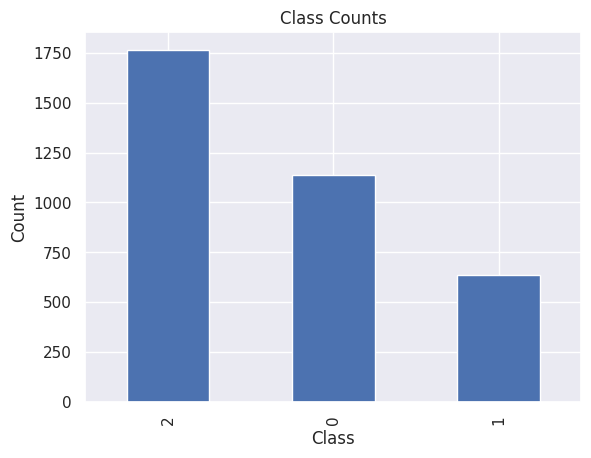

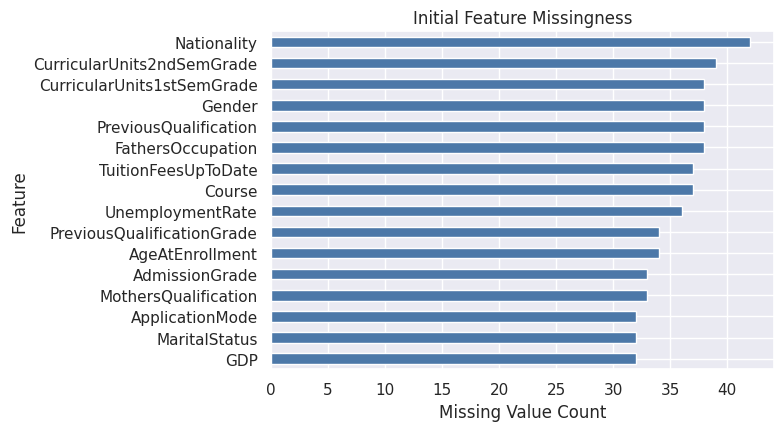

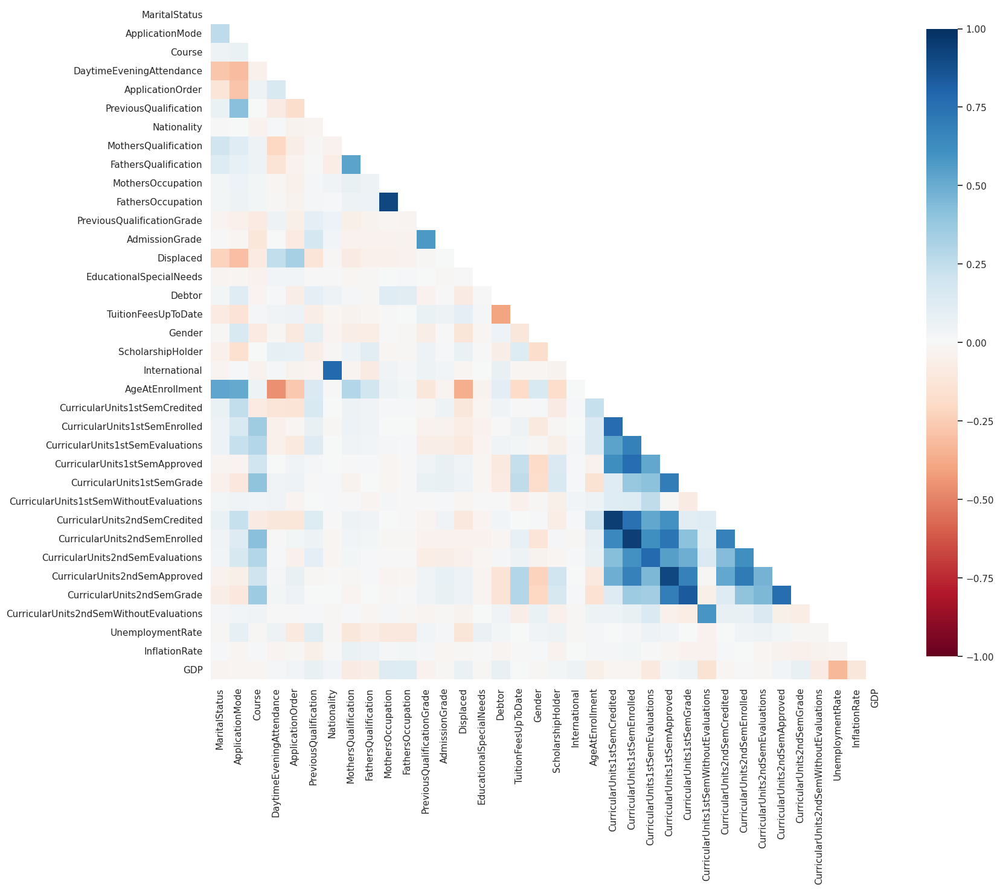

INFO: Running Post-Processing EDA...
INFO: Categorical: ['Debtor', 'ScholarshipHolder', 'DaytimeEveningAttendance', 'Gender', 'Displaced', 'EducationalSpecialNeeds', 'International', 'TuitionFeesUpToDate', 'PreviousQualification_1.0', 'PreviousQualification_2.0', 'PreviousQualification_3.0', 'PreviousQualification_4.0', 'PreviousQualification_5.0', 'PreviousQualification_6.0', 'PreviousQualification_9.0', 'PreviousQualification_10.0', 'PreviousQualification_12.0', 'PreviousQualification_14.0', 'PreviousQualification_15.0', 'PreviousQualification_19.0', 'PreviousQualification_38.0', 'PreviousQualification_39.0', 'PreviousQualification_40.0', 'PreviousQualification_42.0', 'PreviousQualification_43.0', 'FathersOccupation_0.0', 'FathersOccupation_1.0', 'FathersOccupation_2.0', 'FathersOccupation_3.0', 'FathersOccupation_4.0', 'FathersOccupation_5.0', 'FathersOccupation_6.0', 'FathersOccupation_7.0', 'FathersOccupation_8.0', 'FathersOccupation_9.0', 'FathersOccupation_10.0', 'FathersOccupat

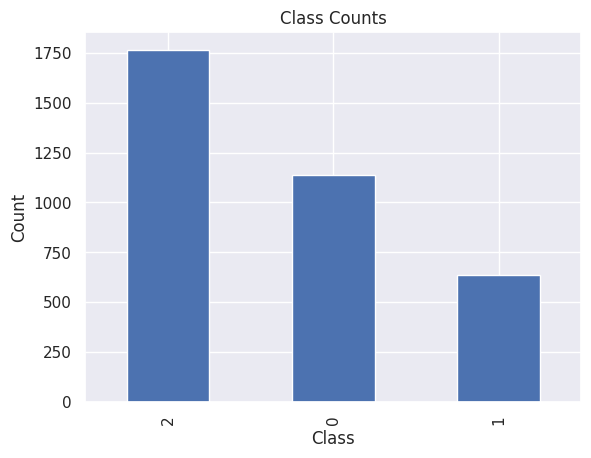

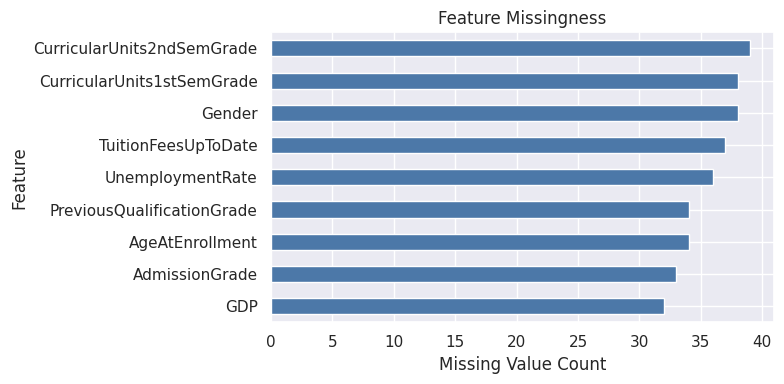

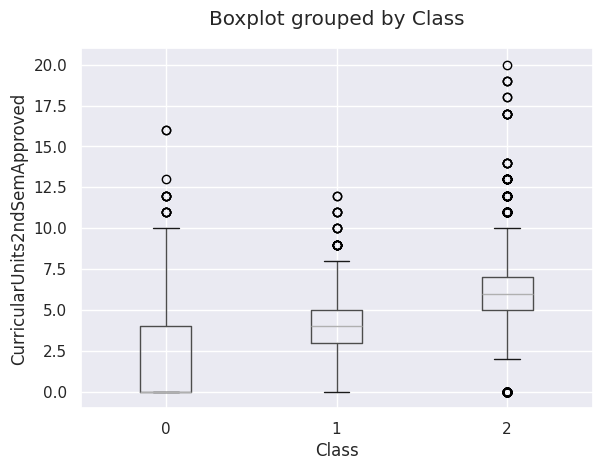

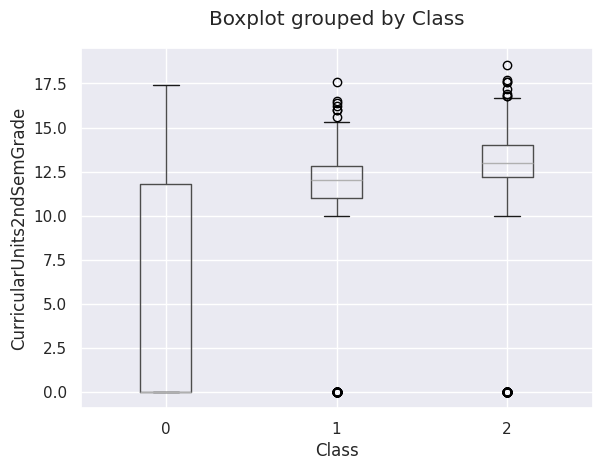

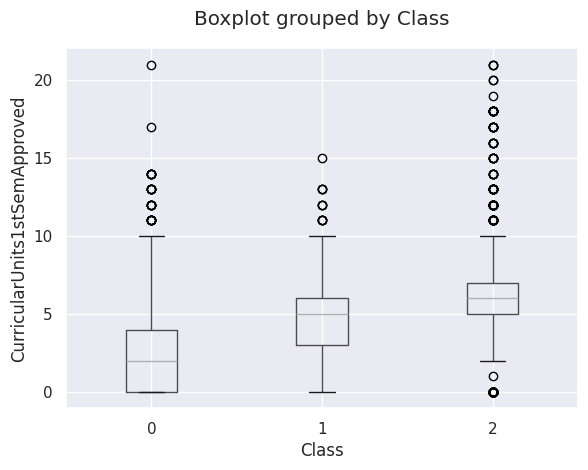

...

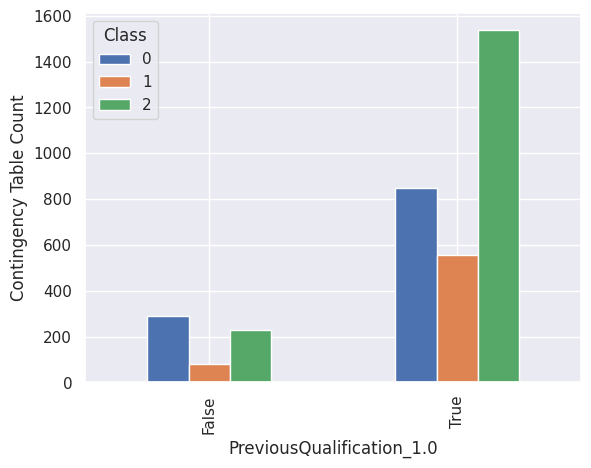

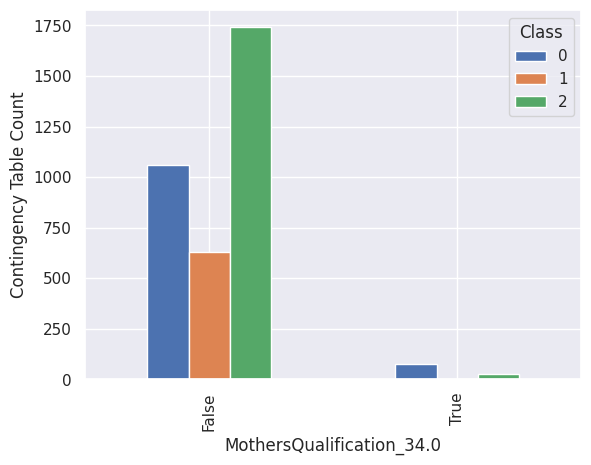

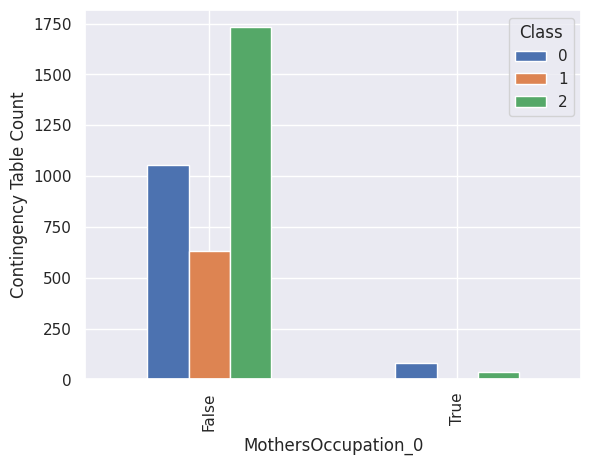

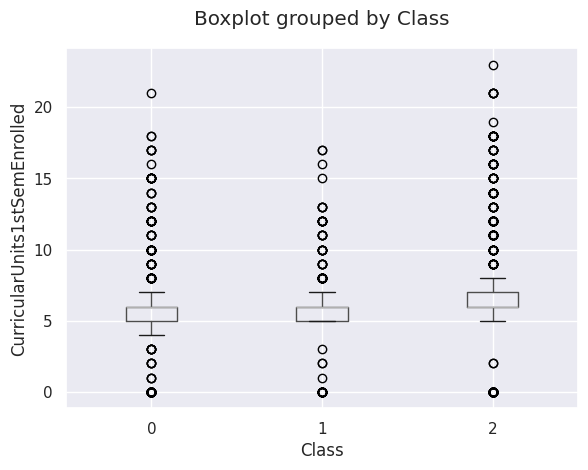

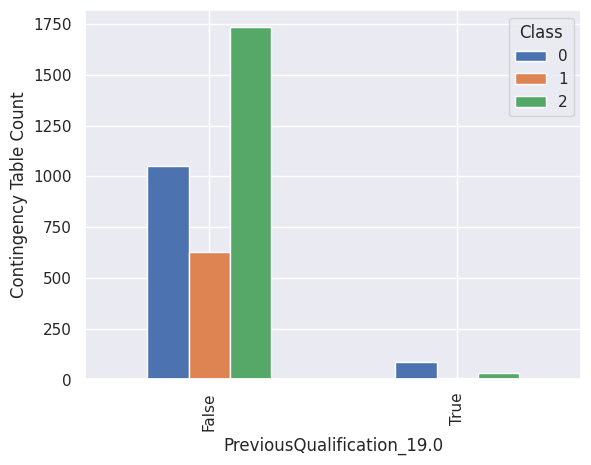

INFO: Validating and Identifying Feature Types...
INFO: Running Initial EDA:
INFO: /content/streamline_output/ColabRun
INFO: Categorical: ['PreviousQualification', 'Debtor', 'FathersOccupation', 'Course', 'ScholarshipHolder', 'DaytimeEveningAttendance', 'Gender', 'Nationality', 'FathersQualification', 'Displaced', 'MothersOccupation', 'ApplicationMode', 'EducationalSpecialNeeds', 'MaritalStatus', 'MothersQualification', 'International', 'TuitionFeesUpToDate']
INFO: Quantitative: ['ApplicationOrder', 'CurricularUnits2ndSemWithoutEvaluations', 'CurricularUnits1stSemCredited', 'CurricularUnits2ndSemGrade', 'CurricularUnits2ndSemCredited', 'CurricularUnits2ndSemEvaluations', 'AgeAtEnrollment', 'CurricularUnits1stSemApproved', 'AdmissionGrade', 'CurricularUnits1stSemWithoutEvaluations', 'UnemploymentRate', 'GDP', 'PreviousQualificationGrade', 'CurricularUnits1stSemEvaluations', 'CurricularUnits2ndSemApproved', 'InflationRate', 'CurricularUnits1stSemEnrolled', 'CurricularUnits1stSemGrade', '

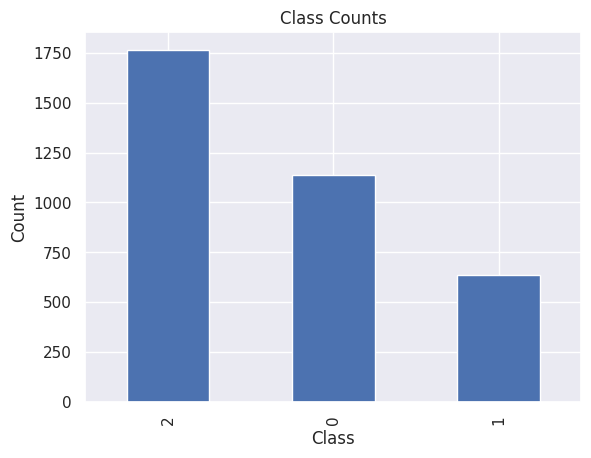

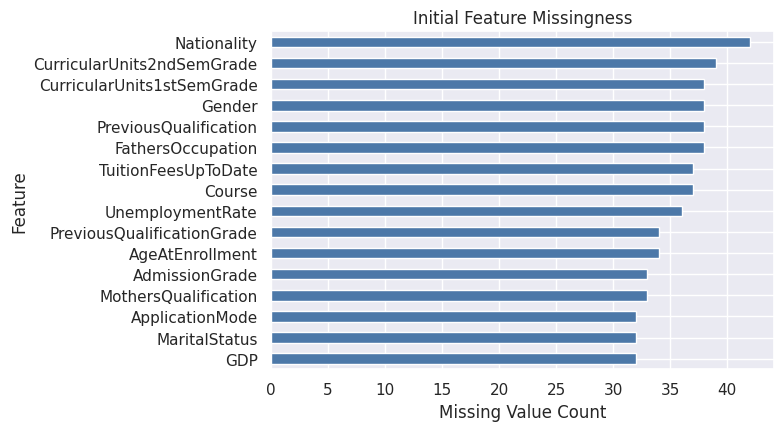

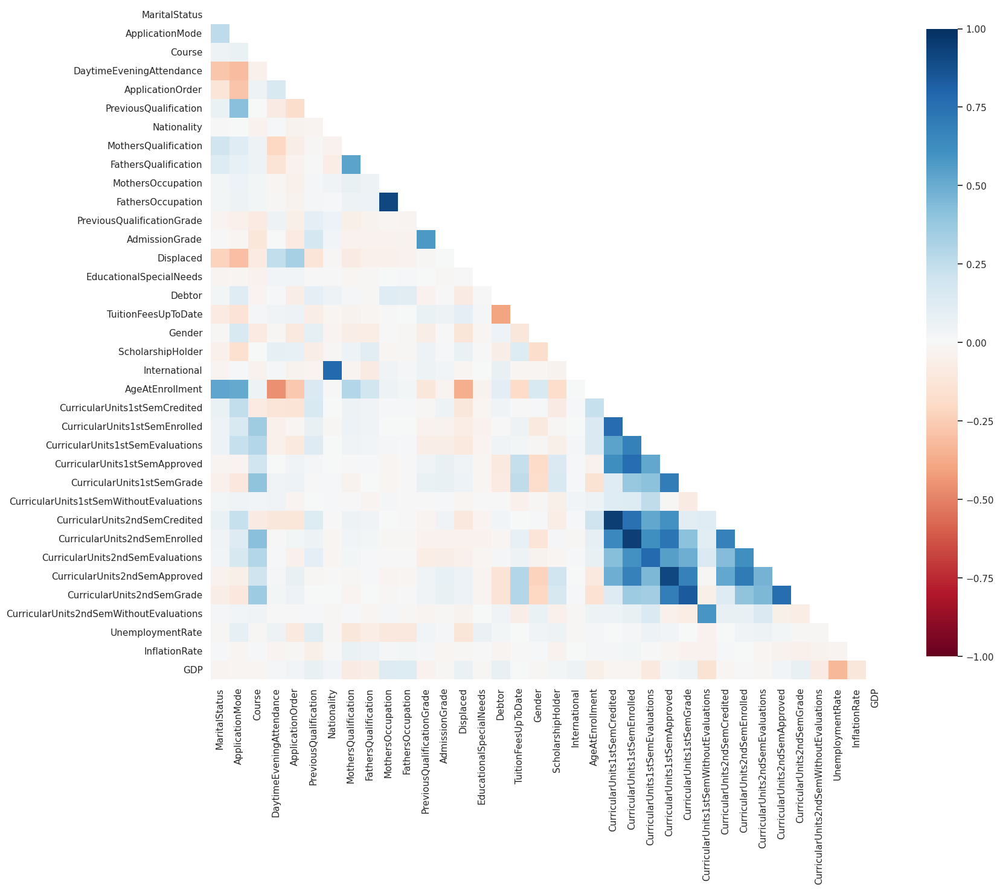

INFO: Running Post-Processing EDA...
INFO: Categorical: ['Debtor', 'ScholarshipHolder', 'DaytimeEveningAttendance', 'Gender', 'Displaced', 'EducationalSpecialNeeds', 'International', 'TuitionFeesUpToDate', 'PreviousQualification_1.0', 'PreviousQualification_2.0', 'PreviousQualification_3.0', 'PreviousQualification_4.0', 'PreviousQualification_5.0', 'PreviousQualification_6.0', 'PreviousQualification_9.0', 'PreviousQualification_10.0', 'PreviousQualification_12.0', 'PreviousQualification_14.0', 'PreviousQualification_15.0', 'PreviousQualification_19.0', 'PreviousQualification_38.0', 'PreviousQualification_39.0', 'PreviousQualification_40.0', 'PreviousQualification_42.0', 'PreviousQualification_43.0', 'FathersOccupation_0.0', 'FathersOccupation_1.0', 'FathersOccupation_2.0', 'FathersOccupation_3.0', 'FathersOccupation_4.0', 'FathersOccupation_5.0', 'FathersOccupation_6.0', 'FathersOccupation_7.0', 'FathersOccupation_8.0', 'FathersOccupation_9.0', 'FathersOccupation_10.0', 'FathersOccupat

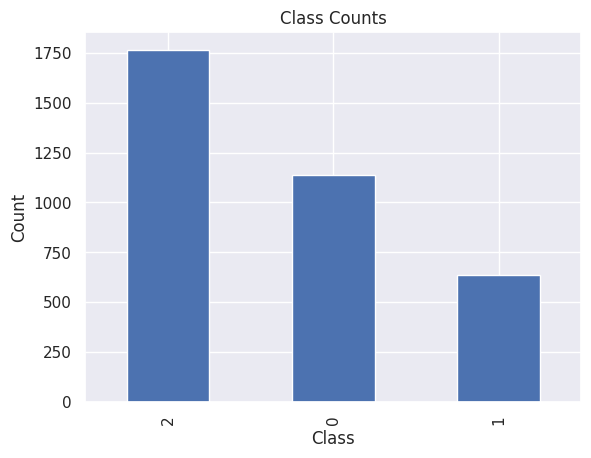

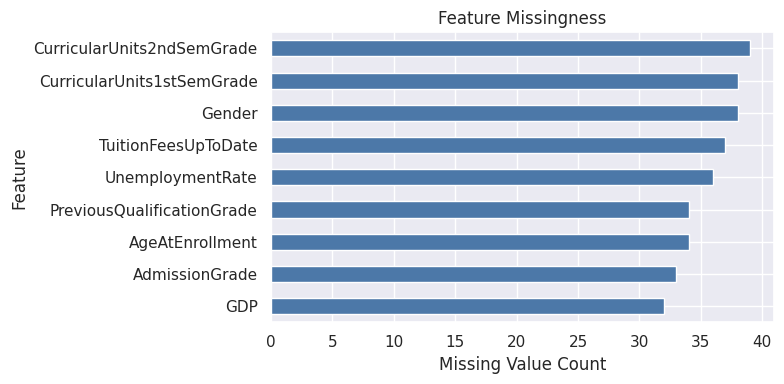

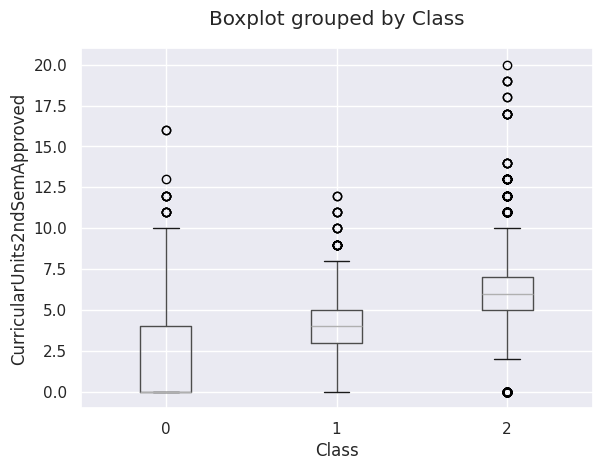

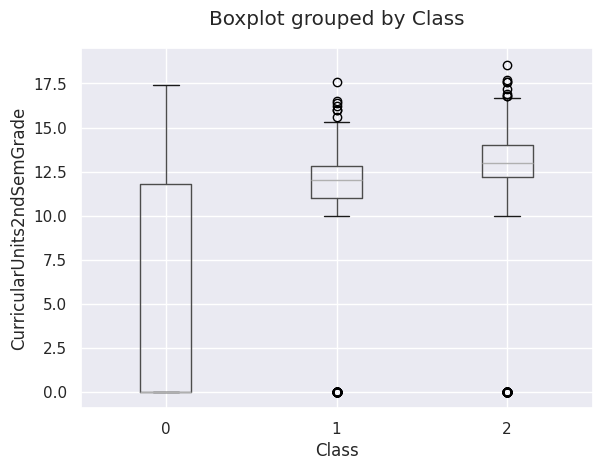

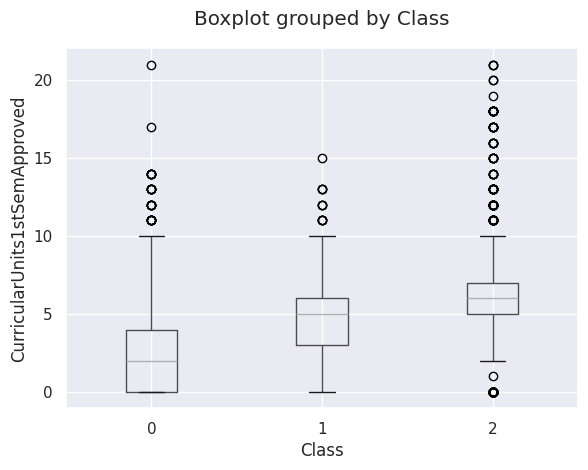

...

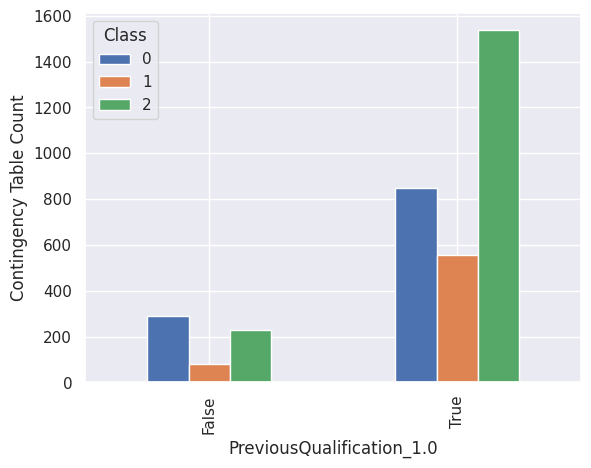

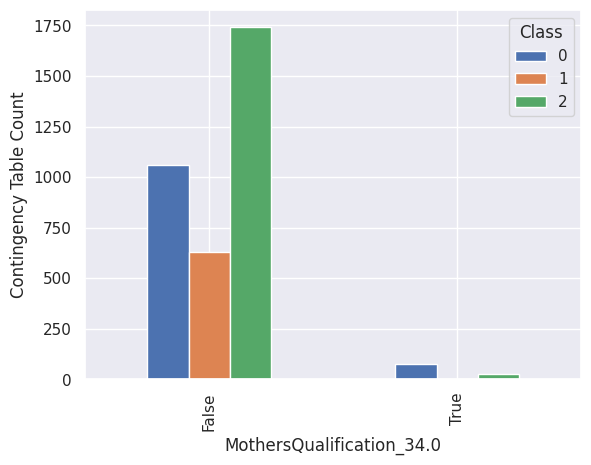

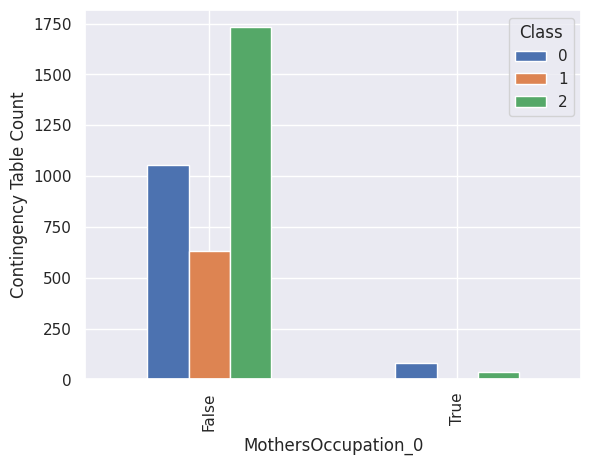

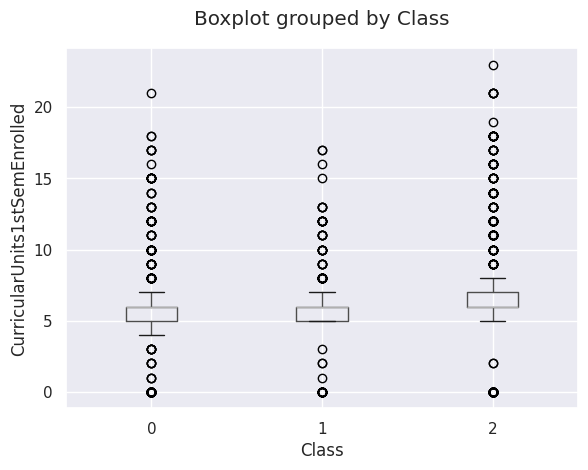

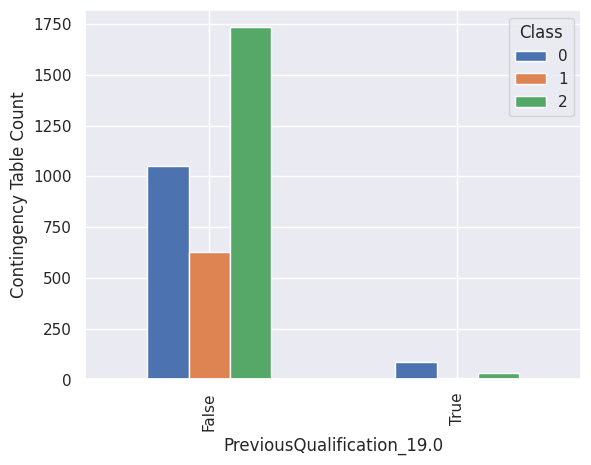

INFO: Updated run parameters in /content/streamline_output/ColabRun/run_params.pickle


INFO: Completed Phase 1 - Data Processing


In [26]:
if RUN_PHASES["p1"]:
    print("INFO: Starting Phase 1 - Data Processing")
    P1Runner(
        data_path=CFG["data_path"],
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        exclude_eda_output=P1_EXCLUDE_EDA_OUTPUT,
        outcome_label=CFG["outcome_label"],
        outcome_type=CFG["outcome_type"],
        instance_label=CFG["instance_label"],
        match_label=CFG["match_label"],
        n_splits=N_SPLITS,
        partition_method=P1_PARTITION_METHOD,
        ignore_features=P1_IGNORE_FEATURES,
        categorical_features=CFG.get("categorical_features"),
        quantitative_features=CFG.get("quantitative_features"),
        top_features=P1_TOP_FEATURES,
        categorical_cutoff=P1_CATEGORICAL_CUTOFF,
        sig_cutoff=P1_SIG_CUTOFF,
        featureeng_missingness=P1_FEATUREENG_MISSINGNESS,
        cleaning_missingness=P1_CLEANING_MISSINGNESS,
        correlation_removal_threshold=P1_CORRELATION_REMOVAL_THRESHOLD,
        random_state=RANDOM_STATE,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
        show_plots=P1_SHOW_PLOTS,
        one_hot_encoding=P1_ONE_HOT_ENCODING,
        cv_provided=P1_CV_PROVIDED,
        cv_input_root=P1_CV_INPUT_ROOT,
        enable_plots=P1_ENABLE_PLOTS,
        plot_missingness=P1_PLOT_MISSINGNESS,
        plot_class_counts=P1_PLOT_CLASS_COUNTS,
        plot_correlation=P1_PLOT_CORRELATION,
        correlation_plot_max_features=P1_CORRELATION_PLOT_MAX_FEATURES,
        plot_univariate=P1_PLOT_UNIVARIATE,
        univariate_top_k=P1_UNIVARIATE_TOP_K,
        plot_anomalies=P1_PLOT_ANOMALIES,
        force=P1_FORCE,
    ).run()
    print("INFO: Completed Phase 1 - Data Processing")
else:
    print("INFO: Phase 1 skipped")


## Phase 2: Impute, Scale, and Balance
After this cell runs, CV datasets are transformed according to Phase 2 settings:

- missing values are imputed
- quantitative features are optionally scaled
- optional SMOTE/SMOTENC balancing is applied to training folds only

The test fold is transformed using objects learned from the training fold to preserve valid CV separation.


### تنفيذ المرحلة الثانية P2

إذا كانت P2 مفعلة، يستدعي `P2Runner` ويمرر إليه خيارات التعويض والتقييس وموازنة الفئات، وأسماء الأعمدة والعشوائية ومعاملات الأدوات. ثم `.run()` ينفذ التحويلات.
**الفائدة:** تجهيز كل طية تدريب/اختبار مع تجنب تعلم التحويل من بيانات الاختبار.

### شرح هذه الخلية: تشغيل المرحلة الثانية P2
تستدعي `P2Runner` لمعالجة القيم المفقودة والقياس، وتستخدم إعدادات المرحلة الثانية واسم الهدف ومعرّف السجل والعشوائية.
هذه المرحلة تجهز خصائص البيانات لتكون مناسبة للتدريب، مع مراعاة تقسيمات CV.

In [27]:
if RUN_PHASES["p2"]:
    print("INFO: Starting Phase 2 - Scaling and Imputation")
    P2Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        scale_data=P2_SCALE_DATA,
        impute_data=P2_IMPUTE_DATA,
        multi_impute=P2_MULTI_IMPUTE,
        overwrite_cv=P2_OVERWRITE_CV,
        outcome_label=CFG["outcome_label"],
        instance_label=CFG["instance_label"],
        random_state=RANDOM_STATE,
        imputer_id=P2_IMPUTER_ID,
        imputer_params=P2_IMPUTER_PARAMS,
        scaler_id=P2_SCALER_ID,
        scaler_params=P2_SCALER_PARAMS,
        smote=P2_SMOTE,
        smote_method=P2_SMOTE_METHOD,
        smote_sampling_strategy=P2_SMOTE_SAMPLING_STRATEGY,
        smote_k_neighbors=P2_SMOTE_K_NEIGHBORS,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
    ).run()
    print("INFO: Completed Phase 2 - Scaling and Imputation")
else:
    print("INFO: Phase 2 skipped")


INFO: Preparing Train and Test for: student_dropout_academic_success_copy_CV_0
INFO: Imputing Missing Values...


INFO: Starting Phase 2 - Scaling and Imputation


INFO: Scaling Data Values...
INFO: Saving Processed Train and Test Data...
INFO: student_dropout_academic_success_copy Phase 2 complete
INFO: Preparing Train and Test for: student_dropout_academic_success_copy_CV_1
INFO: Imputing Missing Values...
INFO: Scaling Data Values...
INFO: Saving Processed Train and Test Data...
INFO: student_dropout_academic_success_copy Phase 2 complete
INFO: Preparing Train and Test for: student_dropout_academic_success_copy_CV_2
INFO: Imputing Missing Values...
INFO: Scaling Data Values...
INFO: Saving Processed Train and Test Data...
INFO: student_dropout_academic_success_copy Phase 2 complete
INFO: Preparing Train and Test for: student_dropout_academic_success_CV_0
INFO: Imputing Missing Values...
INFO: Scaling Data Values...
INFO: Saving Processed Train and Test Data...
INFO: student_dropout_academic_success Phase 2 complete
INFO: Preparing Train and Test for: student_dropout_academic_success_CV_1
INFO: Imputing Missing Values...
INFO: Scaling Data Valu

INFO: Completed Phase 2 - Scaling and Imputation


## Phase 3: Feature Learning
After this cell runs, learned representations such as PCA features are created per CV split. These learned features can replace or augment the original features depending on `P3_KEEP_ORIGINAL_FEATURES`.


### تنفيذ المرحلة الثالثة P3

يستدعي `P3Runner` مع طريقة تعلم الخصائص (PCA)، معاملاتها، اسم الخصائص الناتجة، وهل يحتفظ بالأصلية، إضافة إلى إعدادات CV والهدف ومعرف السجل.
**الفائدة:** إنشاء خصائص مشتقة قد تساعد النماذج على التعلم من البيانات.

### شرح هذه الخلية: تشغيل المرحلة الثالثة P3
تستدعي `P3Runner` لتنفيذ PCA أو طريقة Feature Learning المحددة، وتحدد أسماء الخصائص الجديدة وهل تحتفظ بالأصلية.
الناتج خصائص متعلمة يمكن استخدامها في المراحل اللاحقة.

In [28]:
if RUN_PHASES["p3"]:
    print("INFO: Starting Phase 3 - Feature Learning")
    P3Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        learner_id=P3_LEARNER_ID,
        learner_params=P3_LEARNER_PARAMS,
        feature_namespace=P3_FEATURE_NAMESPACE,
        keep_original_features=P3_KEEP_ORIGINAL_FEATURES,
        overwrite_cv=P3_OVERWRITE_CV,
        outcome_label=CFG["outcome_label"],
        instance_label=CFG["instance_label"],
        random_state=RANDOM_STATE,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
    ).run()
    print("INFO: Completed Phase 3 - Feature Learning")
else:
    print("INFO: Phase 3 skipped")


INFO: Phase 3 starting for experiment 'ColabRun' with learner 'pca' and namespace 'FL_PCA'.
INFO: Phase 3 discovered 6 CV train/test pairs across 2 dataset(s): student_dropout_academic_success, student_dropout_academic_success_copy
INFO: Phase 3 submitting 6 jobs in mode 'Serial'.
INFO: -------------------------------------------------------
INFO: Loading Dataset: student_dropout_academic_success_copy_CV_0_Train
INFO: Prepared Train and Test for: student_dropout_academic_success_copy_CV_0
INFO: Running Feature Learning (pca)...
INFO: Principal components added: 27 (cumulative explained variance: 1.000)


INFO: Starting Phase 3 - Feature Learning


INFO: Feature learning summary for student_dropout_academic_success_copy_CV_0: input=239, PCs=27, keep_original=True, final_features=266, train_shape=(2359, 268), test_shape=(1180, 268)
INFO: student_dropout_academic_success_copy CV0 phase 3 pca evaluation complete
INFO: -------------------------------------------------------
INFO: Loading Dataset: student_dropout_academic_success_copy_CV_1_Train
INFO: Prepared Train and Test for: student_dropout_academic_success_copy_CV_1
INFO: Running Feature Learning (pca)...
INFO: Principal components added: 27 (cumulative explained variance: 1.000)
INFO: Feature learning summary for student_dropout_academic_success_copy_CV_1: input=239, PCs=27, keep_original=True, final_features=266, train_shape=(2359, 268), test_shape=(1180, 268)
INFO: student_dropout_academic_success_copy CV1 phase 3 pca evaluation complete
INFO: -------------------------------------------------------
INFO: Loading Dataset: student_dropout_academic_success_copy_CV_2_Train
INFO: 

INFO: Completed Phase 3 - Feature Learning


## Phase 4: Feature Importance
After this cell runs, feature-importance scores are saved for each active method and CV split. These outputs feed Phase 5 feature selection, summary statistics, and report tables/figures.


### تنفيذ المرحلة الرابعة P4

قبل تشغيل `P4Runner`، ينسخ الكود إعدادات طرق الأهمية إلى قاموس مستقل، ويحوّل `outcome_type='auto'` إلى نوع المهمة الفعلي. ثم يمرر طرق حساب الأهمية وعدد الخصائص/الحدود وبقية إعدادات التجربة.
**الفائدة:** حساب درجات أهمية الخصائص وحفظها لتحليلها أو استخدامها لاحقًا.

### شرح هذه الخلية: تشغيل المرحلة الرابعة P4
قبل التشغيل تضبط نوع الهدف تلقائيًا لخوارزمية Mutual Information إذا كان `auto`.
ثم تستدعي `P4Runner` لحساب أهمية الخصائص وفق الطرق المختارة وتسجيل الدرجات.

In [29]:
if RUN_PHASES["p4"]:
    p4_model_params = P4_MODELS_PARAMS
    if isinstance(p4_model_params, dict):
        p4_model_params = {k: dict(v) for k, v in p4_model_params.items()}
        if p4_model_params.get("mutualinformation", {}).get("outcome_type") == "auto":
            p4_model_params["mutualinformation"]["outcome_type"] = CFG["outcome_type"]
    print("INFO: Starting Phase 4 - Feature Importance")
    P4Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        models=P4_MODELS,
        models_params=p4_model_params,
        top_k=P4_TOP_K,
        threshold=P4_THRESHOLD,
        keep_original_features=P4_KEEP_ORIGINAL_FEATURES,
        overwrite_cv=P4_OVERWRITE_CV,
        outcome_label=CFG["outcome_label"],
        outcome_type=CFG["outcome_type"],
        instance_label=CFG["instance_label"],
        random_state=RANDOM_STATE,
        instance_subset=P4_INSTANCE_SUBSET,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
    ).run()
    print("INFO: Completed Phase 4 - Feature Importance")
else:
    print("INFO: Phase 4 skipped")


INFO: Phase 4 starting for experiment 'ColabRun' with models: mutualinformation, multiswrfdb
INFO: Phase 4 discovered 6 CV train/test pairs.
INFO: Phase 4 submitting 12 jobs in mode 'Serial'.
INFO: Phase 4 running model 'mutualinformation' on student_dropout_academic_success_copy [student_dropout_academic_success_copy_CV_0].
INFO: -------------------------------------------------------
INFO: Loading Dataset: student_dropout_academic_success_copy_CV_0_Train
INFO: Prepared Train and Test for: student_dropout_academic_success_copy_CV_0
INFO: Running mutualinformation...


INFO: Starting Phase 4 - Feature Importance


INFO: Sort and pickle feature importance scores...
INFO: student_dropout_academic_success_copy CV0 phase 4 mutualinformation evaluation complete
INFO: Phase 4 completed model 'mutualinformation' on student_dropout_academic_success_copy [student_dropout_academic_success_copy_CV_0].
INFO: Phase 4 running model 'multiswrfdb' on student_dropout_academic_success_copy [student_dropout_academic_success_copy_CV_0].
INFO: -------------------------------------------------------
INFO: Loading Dataset: student_dropout_academic_success_copy_CV_0_Train
INFO: Prepared Train and Test for: student_dropout_academic_success_copy_CV_0
INFO: Phase 4 multiswrfdb passing 220 STREAMLINE categorical feature index(es) to ReBATE.
INFO: Running multiswrfdb...
INFO: Phase 4 multiswrfdb using instance_subset=1000 (1000 of 2359 training instances).
INFO: Sort and pickle feature importance scores...
INFO: student_dropout_academic_success_copy CV0 phase 4 multiswrfdb evaluation complete
INFO: Phase 4 completed model '

INFO: Completed Phase 4 - Feature Importance


## Phase 5: Feature Selection
After this cell runs, selected feature subsets and informative feature summaries are generated. If filtering is disabled, all features continue to modeling; otherwise STREAMLINE uses the FI outputs to remove weakly supported features.


### تنفيذ المرحلة الخامسة P5

يستدعي `P5Runner` بخوارزميات الاختيار، عدد الطيات، الهدف، حد الخصائص، فلترة الخصائص الضعيفة، إعدادات الاختيار وتصدير الدرجات والرسوم.
**الفائدة:** إنشاء مجموعة خصائص مختارة بدل استخدام كل الأعمدة.

### شرح هذه الخلية: تشغيل المرحلة الخامسة P5
تستدعي `P5Runner` لتحديد الخصائص الأفضل أو استبعاد الخصائص الضعيفة، وفق الخوارزميات والحد الأقصى وعدد التقسيمات المحددة.
تؤثر نتائج هذه المرحلة في الأعمدة التي ستصل إلى التدريب.

INFO: Phase 5 starting for experiment 'ColabRun'.
INFO: Phase 5 discovered 2 dataset(s).
INFO: Phase 5 discovered algorithms for student_dropout_academic_success: multiswrfdb, mutualinformation
INFO: Phase 5 running on dataset student_dropout_academic_success with algorithms: multiswrfdb, mutualinformation
INFO: Phase 5 running selector 'default' for dataset 'student_dropout_academic_success' with algorithms: multiswrfdb, mutualinformation
INFO: Plotting Feature Importance Scores for multiswrfdb...
INFO:                          Feature  Importance
   CurricularUnits2ndSemApproved    0.198215
   CurricularUnits1stSemApproved    0.125201
                      FL_PCA_PC2    0.119714
      CurricularUnits2ndSemGrade    0.091481
                      FL_PCA_PC1    0.077537
      CurricularUnits1stSemGrade    0.060579
CurricularUnits2ndSemEvaluations    0.055368
               ScholarshipHolder    0.053065
                     FL_PCA_PC24    0.050443
CurricularUnits1stSemEvaluations    0.04

INFO: Starting Phase 5 - Feature Selection


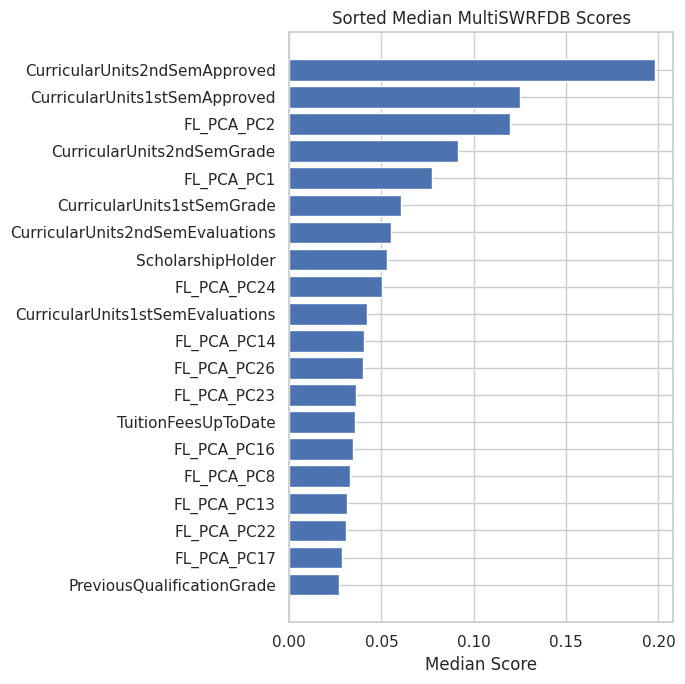

INFO: Saved Feature Importance Plots at
INFO: /content/streamline_output/ColabRun/student_dropout_academic_success/feature_importance/multiswrfdb/TopAverageScores.png
INFO: Plotting Feature Importance Scores for mutualinformation...
INFO:                          Feature  Importance
   CurricularUnits2ndSemApproved    0.296680
   CurricularUnits1stSemApproved    0.247797
                      FL_PCA_PC1    0.222243
      CurricularUnits2ndSemGrade    0.214438
                      FL_PCA_PC2    0.209762
      CurricularUnits1stSemGrade    0.164154
             TuitionFeesUpToDate    0.106069
CurricularUnits2ndSemEvaluations    0.089452
                     FL_PCA_PC17    0.088976
CurricularUnits1stSemEvaluations    0.079273


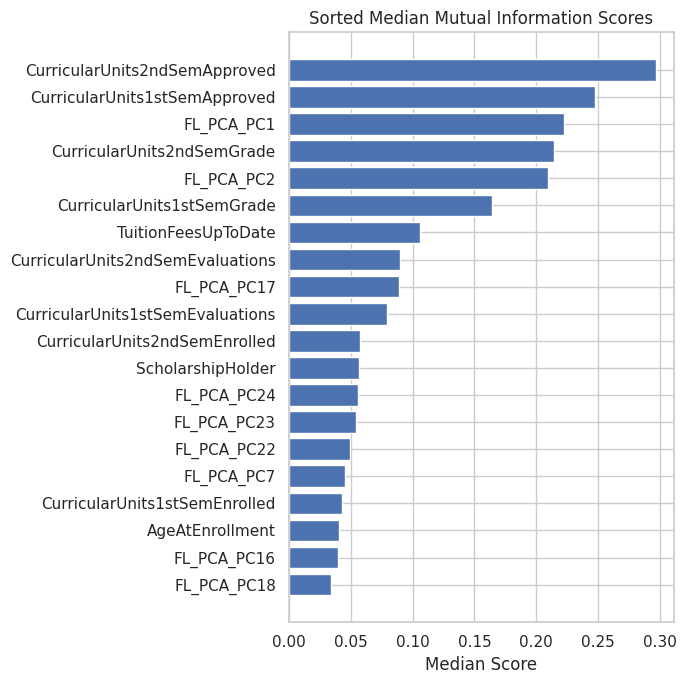

INFO: Saved Feature Importance Plots at
INFO: /content/streamline_output/ColabRun/student_dropout_academic_success/feature_importance/mutualinformation/TopAverageScores.png
INFO: Applying collective feature selection...
INFO: student_dropout_academic_success Phase 5 complete
INFO: Phase 5 completed for dataset student_dropout_academic_success.
INFO: Phase 5 discovered algorithms for student_dropout_academic_success_copy: multiswrfdb, mutualinformation
INFO: Phase 5 running on dataset student_dropout_academic_success_copy with algorithms: multiswrfdb, mutualinformation
INFO: Phase 5 running selector 'default' for dataset 'student_dropout_academic_success_copy' with algorithms: multiswrfdb, mutualinformation
INFO: Plotting Feature Importance Scores for multiswrfdb...
INFO:                          Feature  Importance
   CurricularUnits2ndSemApproved    0.198215
   CurricularUnits1stSemApproved    0.125201
                      FL_PCA_PC2    0.119714
      CurricularUnits2ndSemGrade    0.

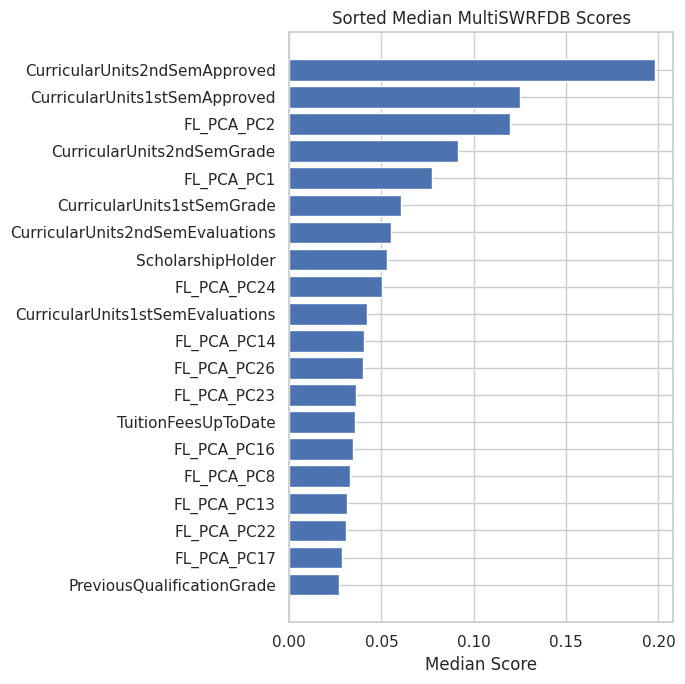

INFO: Saved Feature Importance Plots at
INFO: /content/streamline_output/ColabRun/student_dropout_academic_success_copy/feature_importance/multiswrfdb/TopAverageScores.png
INFO: Plotting Feature Importance Scores for mutualinformation...
INFO:                          Feature  Importance
   CurricularUnits2ndSemApproved    0.296680
   CurricularUnits1stSemApproved    0.247797
                      FL_PCA_PC1    0.222243
      CurricularUnits2ndSemGrade    0.214438
                      FL_PCA_PC2    0.209762
      CurricularUnits1stSemGrade    0.164154
             TuitionFeesUpToDate    0.106069
CurricularUnits2ndSemEvaluations    0.089452
                     FL_PCA_PC17    0.088976
CurricularUnits1stSemEvaluations    0.079273


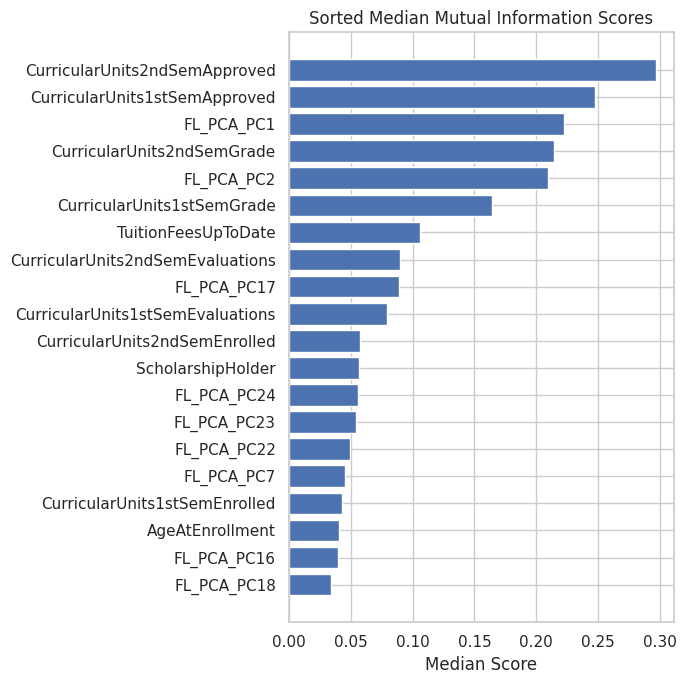

INFO: Saved Feature Importance Plots at
INFO: /content/streamline_output/ColabRun/student_dropout_academic_success_copy/feature_importance/mutualinformation/TopAverageScores.png
INFO: Applying collective feature selection...
INFO: student_dropout_academic_success_copy Phase 5 complete
INFO: Phase 5 completed for dataset student_dropout_academic_success_copy.
INFO: Phase 5 completed for experiment 'ColabRun'.


INFO: Completed Phase 5 - Feature Selection


In [30]:
if RUN_PHASES["p5"]:
    print("INFO: Starting Phase 5 - Feature Selection")
    P5Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        algorithms=P5_ALGORITHMS,
        n_splits=P5_N_SPLITS,
        outcome_label=CFG["outcome_label"],
        instance_label=CFG["instance_label"],
        max_features_to_keep=P5_MAX_FEATURES_TO_KEEP,
        filter_poor_features=P5_FILTER_POOR_FEATURES,
        overwrite_cv=P5_OVERWRITE_CV,
        selector_id=P5_SELECTOR_ID,
        selector_params=P5_SELECTOR_PARAMS,
        export_scores=P5_EXPORT_SCORES,
        top_features=P5_TOP_FEATURES,
        show_plots=P5_SHOW_PLOTS,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
        strict_discovery=P5_STRICT_DISCOVERY,
    ).run()
    print("INFO: Completed Phase 5 - Feature Selection")
else:
    print("INFO: Phase 5 skipped")


## Phase 6: Modeling
After this cell runs, STREAMLINE trains and evaluates each requested model across CV splits. Outputs include trained model pickles, metrics, ROC/PRC or regression artifacts, Optuna trial summaries, and model feature-importance estimates.


### تنفيذ المرحلة السادسة P6

يستدعي `P6Runner` لتدريب النماذج. يمرر نوع الهدف والنماذج (المخصصة أو الافتراضية)، إعدادات الضبط والمعايرة ومقياس التقييم والوقت وعدد التجارب والعشوائية وإعدادات التنفيذ. ثم `.run()` يبدأ التدريب والتقييم.
**الفائدة:** إنتاج نماذج مدربة ومقاييس أداء قابلة للمقارنة.

### شرح هذه الخلية: تشغيل المرحلة السادسة P6 (التدريب والتقييم)
تستدعي `P6Runner` وتحدد نوع المهمة والنماذج والمعاملات وعدد تقسيمات CV.
هذه هي المرحلة التي يتم فيها تدريب النماذج وقياس أدائها على أجزاء التحقق. النتائج الفعلية تظهر بعد تنفيذ الخلية وليست أرقامًا ثابتة في الكود.

In [31]:
if RUN_PHASES["p6"]:
    print("INFO: Starting Phase 6 - Modeling")
    P6Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        outcome_label=CFG["outcome_label"],
        outcome_type=P6_OUTCOME_TYPE or CFG["outcome_type"],
        model_type=P6_MODEL_TYPE,
        instance_label=CFG["instance_label"],
        n_splits=N_SPLITS,
        models=P6_MODELS or CFG["p6_models"],
        model_params_json=P6_MODEL_PARAMS_JSON,
        calibrate=P6_CALIBRATE,
        calibrate_method=P6_CALIBRATE_METHOD,
        calibrate_cv=P6_CALIBRATE_CV,
        scoring_metric=P6_SCORING_METRIC or CFG["p6_scoring_metric"],
        metric_direction=P6_METRIC_DIRECTION or CFG["p6_metric_direction"],
        n_trials=P6_N_TRIALS,
        timeout=P6_TIMEOUT,
        training_subsample=P6_TRAINING_SUBSAMPLE,
        uniform_fi=P6_UNIFORM_FI,
        save_plot=P6_SAVE_PLOT,
        skip_completed_models=P6_SKIP_COMPLETED_MODELS,
        random_state=RANDOM_STATE,
        bypass_one_hot_for_native_models=P6_BYPASS_ONE_HOT_FOR_NATIVE_MODELS,
        native_categorical_models=P6_NATIVE_CATEGORICAL_MODELS,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
    ).run()
    print("INFO: Completed Phase 6 - Modeling")
else:
    print("INFO: Phase 6 skipped")


INFO: Starting Phase 6 - Modeling


INFO: Running NB on /content/streamline_output/ColabRun/student_dropout_academic_success/CVDatasets/student_dropout_academic_success_CV_0_Train.csv
INFO: student_dropout_academic_success [CV_0] (NB) training complete. ------------------------------------
INFO: Running NB on /content/streamline_output/ColabRun/student_dropout_academic_success/CVDatasets/student_dropout_academic_success_CV_1_Train.csv
INFO: student_dropout_academic_success [CV_1] (NB) training complete. ------------------------------------
INFO: Running NB on /content/streamline_output/ColabRun/student_dropout_academic_success/CVDatasets/student_dropout_academic_success_CV_2_Train.csv
INFO: student_dropout_academic_success [CV_2] (NB) training complete. ------------------------------------
INFO: Running LR on /content/streamline_output/ColabRun/student_dropout_academic_success/CVDatasets/student_dropout_academic_success_CV_0_Train.csv
INFO: Best trial:
INFO:   Value: 0.7109261517469735
INFO:   Params: 
INFO:     solver: 

INFO: Completed Phase 6 - Modeling


## Phase 7: Ensembles
Optional phase. After this cell runs, ensemble metrics and curves are generated from Phase 6 base models when enabled. The notebook skips this phase for regression unless `ALLOW_P7_FOR_REGRESSION=True`.


### تنفيذ المرحلة السابعة P7

يحدد `run_p7` هل المرحلة مفعلة، ويتأكد من أن المهمة ليست انحدارًا إلا إذا سمح المستخدم بذلك. عند التشغيل يستدعي `P7Runner` ويحدد أنواع الدمج والنماذج الأساسية ومصدر تدريب النموذج التجميعي والمعايرة. وإلا يطبع سبب تجاوز المرحلة.
**الفائدة:** بناء نماذج Ensemble ومقارنة نتائجها بالنماذج الفردية.

### شرح هذه الخلية: تشغيل/تجاوز المرحلة السابعة P7
أولًا تتحقق من تفعيل المرحلة ومن `P7_ENABLED`.
إذا كانت المهمة Regression ولم يسمح الإعداد بالتجميع، تتجاوز P7.
عند تشغيلها تستدعي `P7Runner` لبناء ومقارنة Ensemble مثل Voting وStacking.

In [32]:
print("INFO: Evaluating Phase 7 - Ensembles")
run_p7 = RUN_PHASES["p7"] and P7_ENABLED
if CFG["task_family"] == "regression" and not ALLOW_P7_FOR_REGRESSION:
    run_p7 = False
    print("INFO: Phase 7 skipped for regression (ALLOW_P7_FOR_REGRESSION=False)")

if run_p7:
    print("INFO: Starting Phase 7 - Ensembles")
    P7Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        n_splits=N_SPLITS,
        outcome_label=CFG["outcome_label"],
        instance_label=CFG["instance_label"],
        ensembles=P7_ENSEMBLES,
        base_models=(P7_BASE_MODELS or CFG["p6_models"]),
        meta_train_source=P7_META_TRAIN_SOURCE,
        calibrate=P7_CALIBRATE,
        calibrate_method=P7_CALIBRATE_METHOD,
        calibrate_cv=P7_CALIBRATE_CV,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
        random_state=RANDOM_STATE,
    ).run()
    print("INFO: Completed Phase 7 - Ensembles")
elif RUN_PHASES["p7"]:
    print("INFO: Phase 7 skipped")


INFO: [P7] student_dropout_academic_success CV=0: loading base estimators...
INFO: [P7] Building ensemble: Hard Ensemble Voting using 3 base models


INFO: Evaluating Phase 7 - Ensembles
INFO: Starting Phase 7 - Ensembles


INFO: [P7] Saved ensemble metrics/curves for HEV CV=0
INFO: [P7] Building ensemble: Soft Ensemble Voting using 3 base models
INFO: [P7] Saved ensemble metrics/curves for SEV CV=0
INFO: [P7] Building ensemble: StackingLogReg using 3 base models
INFO: [P7] Building ensemble (stacking): StackingLogReg [meta on train]
INFO: [P7] Saved ensemble metrics/curves for STK_LR CV=0
INFO: [P7] student_dropout_academic_success CV=1: loading base estimators...
INFO: [P7] Building ensemble: Hard Ensemble Voting using 3 base models
INFO: [P7] Saved ensemble metrics/curves for HEV CV=1
INFO: [P7] Building ensemble: Soft Ensemble Voting using 3 base models
INFO: [P7] Saved ensemble metrics/curves for SEV CV=1
INFO: [P7] Building ensemble: StackingLogReg using 3 base models
INFO: [P7] Building ensemble (stacking): StackingLogReg [meta on train]
INFO: [P7] Saved ensemble metrics/curves for STK_LR CV=1
INFO: [P7] student_dropout_academic_success CV=2: loading base estimators...
INFO: [P7] Building ensemble:

INFO: Completed Phase 7 - Ensembles


## Phase 8: Summary Statistics
After this cell runs, STREAMLINE creates per-dataset performance summaries and post-analysis figures, including model comparison plots and feature-importance summaries used by the final report.


### تنفيذ المرحلة الثامنة P8

يستدعي `P8Runner` لإنتاج ملخصات الأداء والرسوم. يمرر نوع المهمة ومقياس التقييم وعدد الخصائص المهمة وحد الدلالة وإعداد الرسوم، وهل يضم نتائج Ensemble، وطريقة تجميع المقاييس متعددة الفئات.
**الفائدة:** تنظيم النتائج في جداول/رسوم تساعد على اختيار النموذج الأفضل.

### شرح هذه الخلية: تشغيل المرحلة الثامنة P8
تستدعي `P8Runner` لتجميع نتائج النماذج وحساب/عرض الإحصاءات والمقاييس والرسوم ومقارنة الأداء، مع تحديد عدد الخصائص التي تظهر في الملخص.

INFO: Running Statistics Summary for student_dropout_academic_success
INFO: Running stats on Decision Tree


INFO: Starting Phase 8 - Summary Statistics


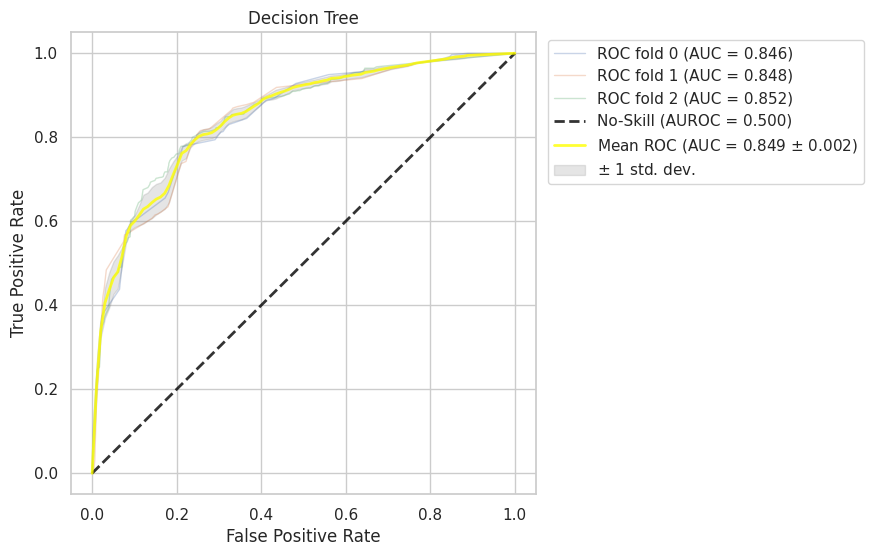

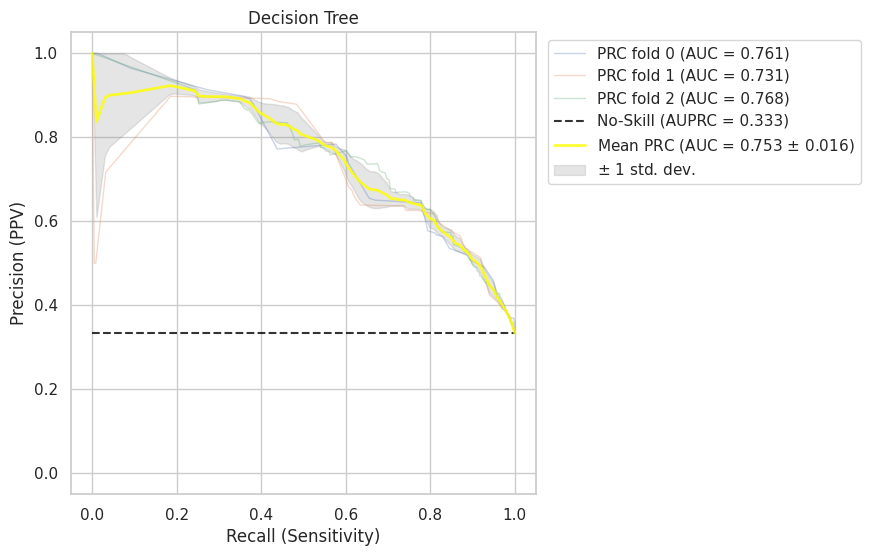

INFO: Running stats on Logistic Regression


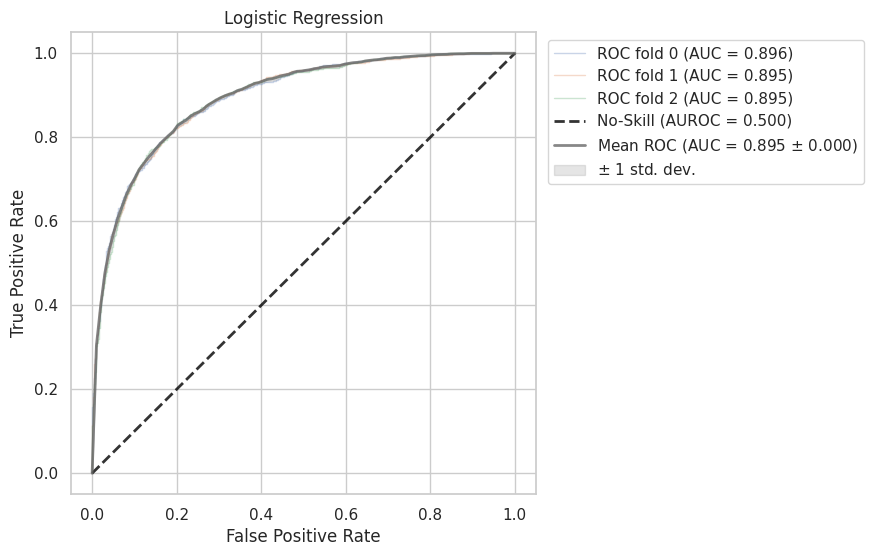

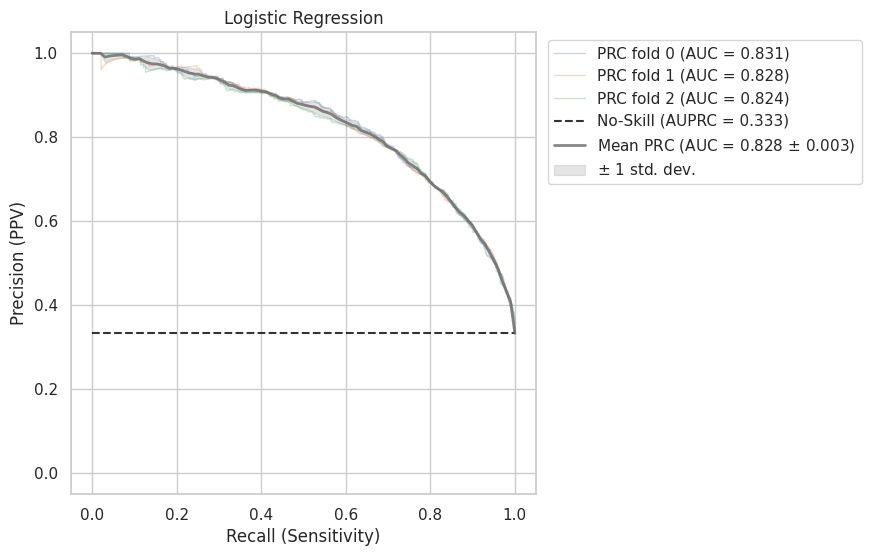

INFO: Running stats on Naive Bayes


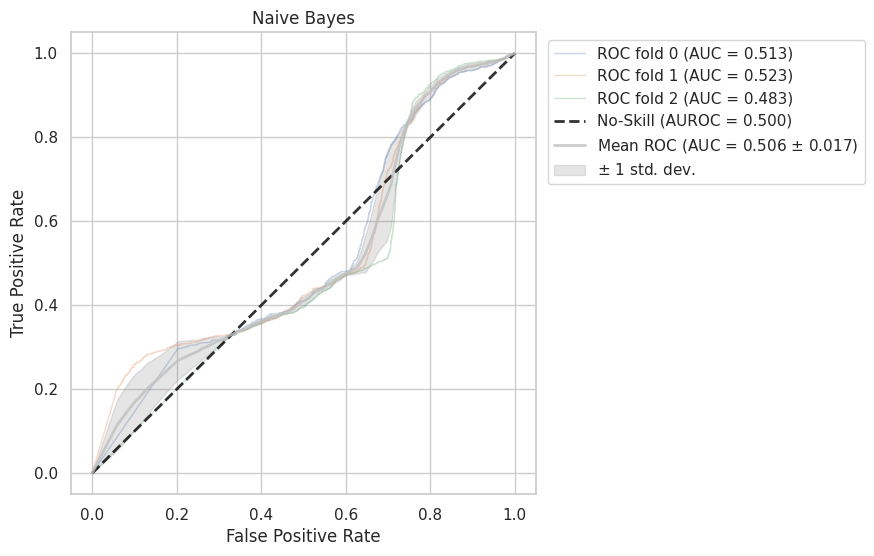

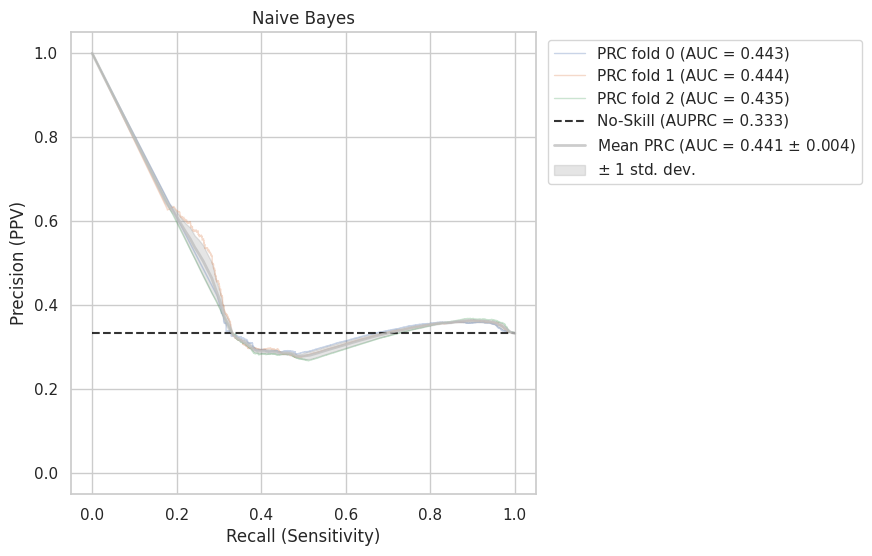

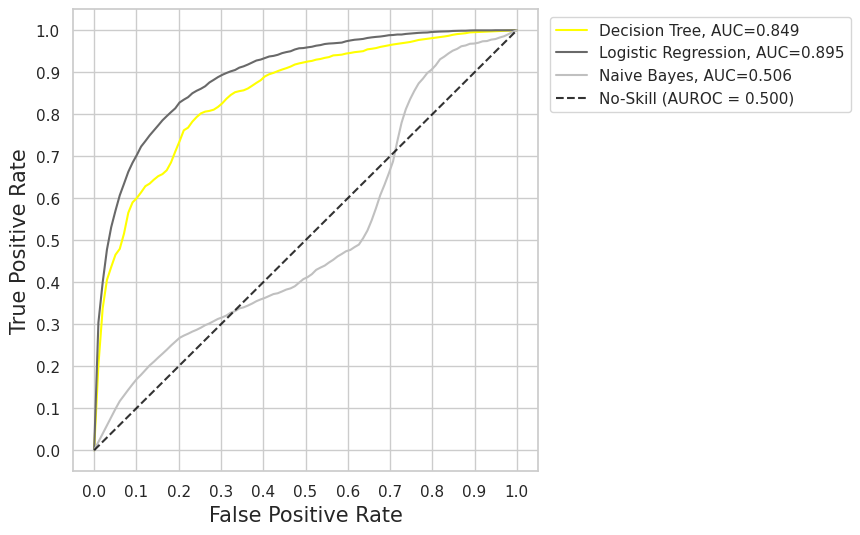

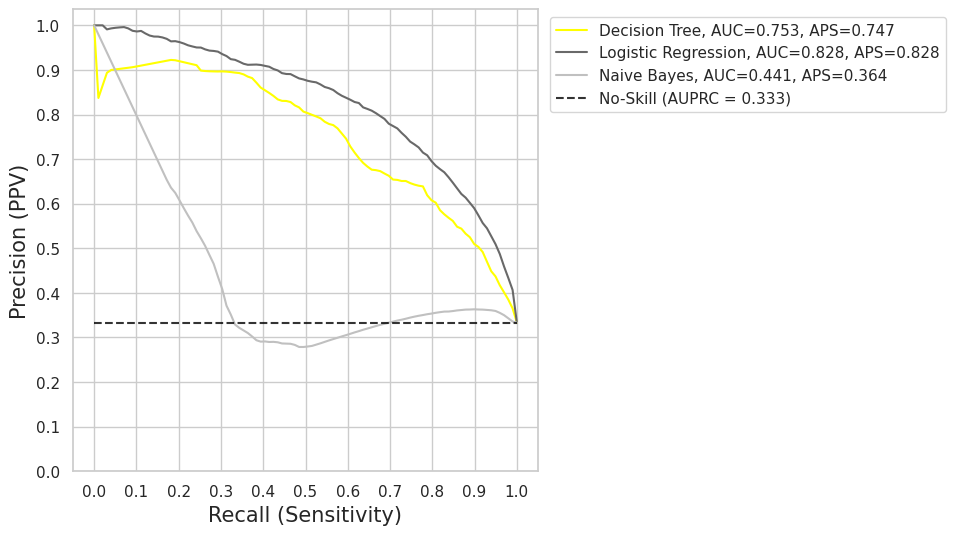

INFO: Saving Metric Summaries...
INFO: Generating Metric Boxplots...


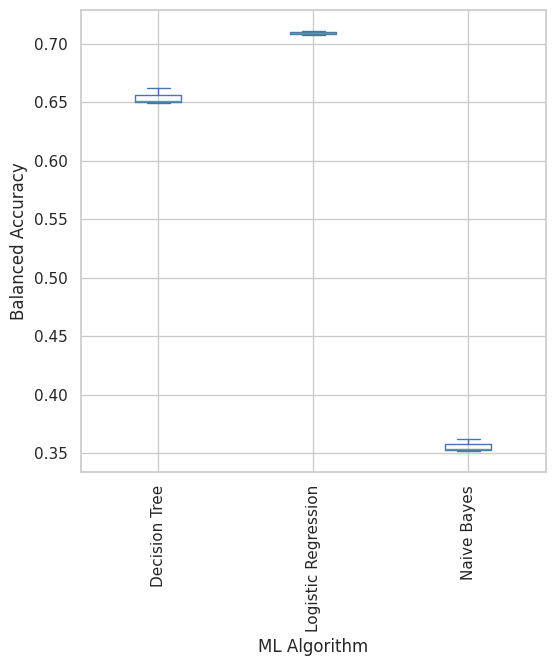

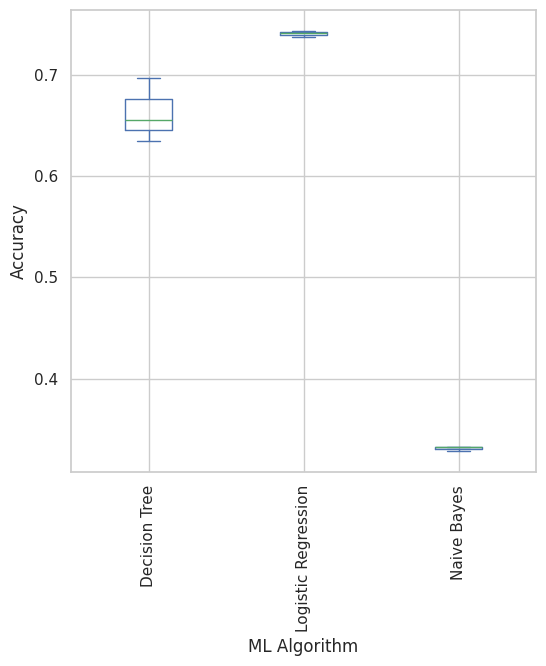

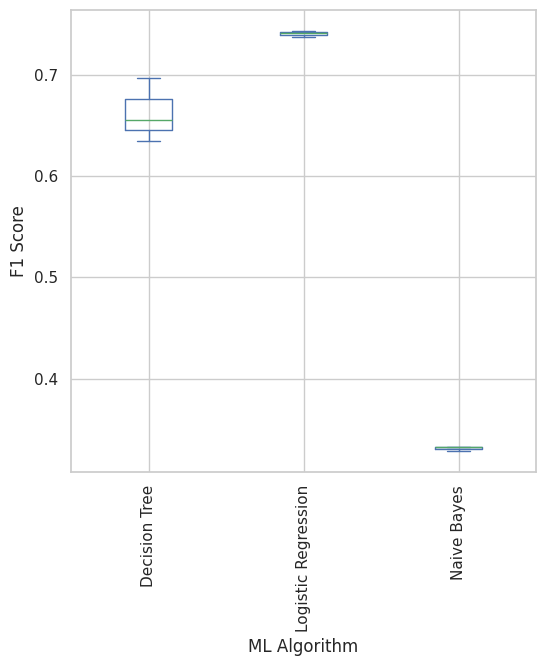

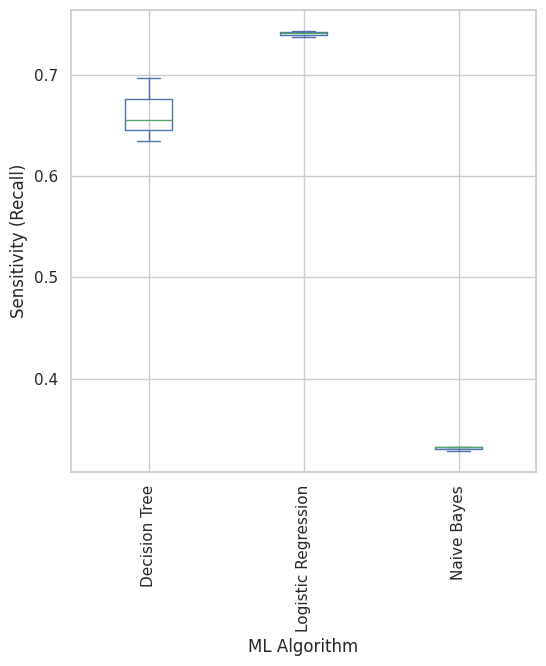

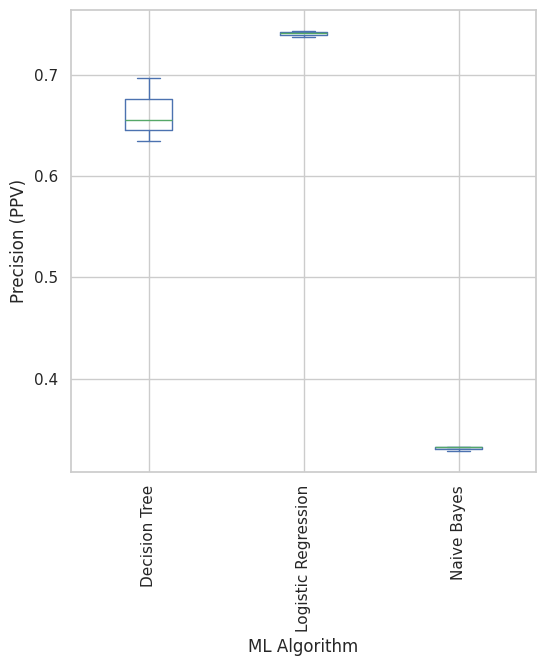

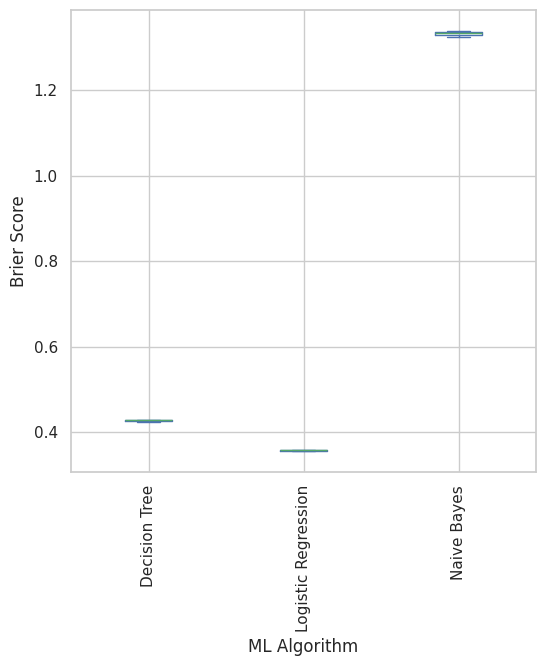

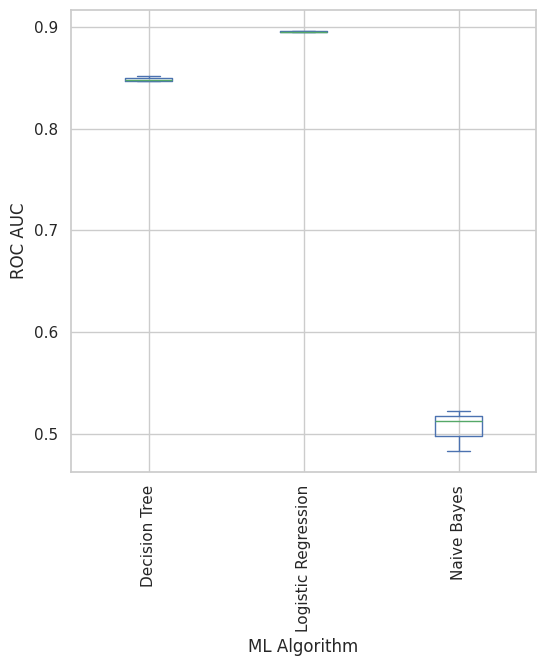

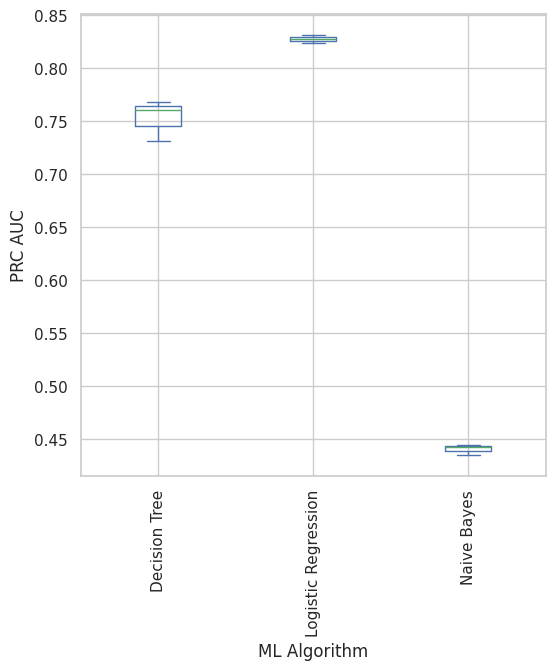

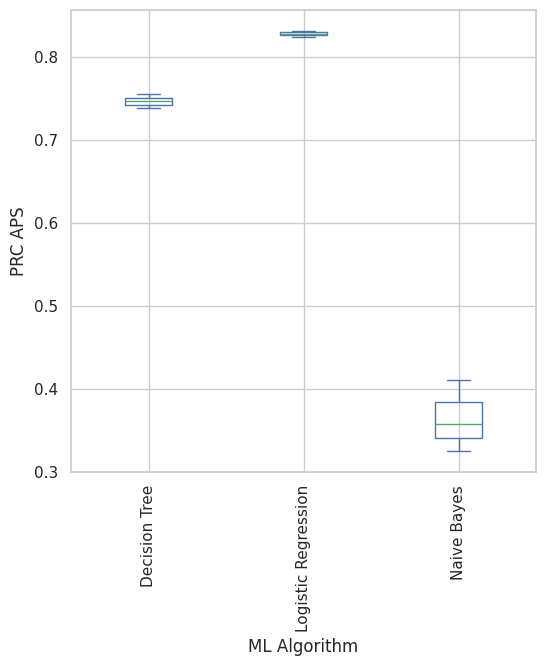

INFO: Running Non-Parametric Statistical Significance Analysis...
INFO: Preparing for Model Feature Importance Plotting...
INFO: Generating Feature Importance Boxplot and Histograms...


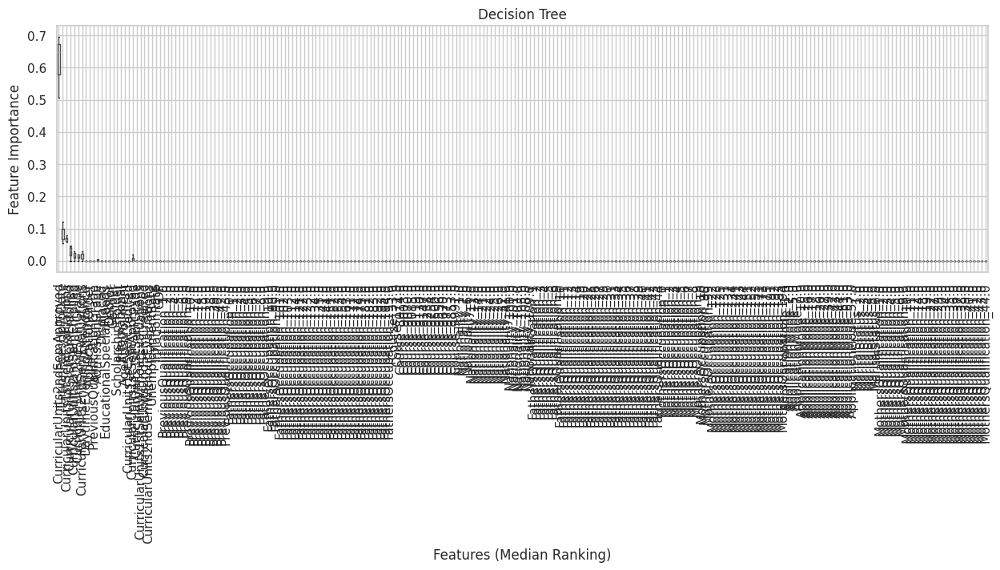

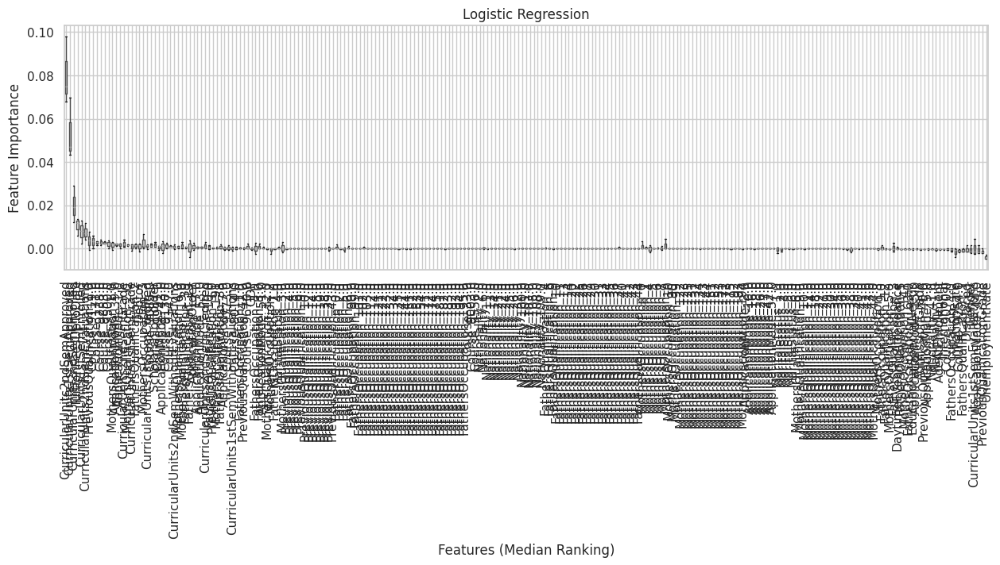

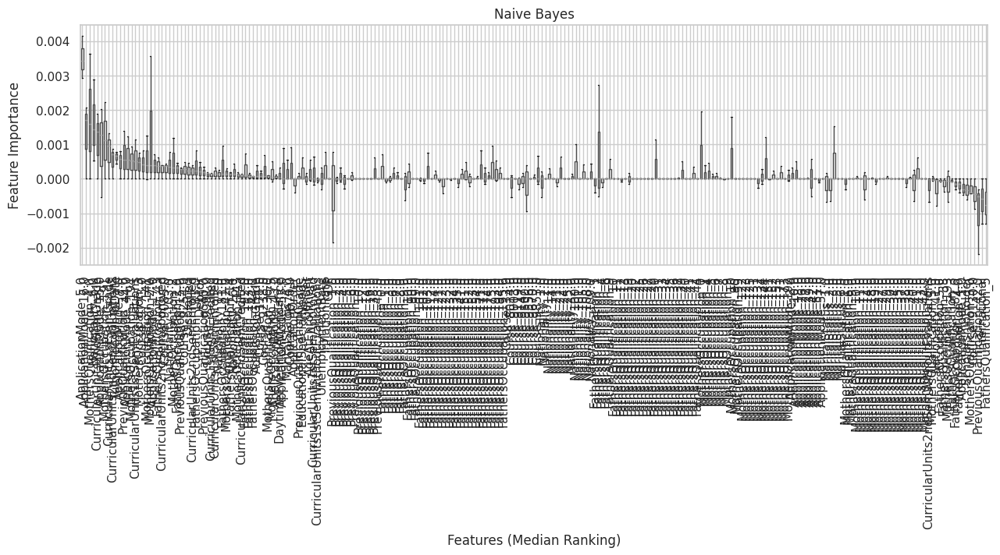

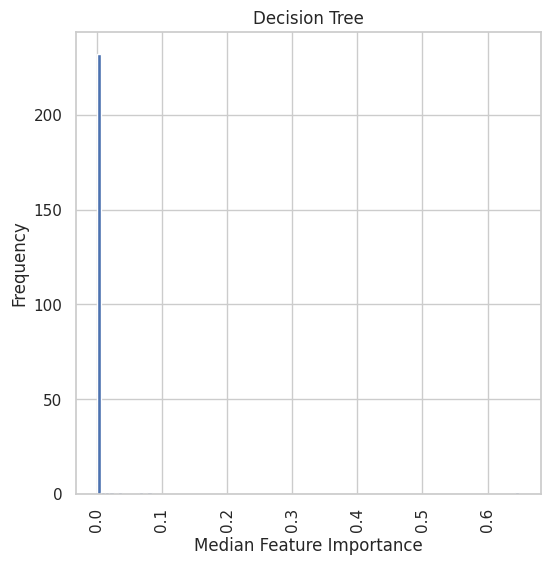

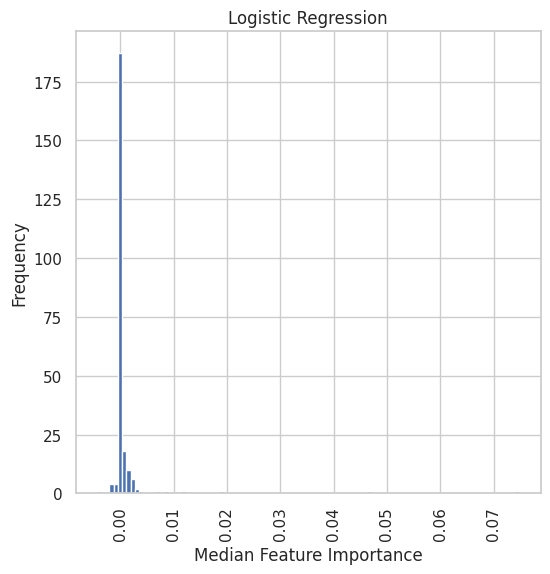

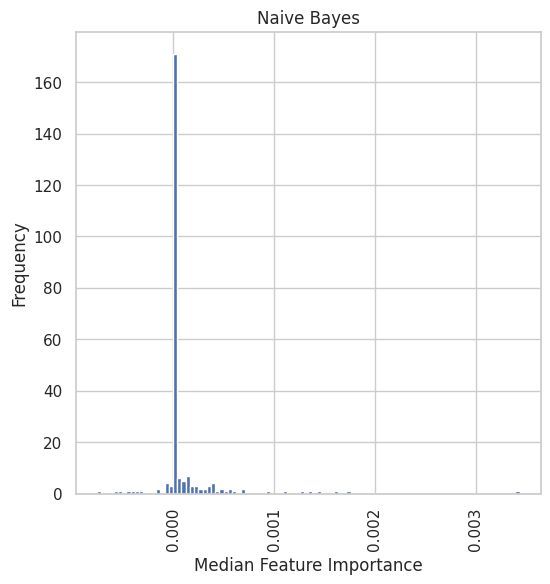

INFO: Generating Composite Feature Importance Plots...


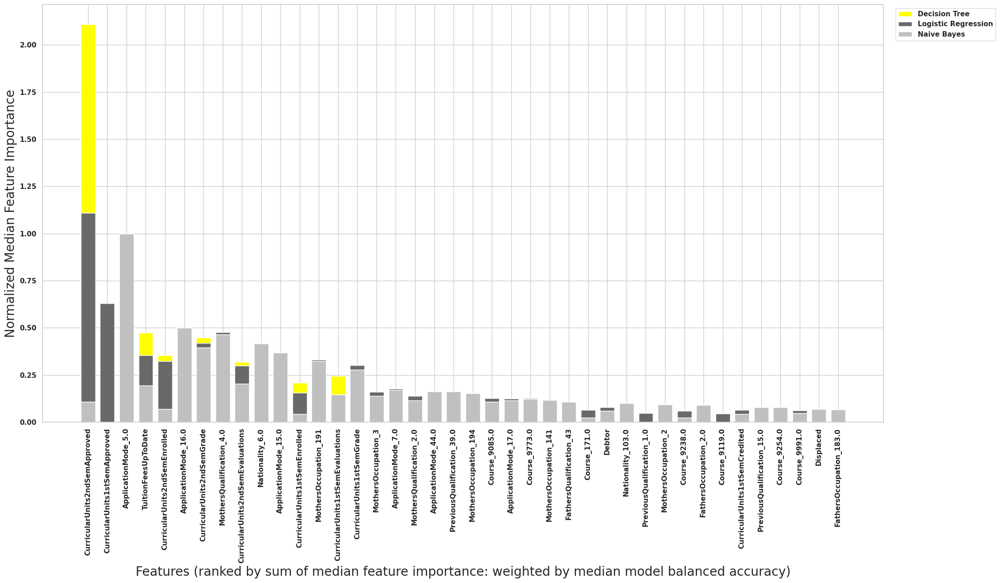

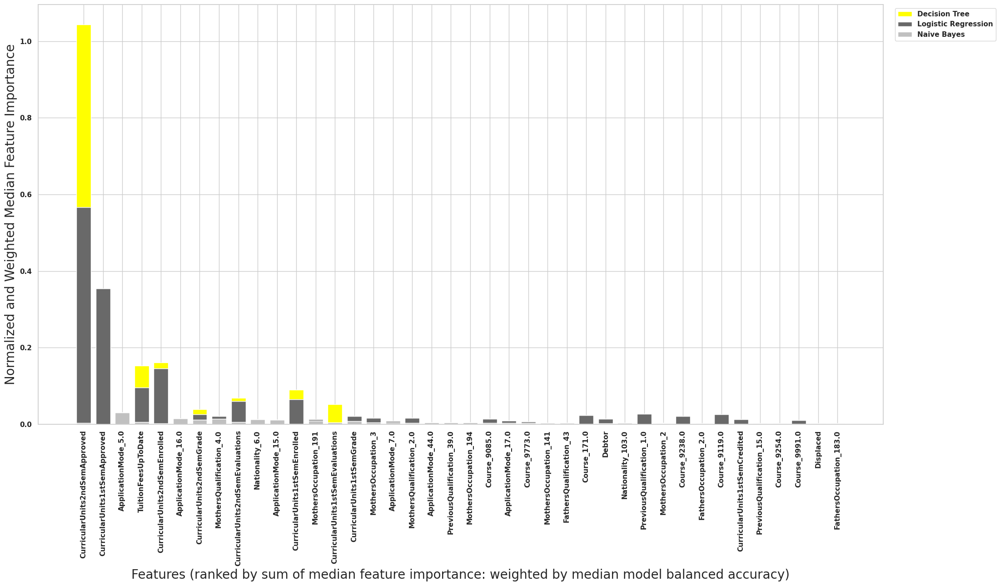

INFO: Collecting ensemble statistics from /content/streamline_output/ColabRun/student_dropout_academic_success/ensemble_evaluation


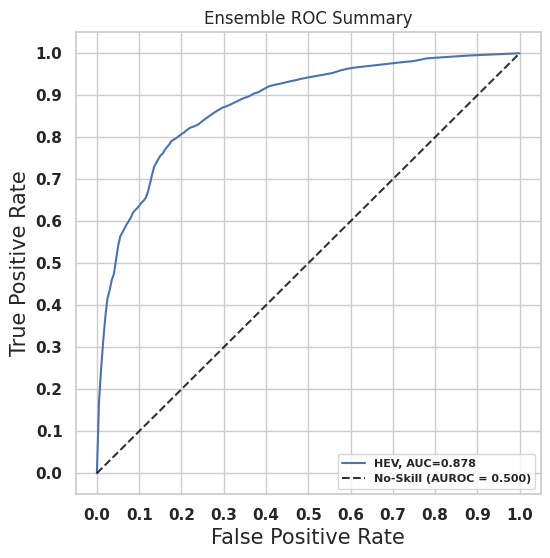

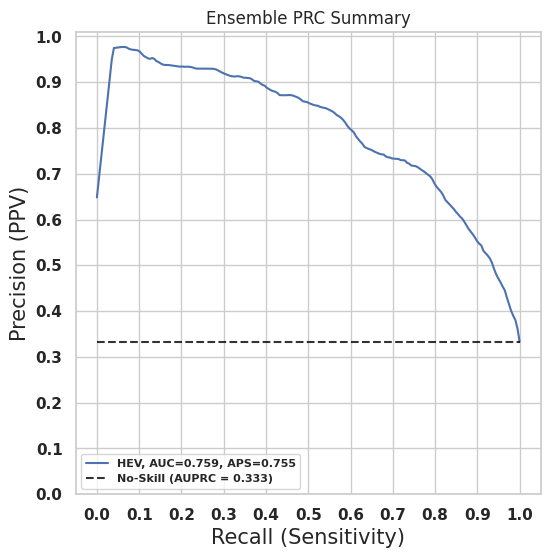

INFO: student_dropout_academic_success statistics phase complete
INFO: Running Statistics Summary for student_dropout_academic_success_copy
INFO: Running stats on Decision Tree


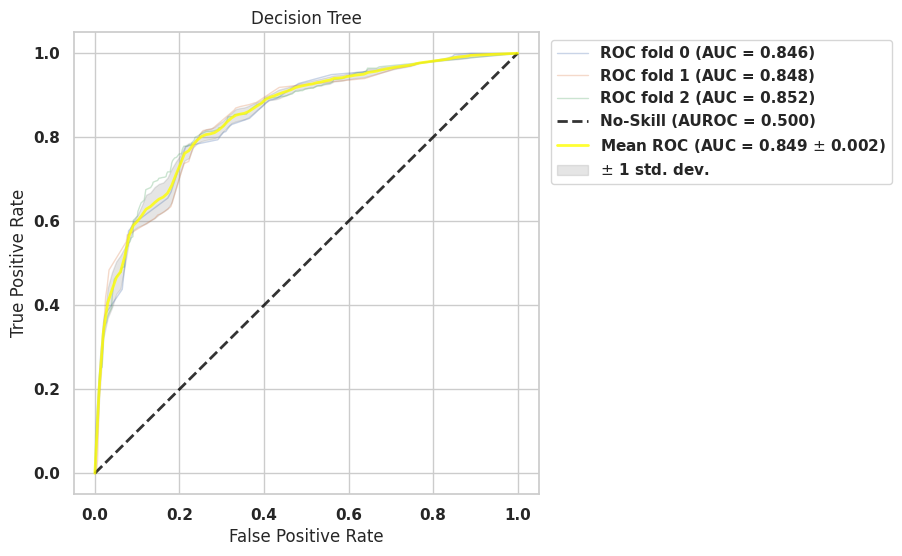

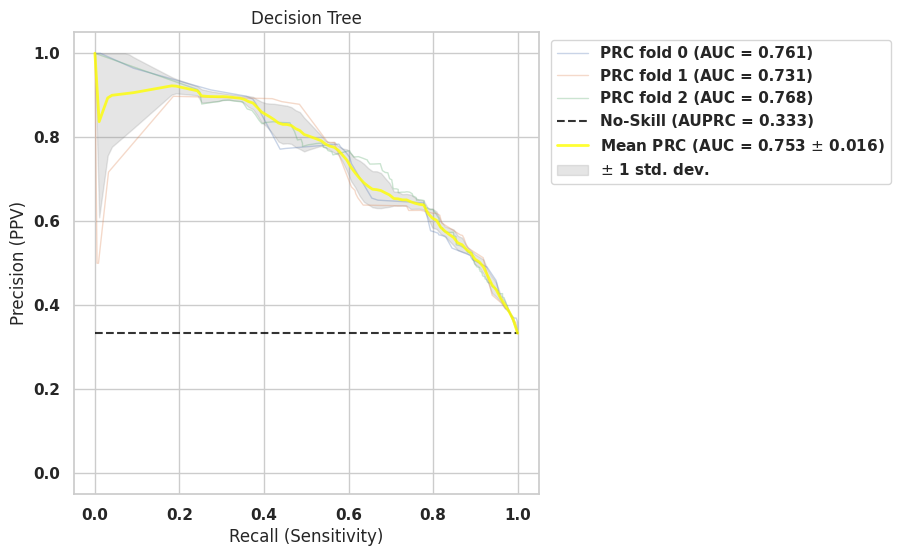

INFO: Running stats on Logistic Regression


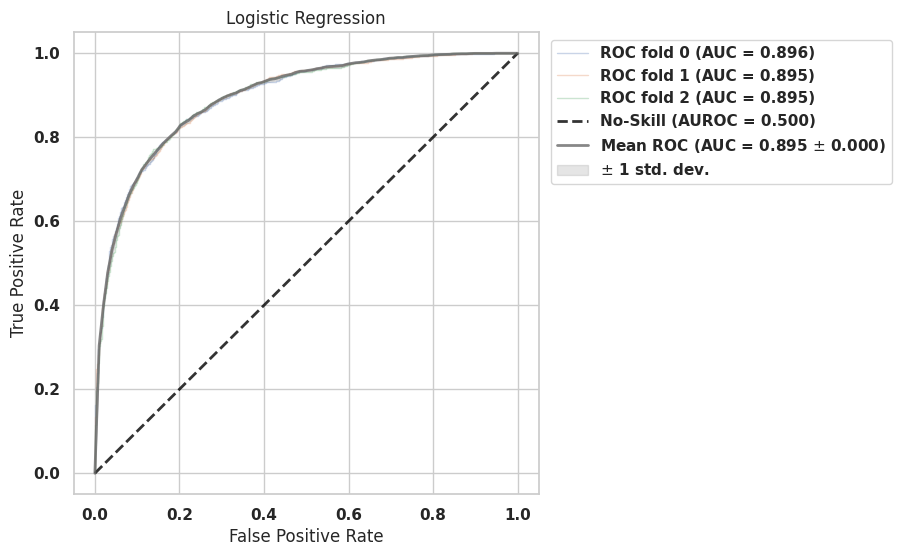

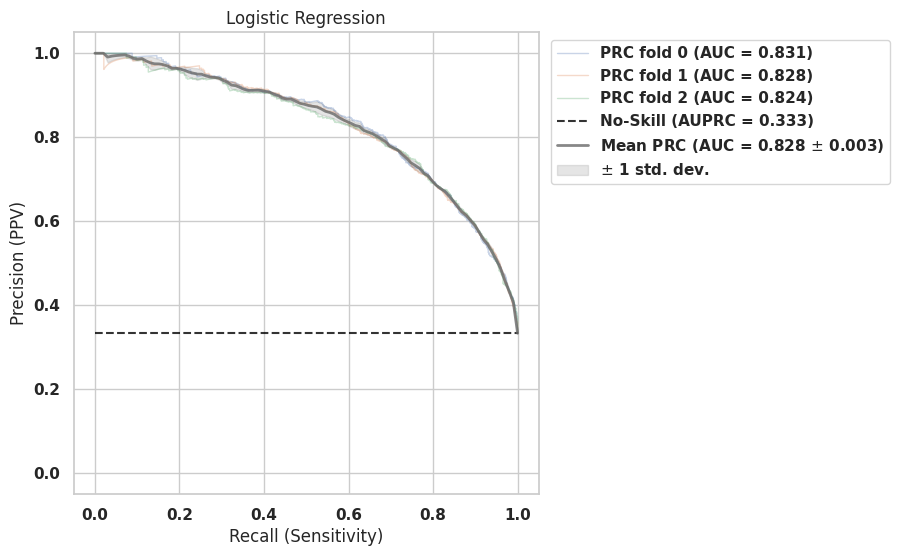

INFO: Running stats on Naive Bayes


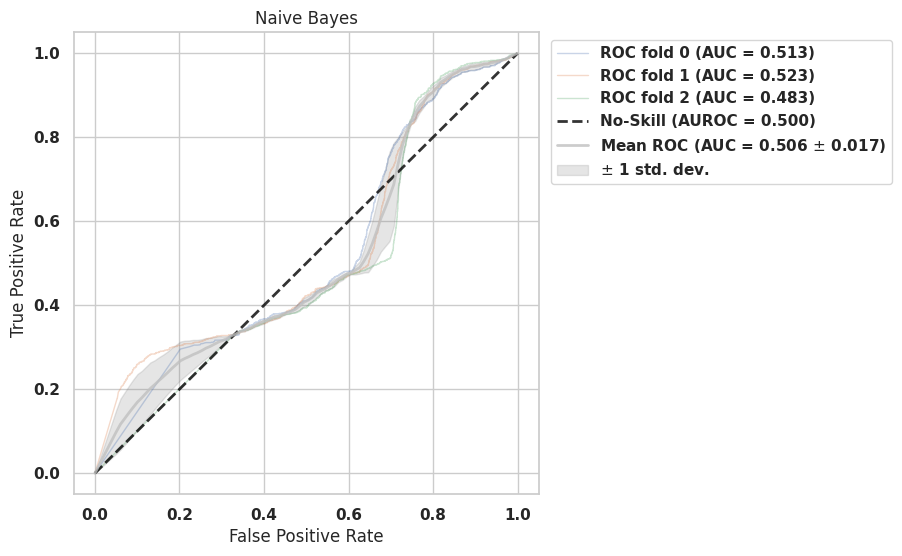

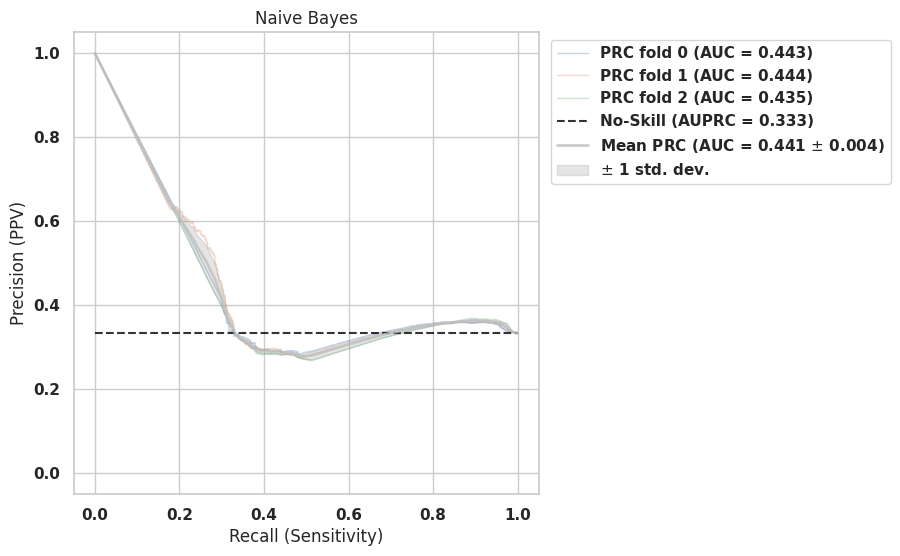

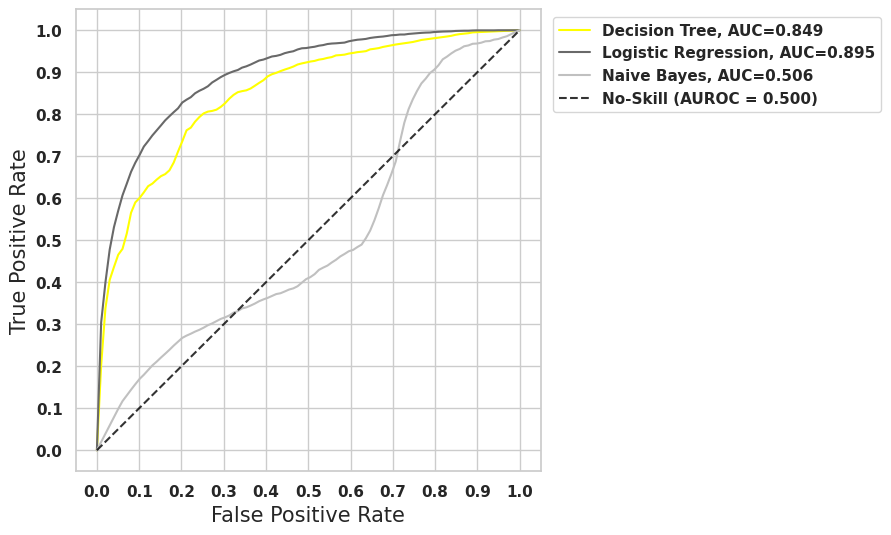

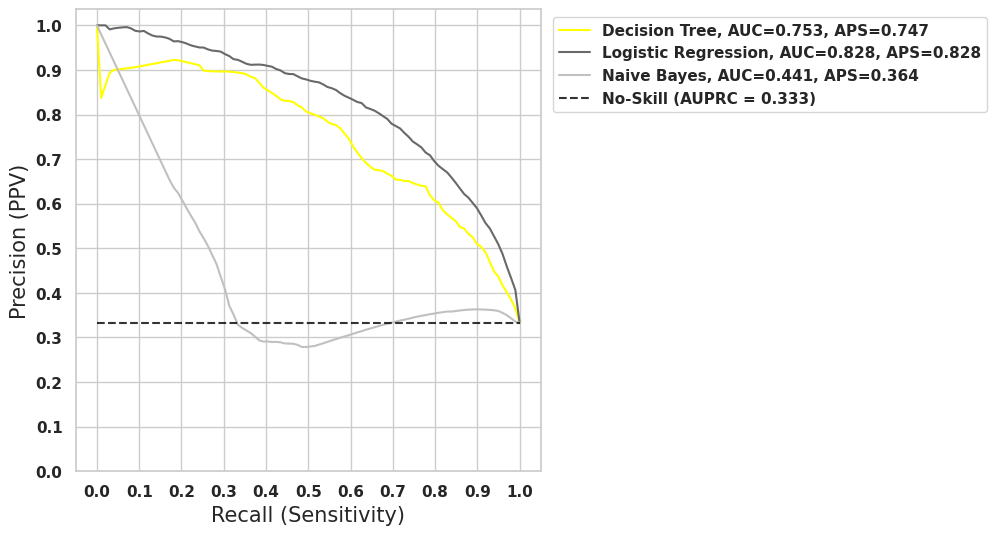

INFO: Saving Metric Summaries...
INFO: Generating Metric Boxplots...


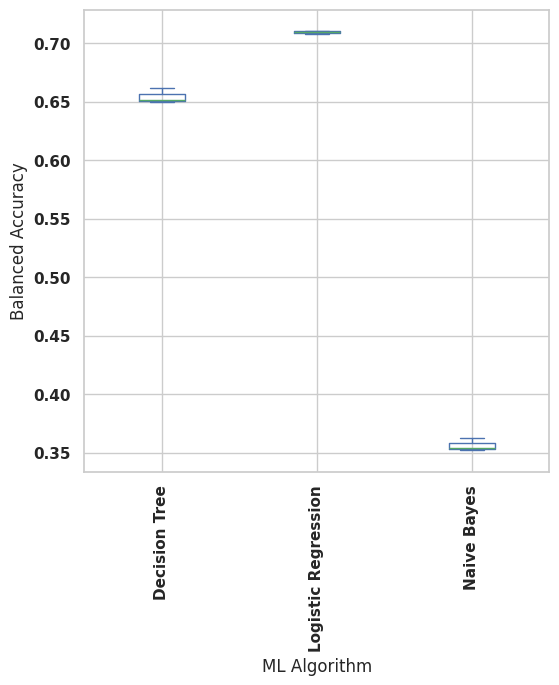

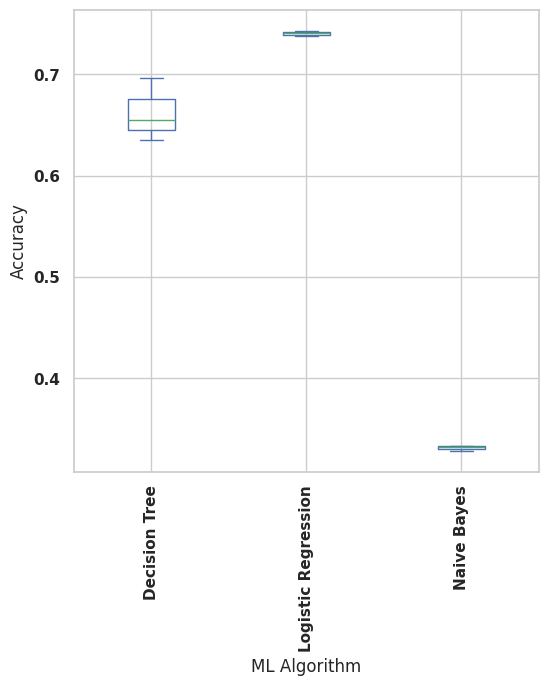

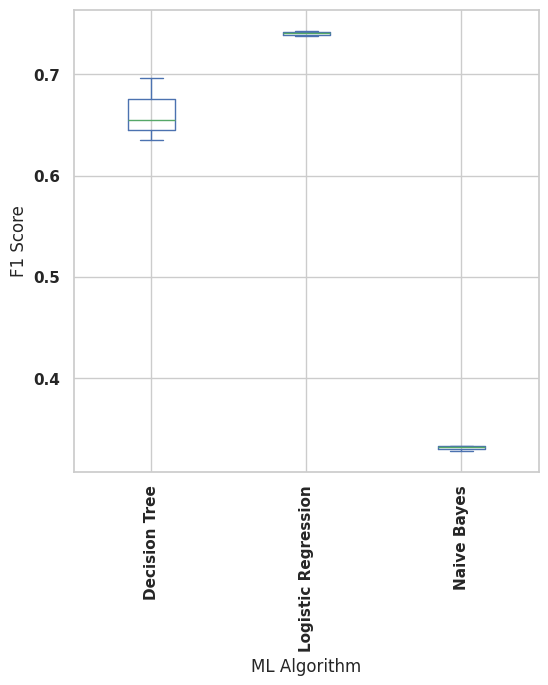

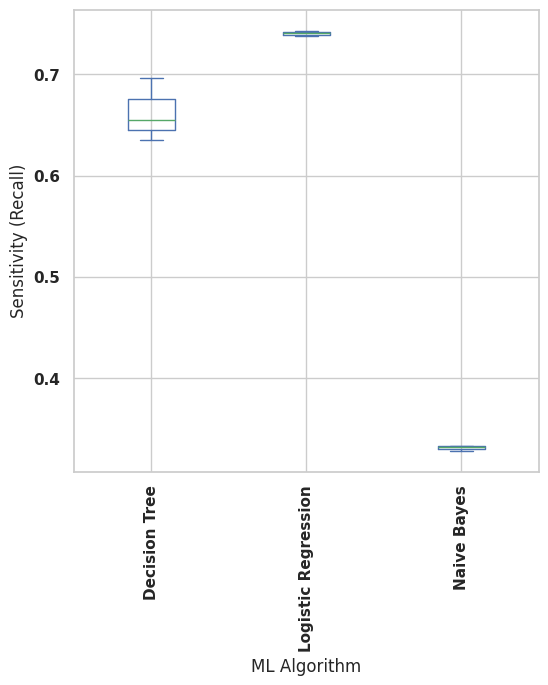

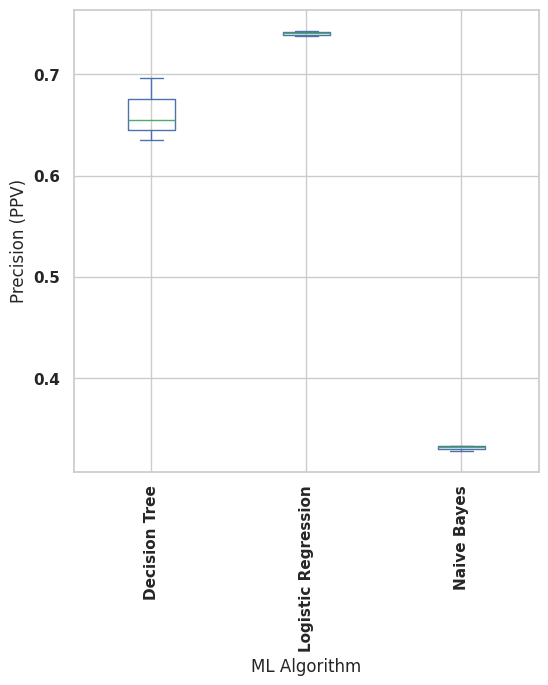

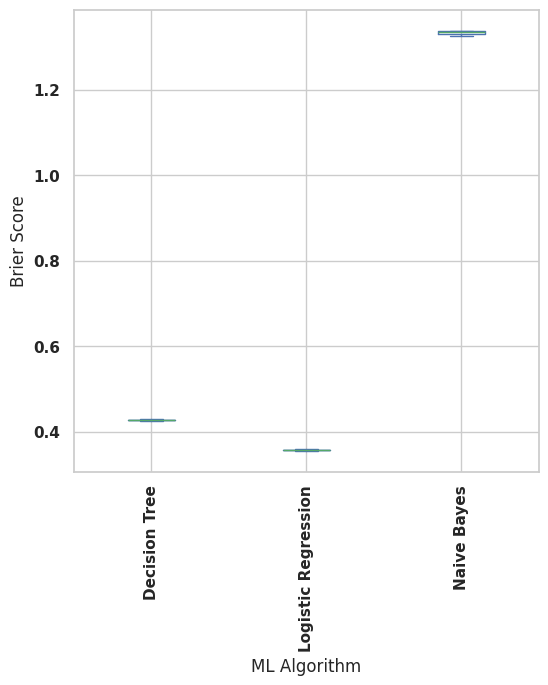

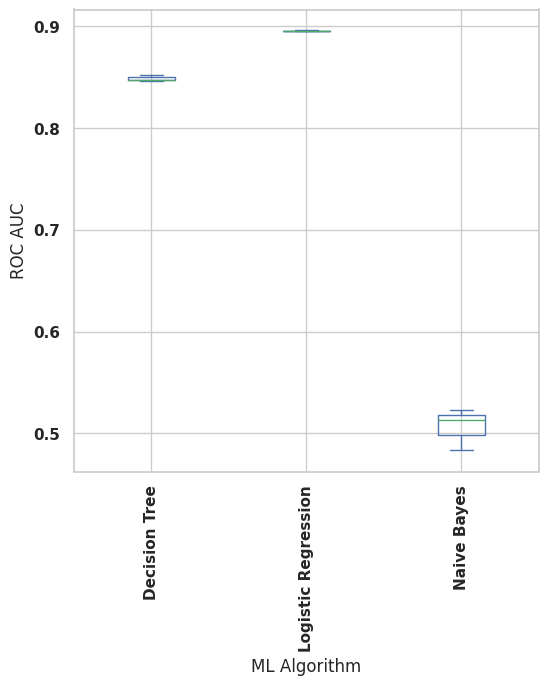

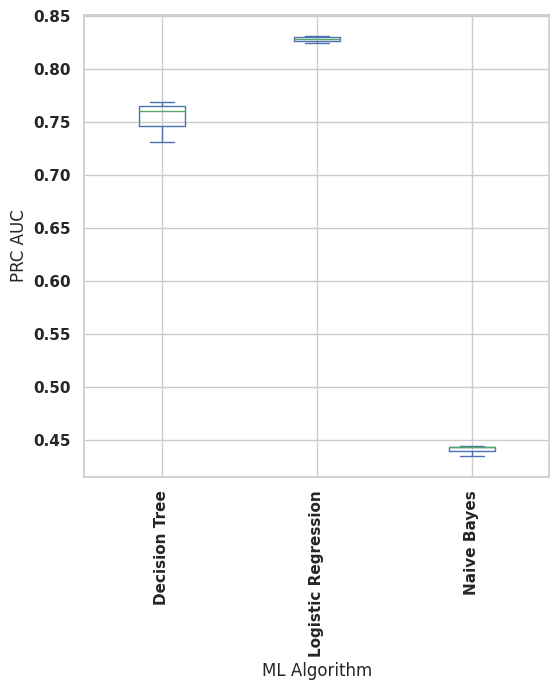

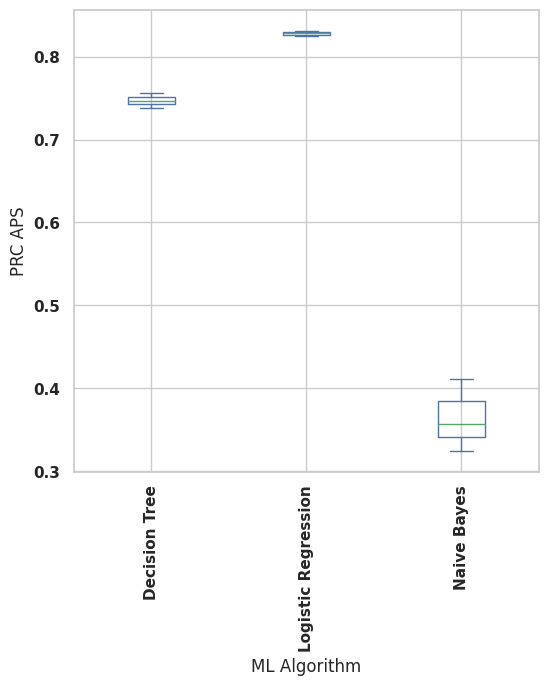

INFO: Running Non-Parametric Statistical Significance Analysis...
INFO: Preparing for Model Feature Importance Plotting...
INFO: Generating Feature Importance Boxplot and Histograms...


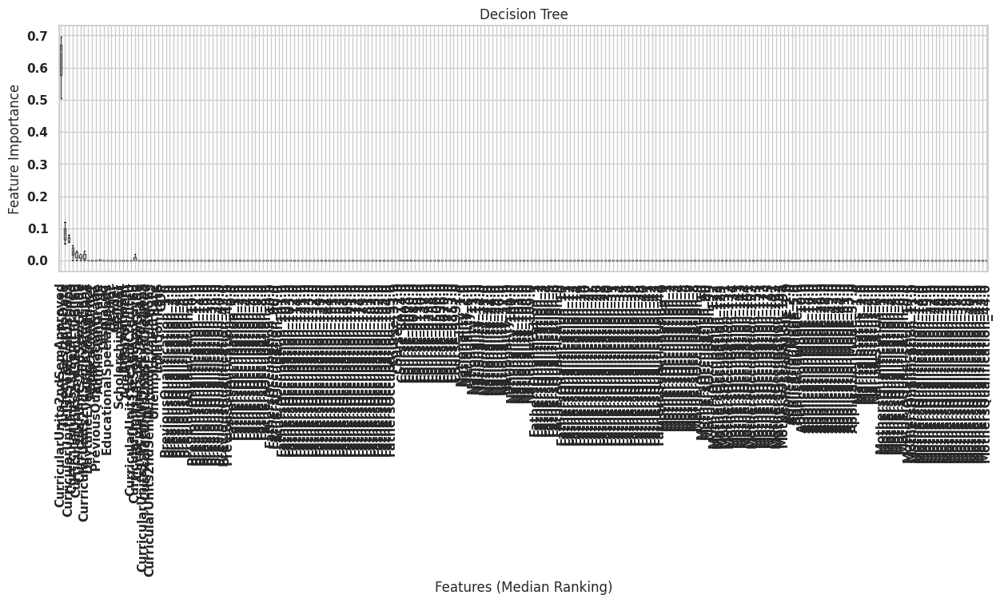

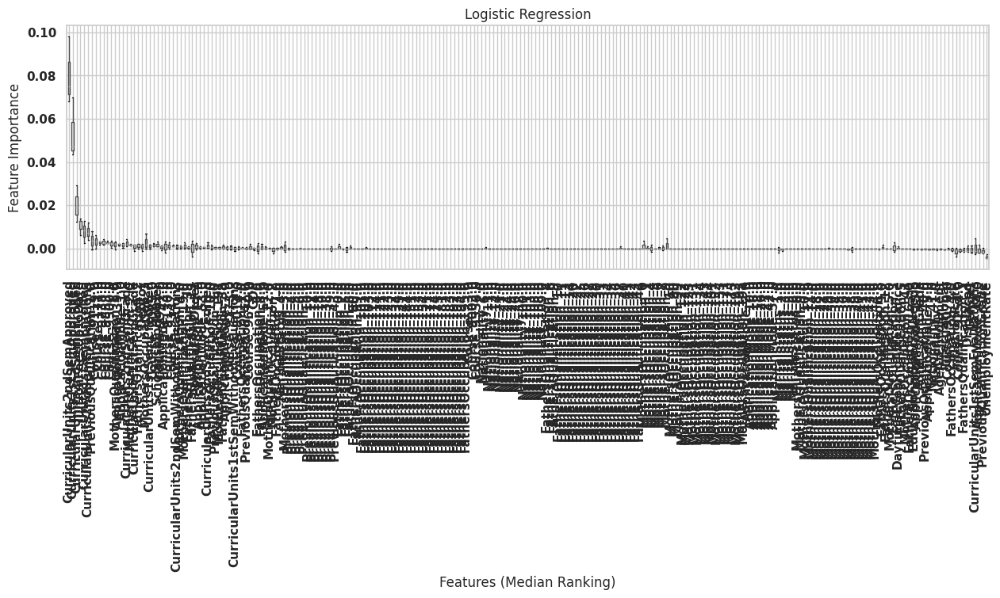

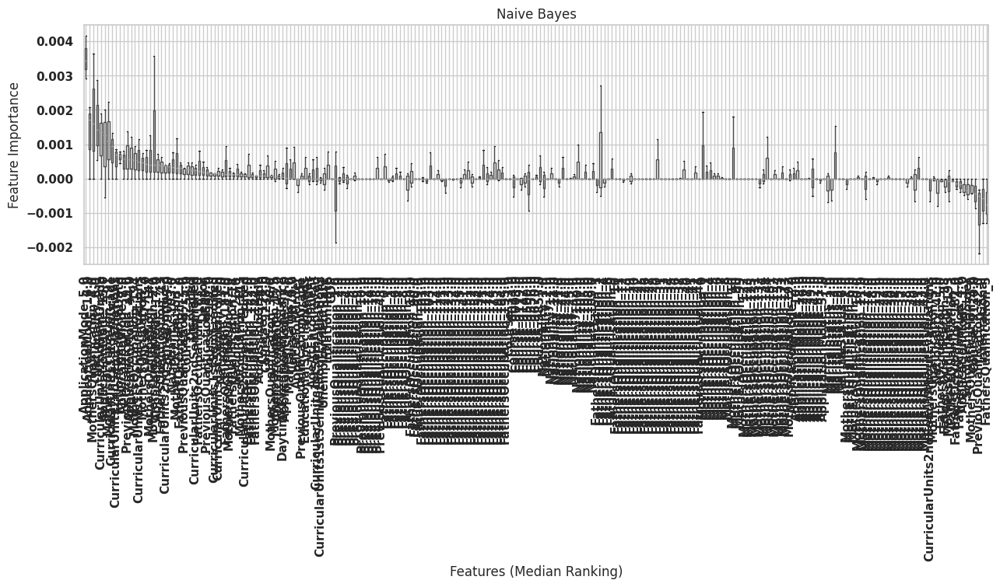

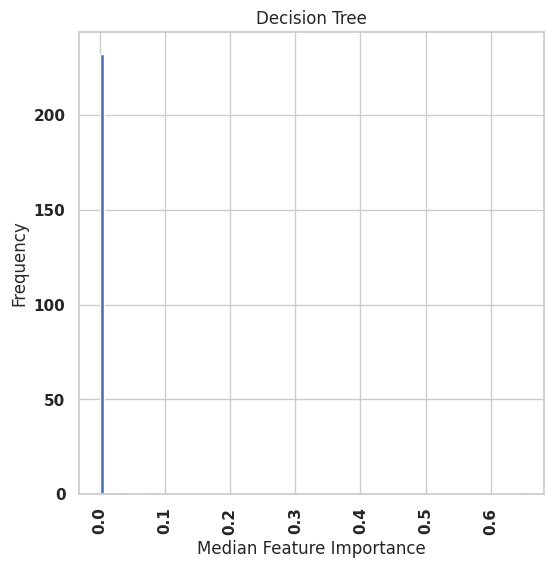

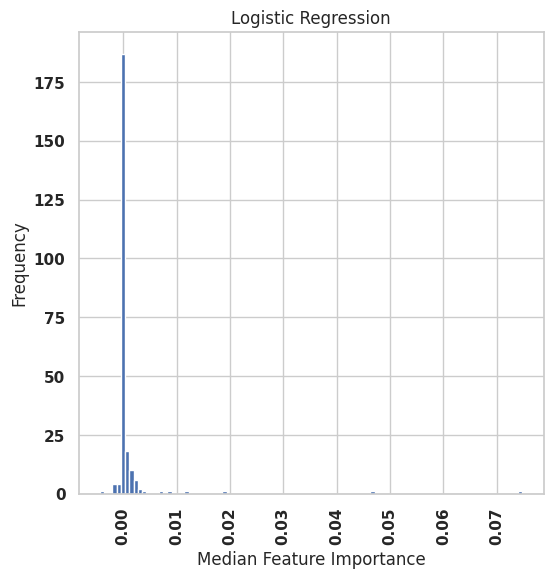

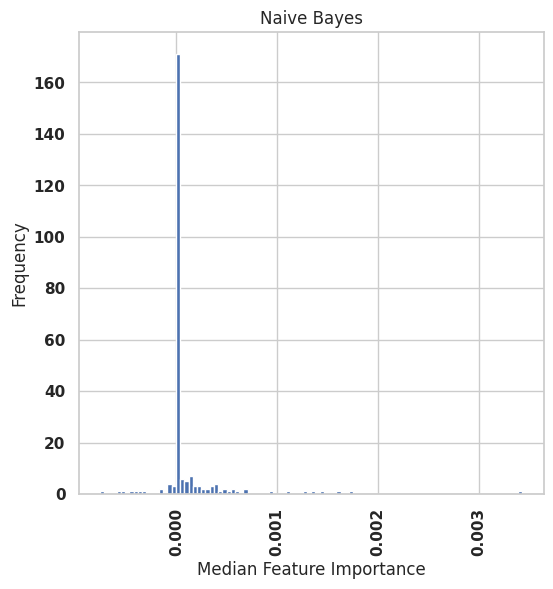

INFO: Generating Composite Feature Importance Plots...


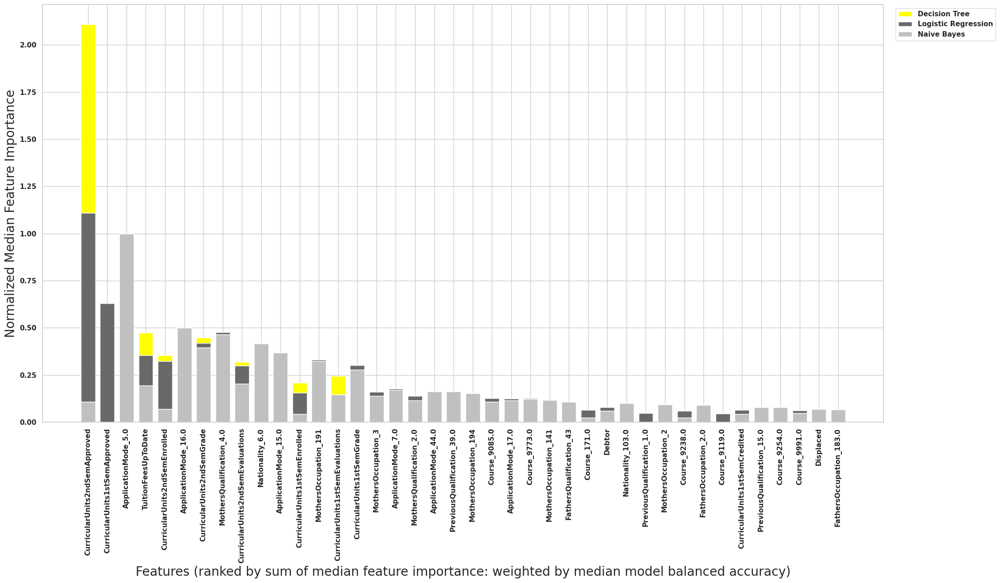

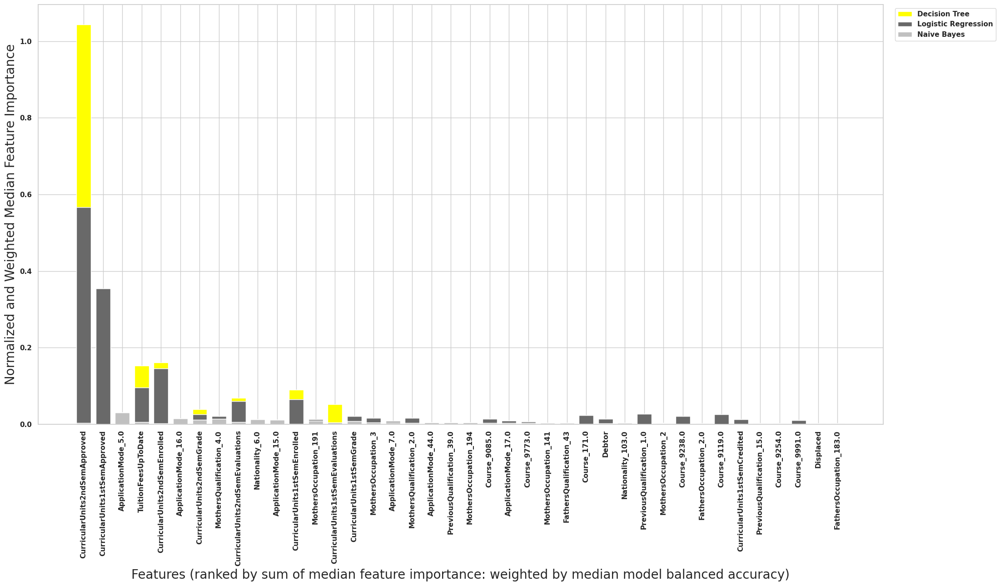

INFO: Collecting ensemble statistics from /content/streamline_output/ColabRun/student_dropout_academic_success_copy/ensemble_evaluation


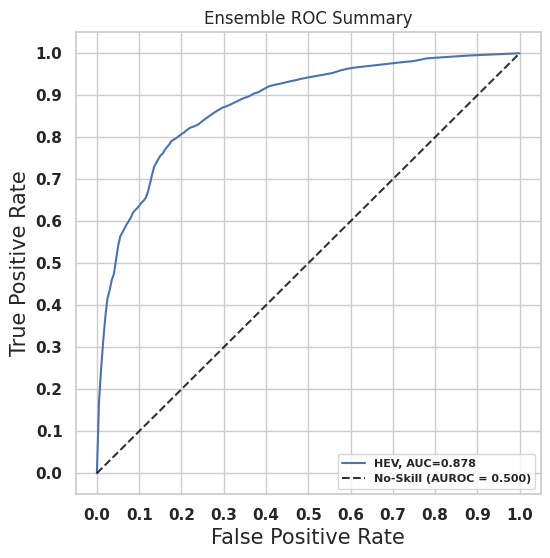

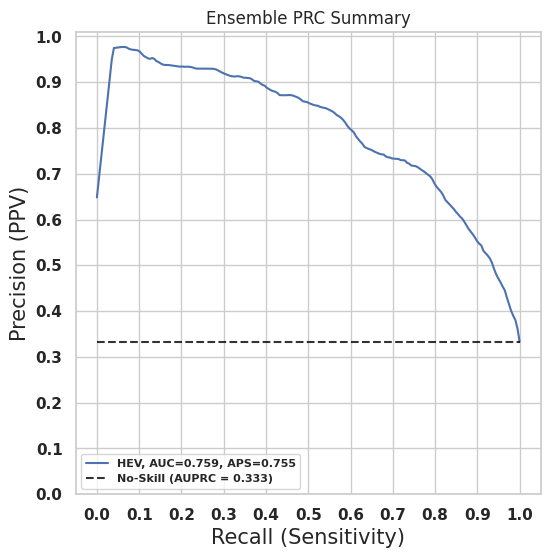

INFO: student_dropout_academic_success_copy statistics phase complete


INFO: Completed Phase 8 - Summary Statistics


In [33]:
if RUN_PHASES["p8"]:
    print("INFO: Starting Phase 8 - Summary Statistics")
    P8Runner(
        output_path=CFG["output_path"],
        experiment_name=CFG["experiment_name"],
        outcome_label=CFG["outcome_label"],
        outcome_type=CFG["outcome_type"],
        instance_label=CFG["instance_label"],
        n_splits=N_SPLITS,
        scoring_metric=P8_SCORING_METRIC or CFG["p8_scoring_metric"],
        metric_weight=P8_METRIC_WEIGHT or CFG["p8_metric_weight"],
        top_features=P8_TOP_FEATURES,
        sig_cutoff=P8_SIG_CUTOFF,
        scale_data=P8_SCALE_DATA,
        exclude_plots=P8_EXCLUDE_PLOTS,
        show_plots=P8_SHOW_PLOTS,
        include_ensembles=run_p7 if P8_INCLUDE_ENSEMBLES is None else P8_INCLUDE_ENSEMBLES,
        multiclass_average=P8_MULTICLASS_AVERAGE,
        run_cluster=RUN_CLUSTER,
        queue=PHASE_QUEUE,
        reserved_memory=PHASE_RESERVED_MEMORY_GB,
    ).run()
    print("INFO: Completed Phase 8 - Summary Statistics")
else:
    print("INFO: Phase 8 skipped")


## Phase 9: Dataset Comparison
Optional phase, used only when two or more target datasets were analyzed. It compares performance distributions across datasets and saves outputs under `DatasetComparisons/`.


### تنفيذ المرحلة التاسعة P9

- `list_dataset_dirs` يبحث داخل مجلد التجربة عن المجلدات التي تحتوي `CVDatasets`، ويتجاهل مجلدات السجلات والتقارير.
- يحسب الكود عدد مجموعات البيانات؛ إذا كانت اثنتين أو أكثر يستدعي `P9Runner` للمقارنة، وإلا يتجاوز المرحلة برسالة واضحة.
**الفائدة:** مقارنة أداء النماذج عبر مجموعات بيانات متعددة دون تشغيل غير ضروري.

### شرح هذه الخلية: تشغيل المرحلة التاسعة P9 لمقارنة البيانات
- `list_dataset_dirs`: تبحث عن مجلدات التجارب/البيانات التي تحتوي `CVDatasets` وتتجاهل مجلدات السجلات والتقارير.
- بعدها يحسب عدد مجموعات البيانات.
- إذا توفر مجموعتان أو أكثر، تبدأ المقارنة الإحصائية بينها؛ وإلا فلا توجد مقارنة متعددة يمكن تنفيذها.

INFO: Running dataset comparison (Phase 9) for experiment ColabRun
INFO: Running Kruskal-Wallis across datasets...


INFO: Starting Phase 9 - Dataset Comparison


INFO: Running Mann-Whitney U across datasets...
INFO: Running Wilcoxon rank-sum across datasets...
INFO: Running 'best algorithm per dataset' Kruskal-Wallis...
INFO: Running 'best algorithm per dataset' Mann-Whitney...
INFO: Running 'best algorithm per dataset' Wilcoxon rank...
INFO: Generating dataset comparison boxplots (all models)...


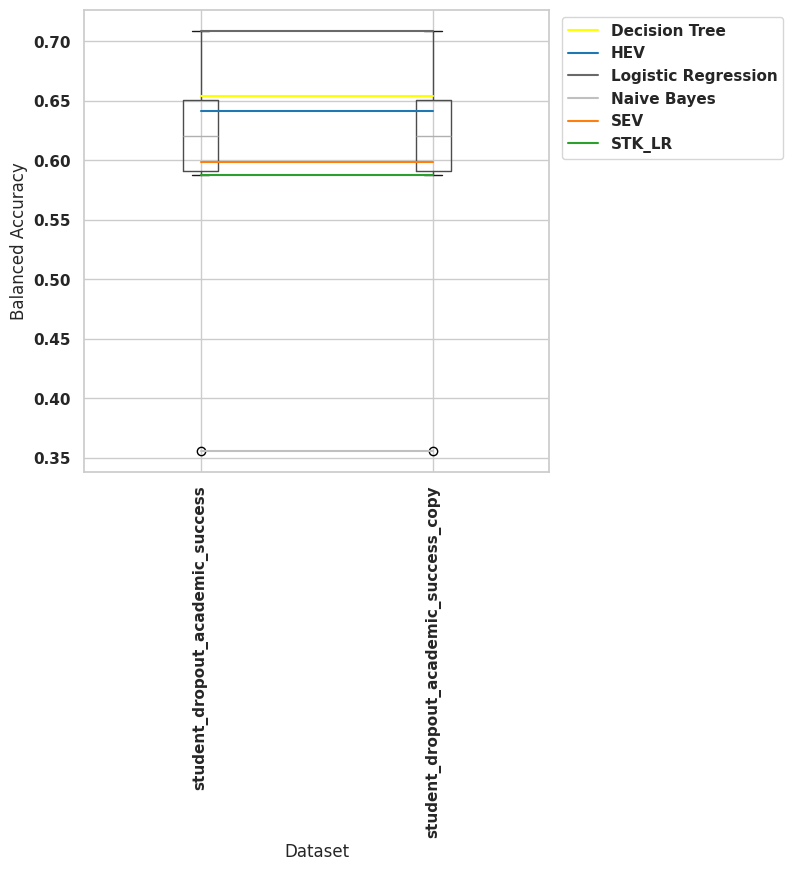

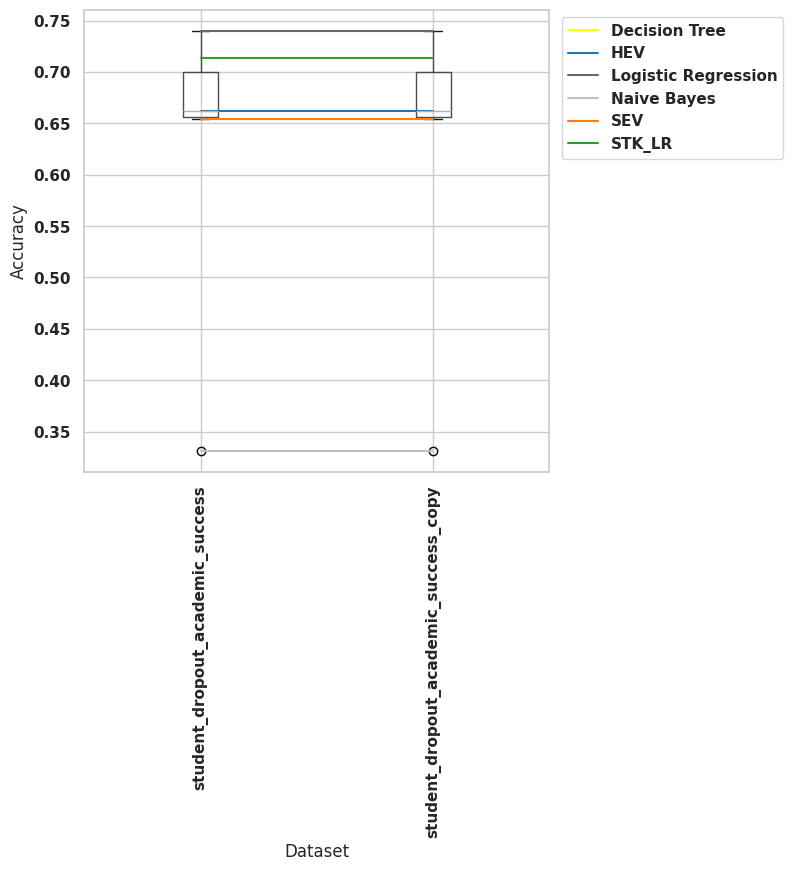

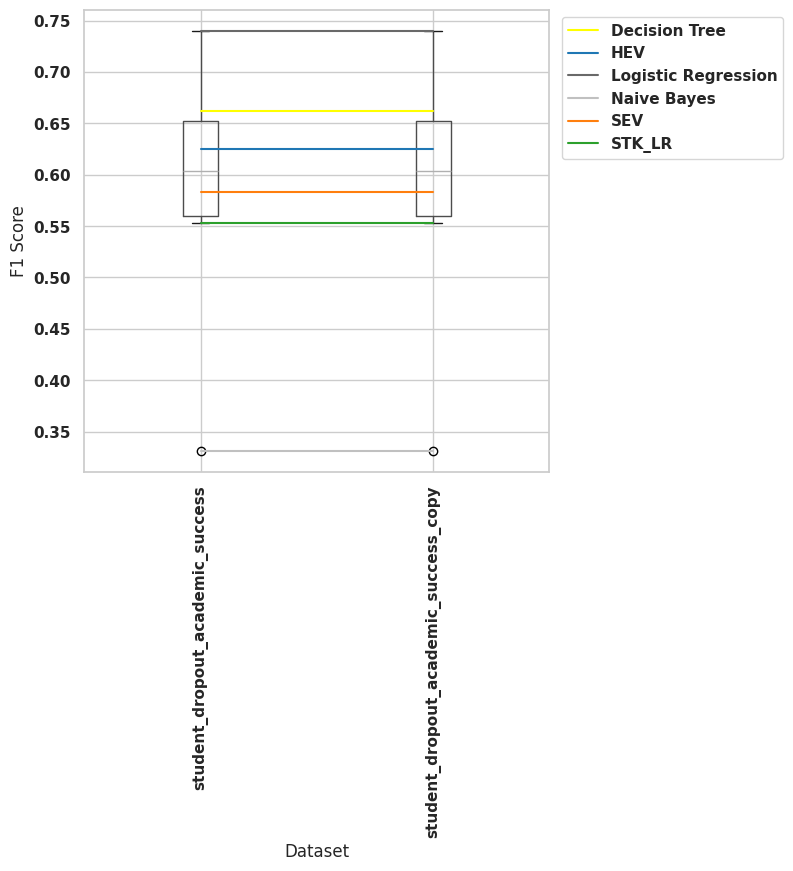

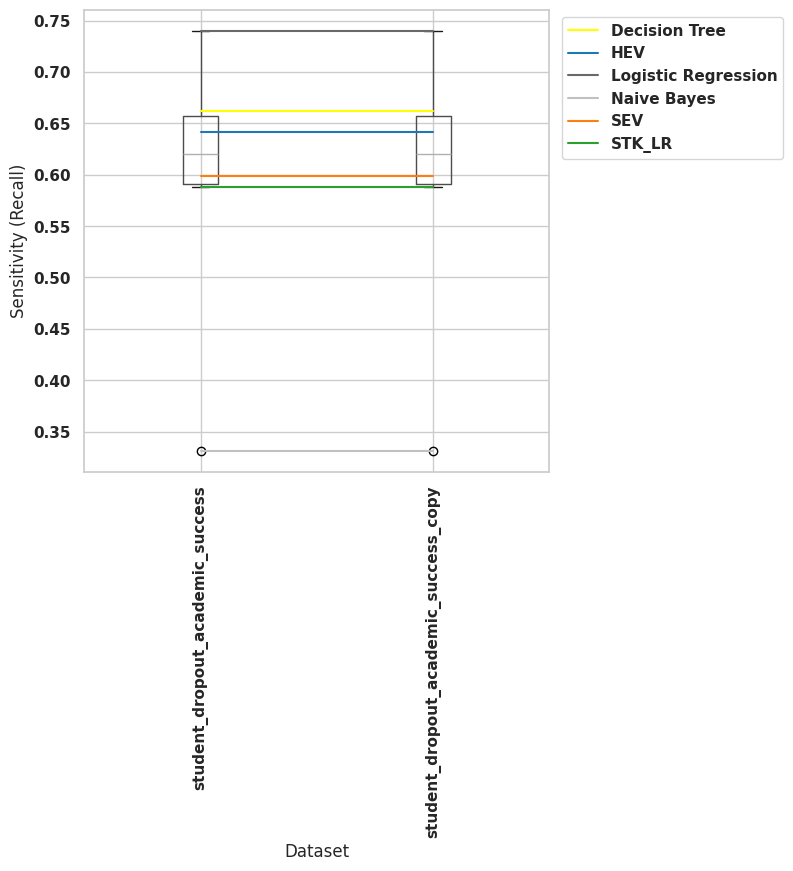

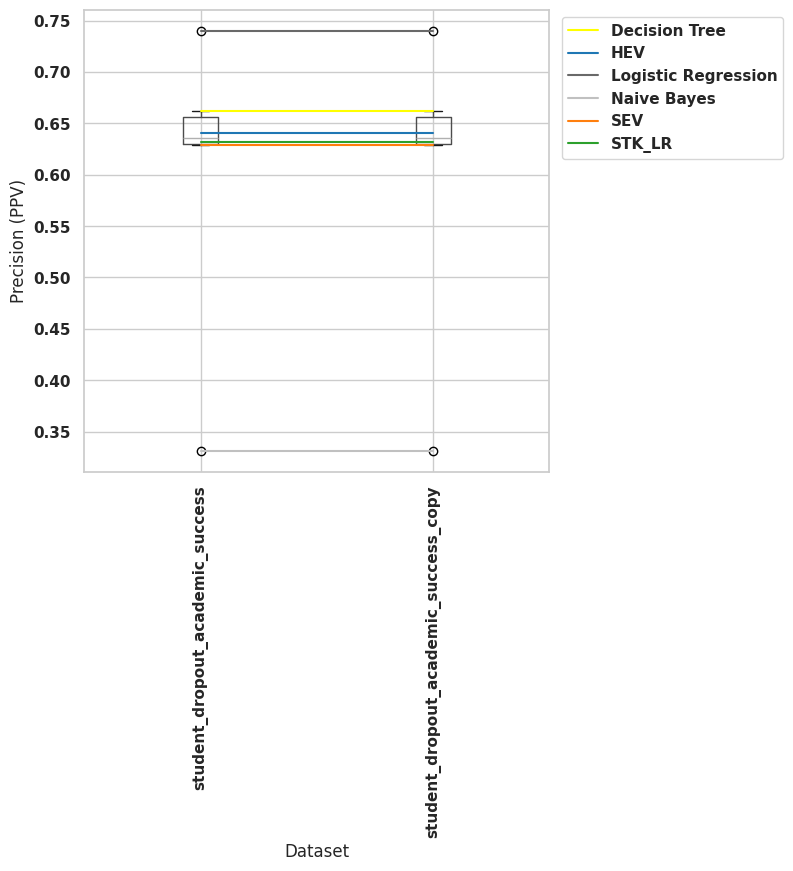

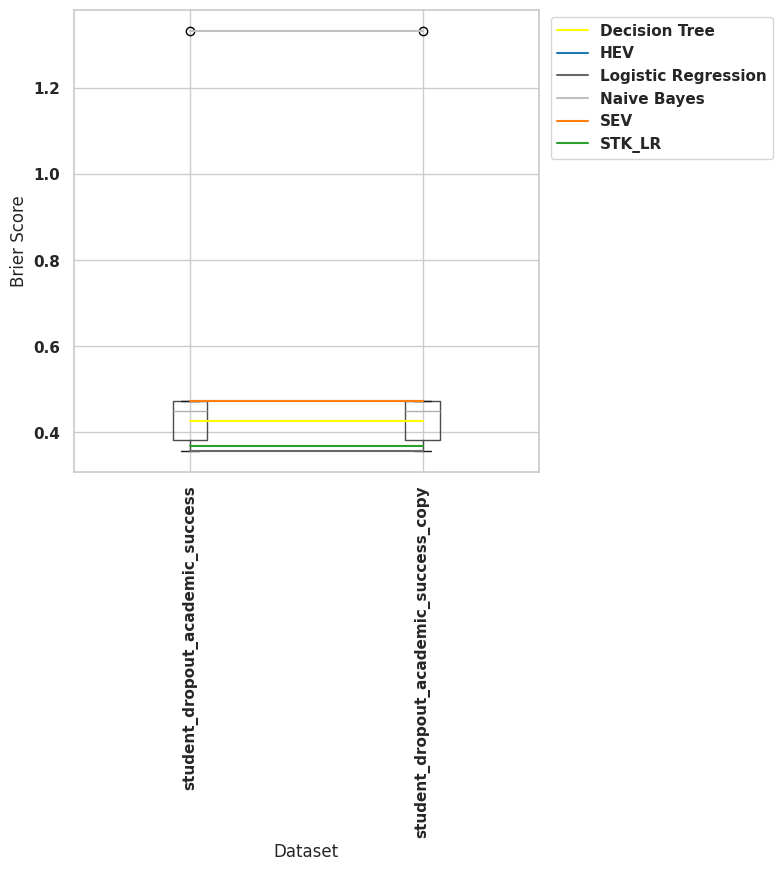

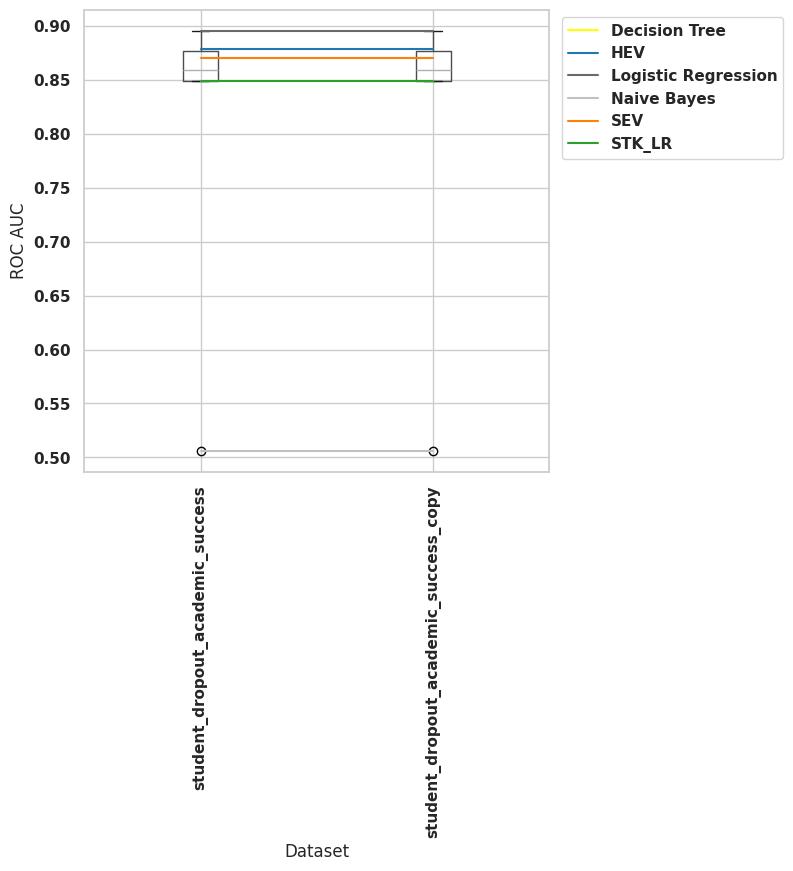

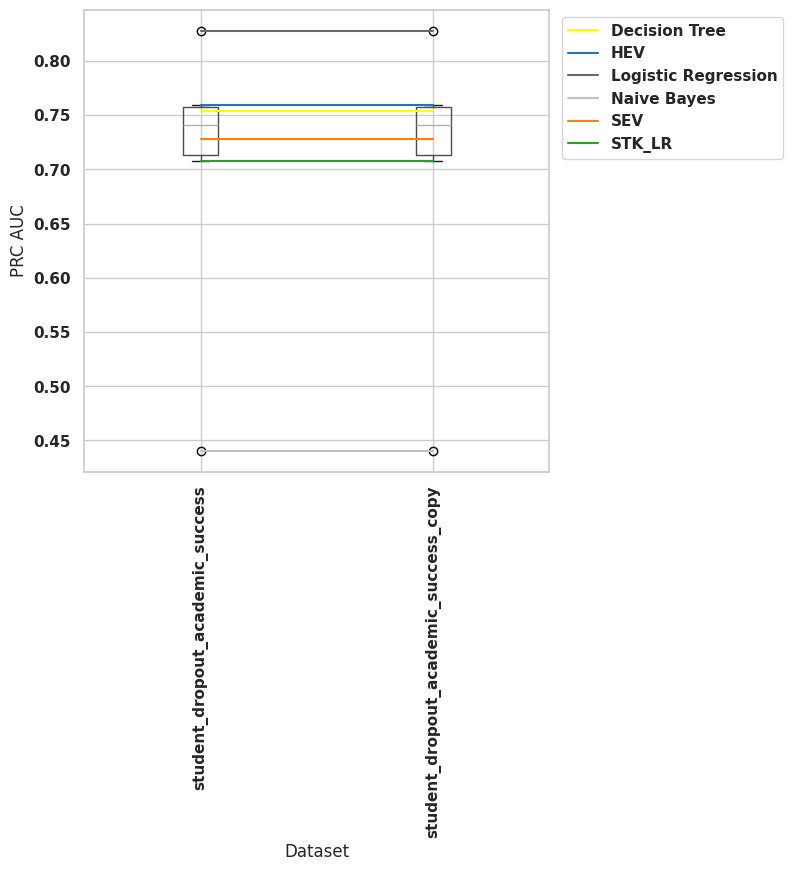

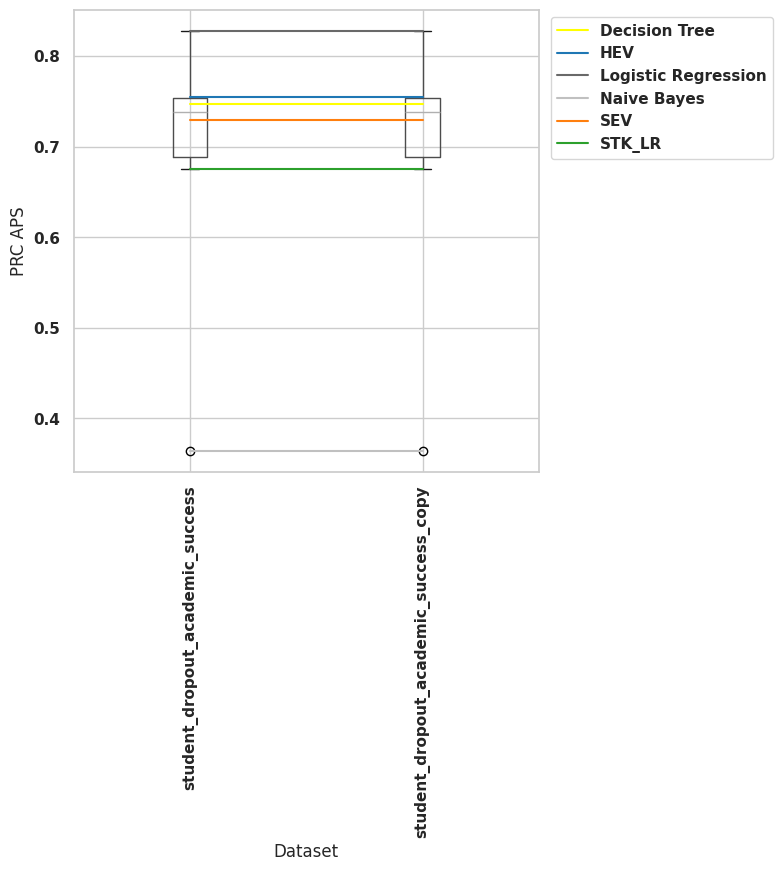

INFO: Generating dataset comparison boxplots (per algorithm)...
INFO: Phase 9 dataset comparison complete.


INFO: Completed Phase 9 - Dataset Comparison


In [34]:
def list_dataset_dirs(exp_root: Path):
    ignore = {"jobs", "logs", "jobsCompleted", "dask_logs", "DatasetComparisons", "reporting", "reporting_replication"}
    if not exp_root.exists():
        return []
    return [
        p for p in sorted(exp_root.iterdir())
        if p.is_dir() and p.name not in ignore and (p / "CVDatasets").is_dir()
    ]

if RUN_PHASES["p9"]:
    print("INFO: Starting Phase 9 - Dataset Comparison")
    ds_count = len(list_dataset_dirs(EXP_ROOT))
    if ds_count >= 2:
        P9Runner(
            output_path=CFG["output_path"],
            experiment_name=CFG["experiment_name"],
            outcome_label=CFG["outcome_label"],
            outcome_type=CFG["outcome_type"],
            instance_label=CFG["instance_label"],
            sig_cutoff=P9_SIG_CUTOFF,
            show_plots=P9_SHOW_PLOTS,
            run_cluster=RUN_CLUSTER,
            queue=PHASE_QUEUE,
            reserved_memory=PHASE_RESERVED_MEMORY_GB,
        ).run()
        print("INFO: Completed Phase 9 - Dataset Comparison")
    else:
        print(f"INFO: Phase 9 skipped - requires >=2 datasets, found {ds_count}")
else:
    print("INFO: Phase 9 skipped")


## Phase 10: Replication
Optional phase, used when replication data is available. Trained models are re-evaluated on the same replication dataset(s), giving a uniform external or held-out performance check.


### تنفيذ المرحلة العاشرة P10

يحدد مسار بيانات التكرار وملف البيانات المرجعي من الإعدادات أو القيم الافتراضية، ثم يتحقق من وجودهما. عند توفرهما يستدعي `P10Runner` لتقييم النماذج على بيانات التكرار؛ وإلا يطبع سبب التجاوز.
**الفائدة:** اختبار خارجي/مستقل للنماذج وتقييم قابلية تعميمها.

### شرح هذه الخلية: تشغيل المرحلة العاشرة P10 للتحقق الخارجي
تحدد مسار بيانات التكرار والملف المرجعي وأسماء أعمدة المطابقة.
إذا كانت الملفات موجودة، تستدعي `P10Runner` لتقييم النتائج على بيانات مستقلة؛ وإذا لم تكن موجودة، تتخطى المرحلة بدلًا من محاولة قراءة مسار غير متوفر.

INFO: Starting Phase 10 - Replication


INFO: Running Statistics Summary for student_dropout_academic_success_rep
INFO: Running stats on Decision Tree


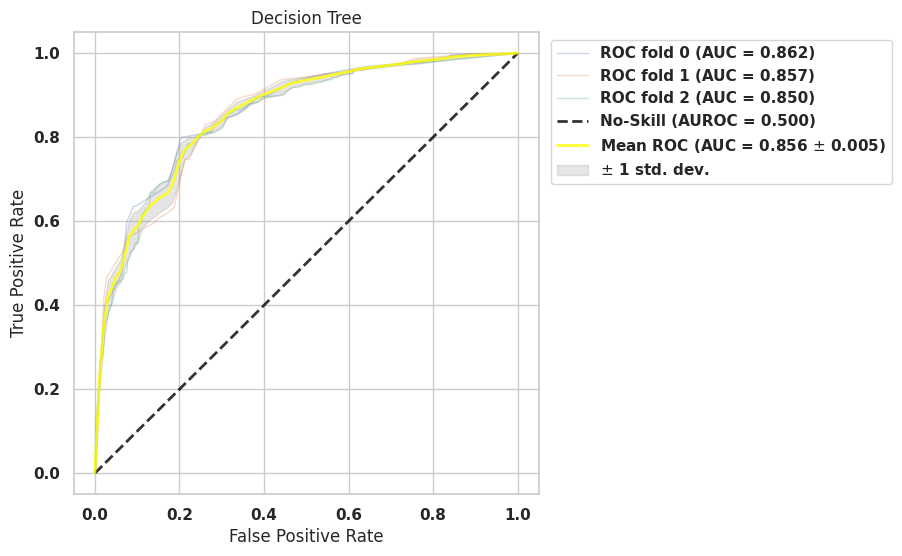

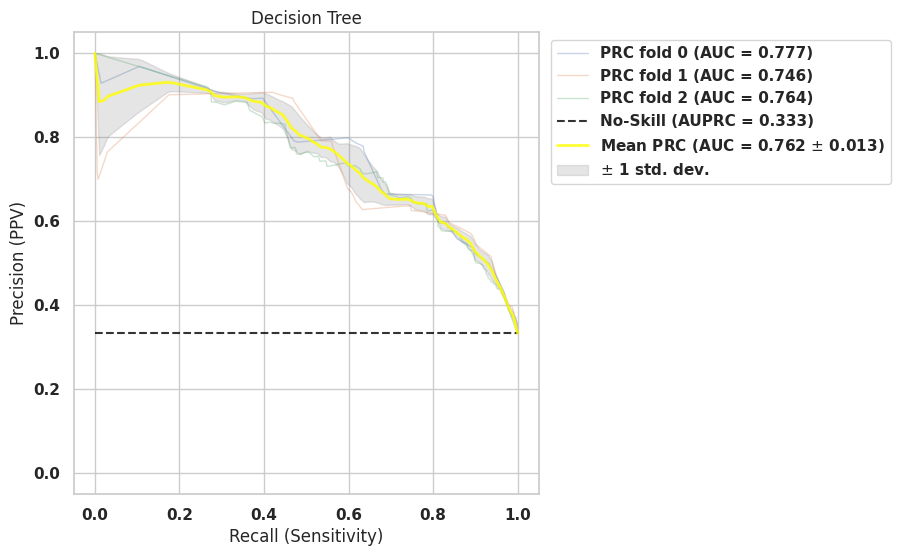

INFO: Running stats on Logistic Regression


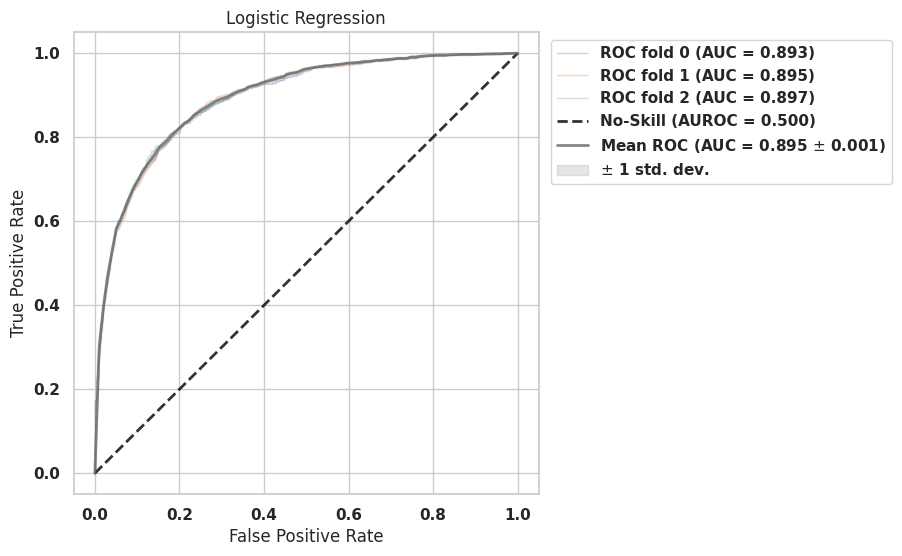

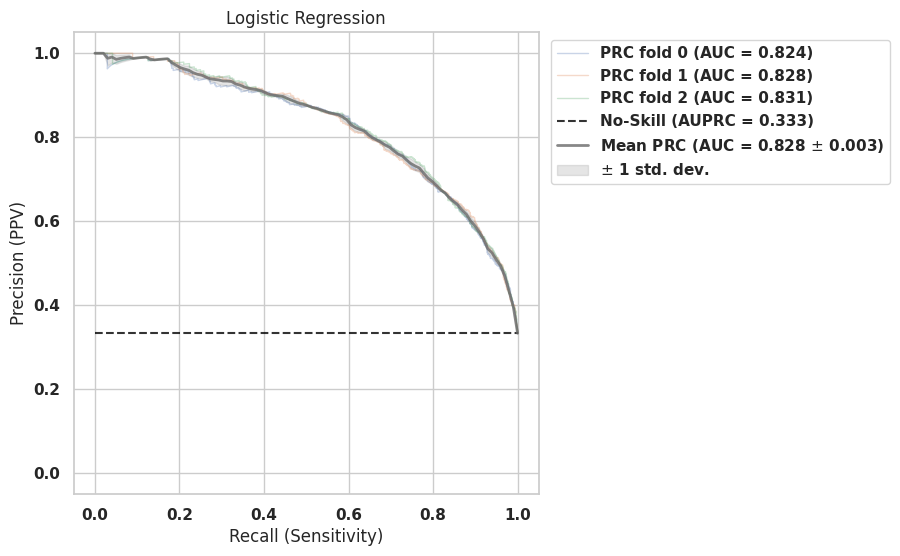

INFO: Running stats on Naive Bayes


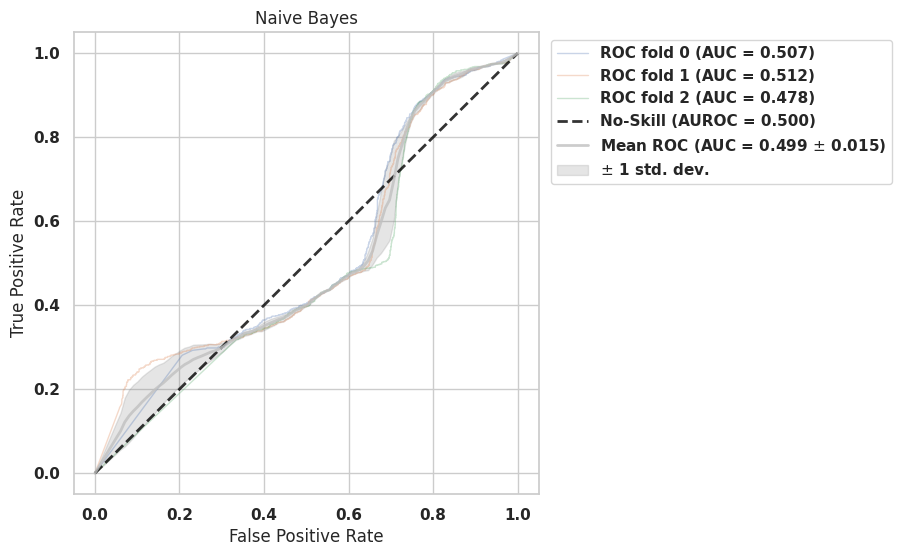

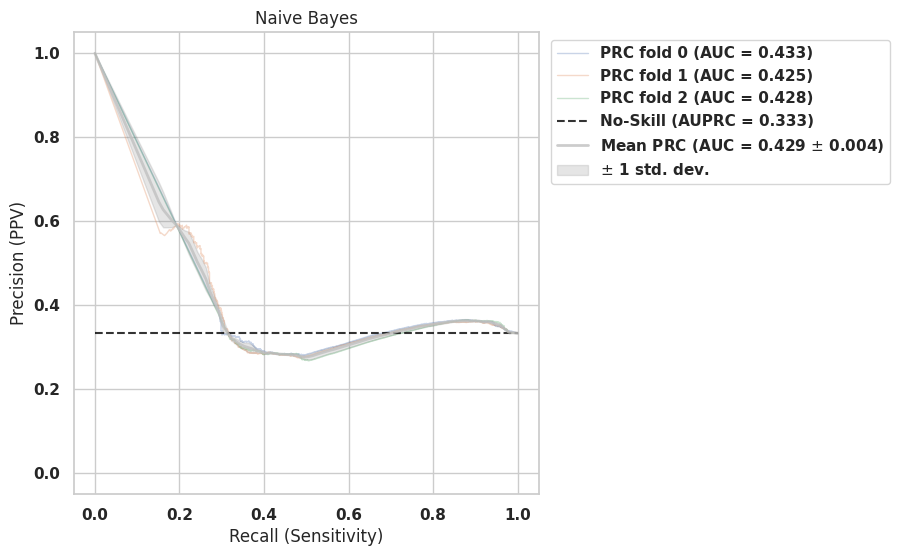

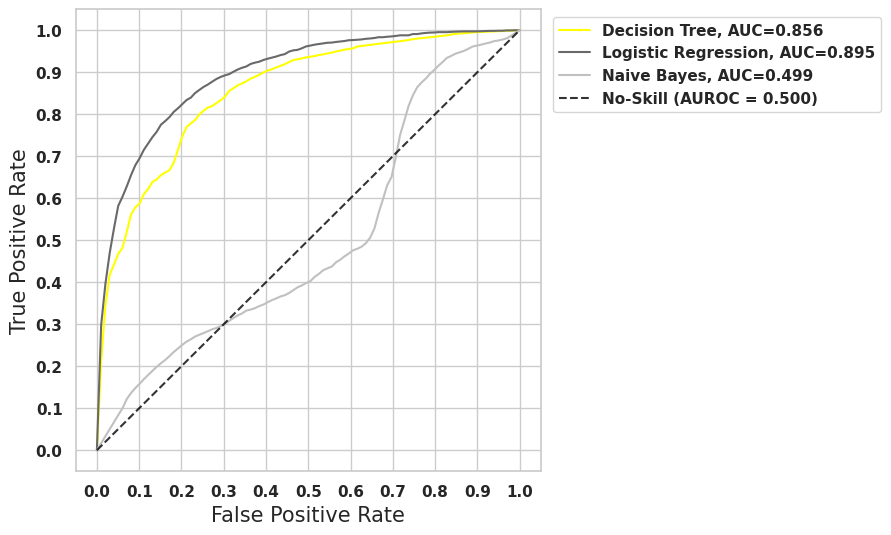

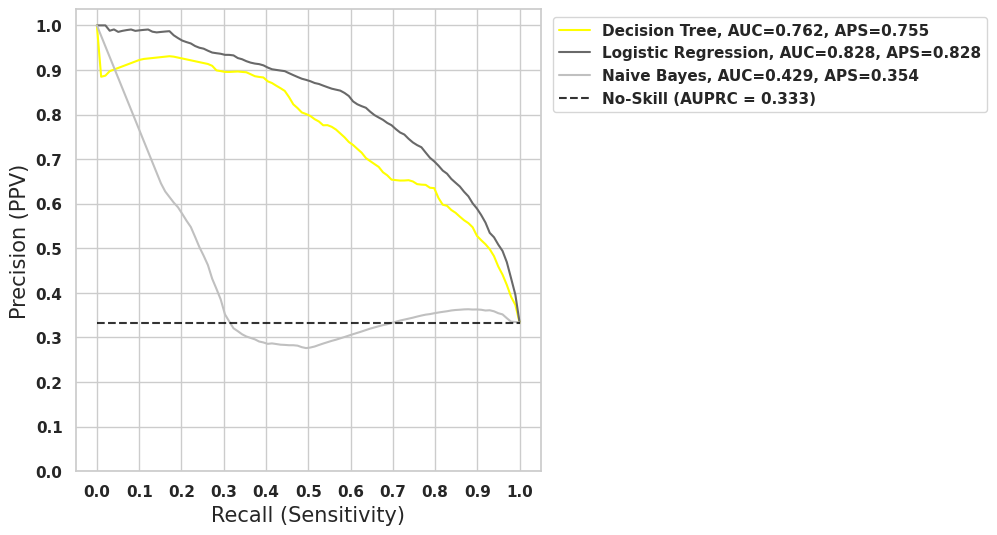

INFO: Saving Metric Summaries...
INFO: Generating Metric Boxplots...


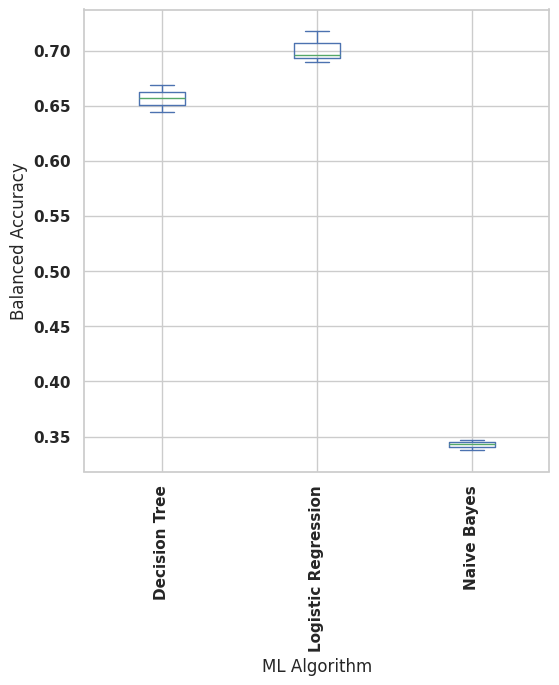

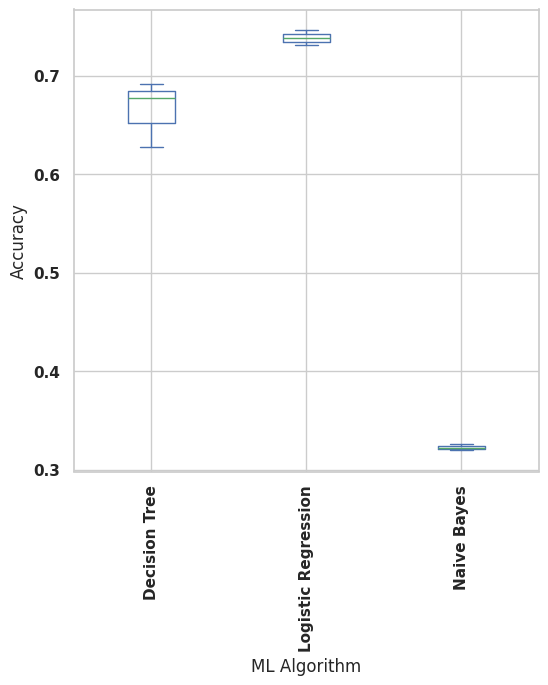

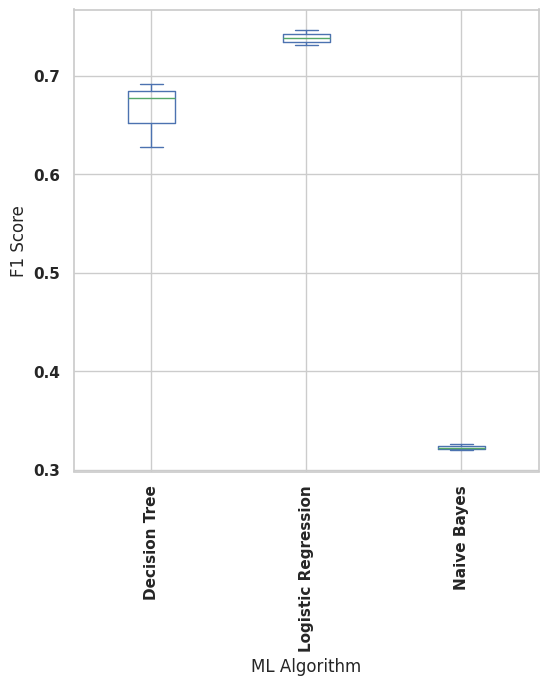

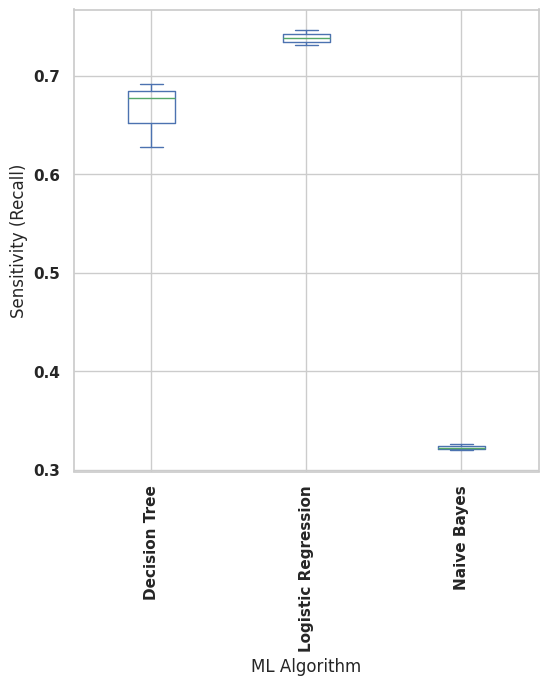

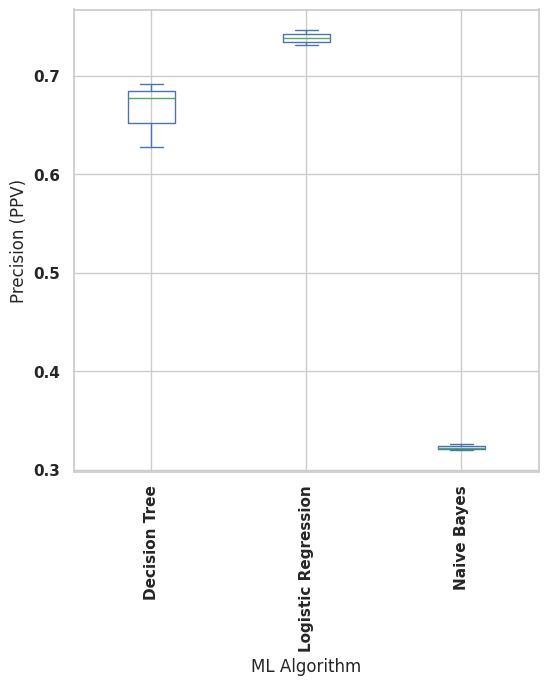

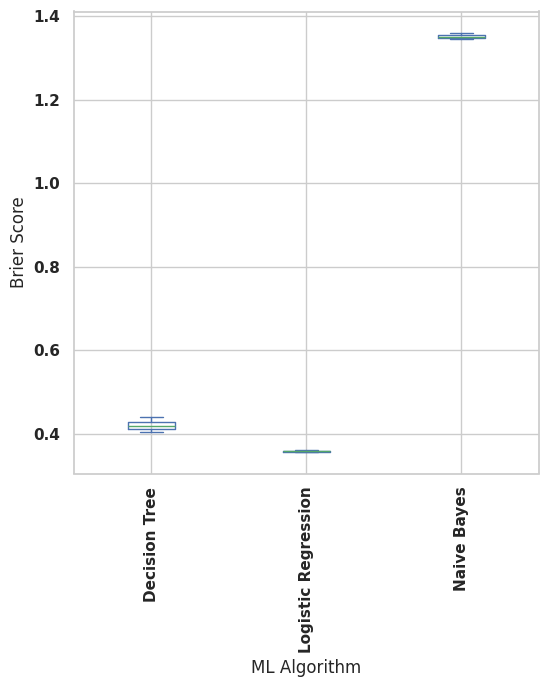

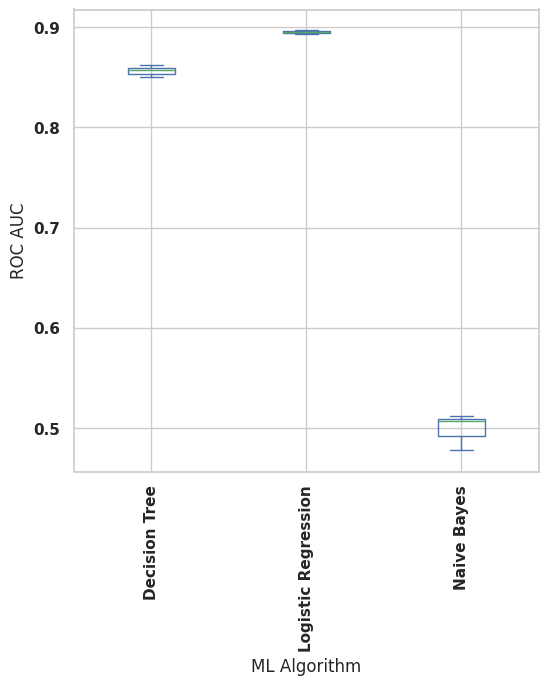

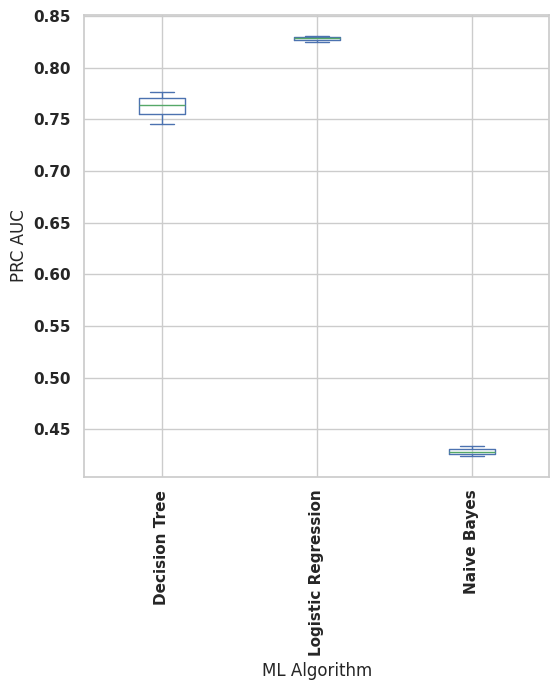

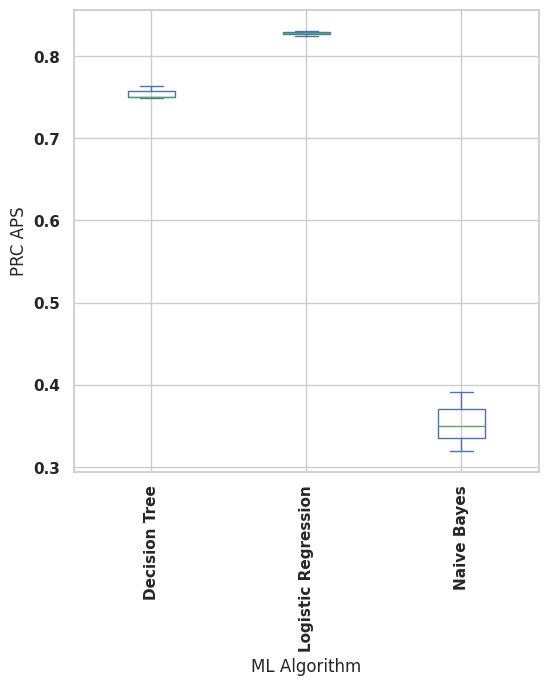

INFO: Running Non-Parametric Statistical Significance Analysis...
INFO: Preparing for Model Feature Importance Plotting...
INFO: Generating Feature Importance Boxplot and Histograms...


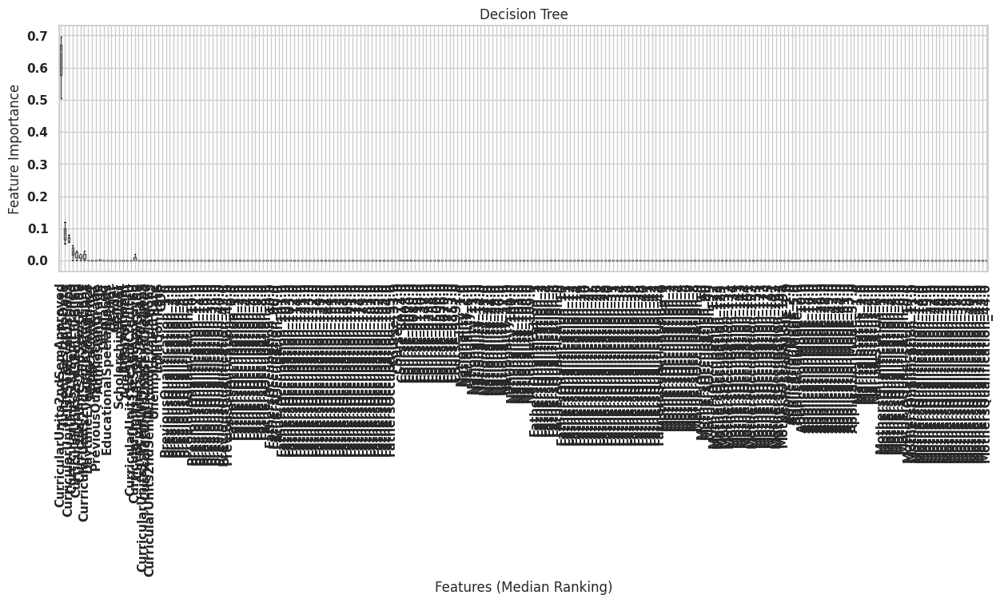

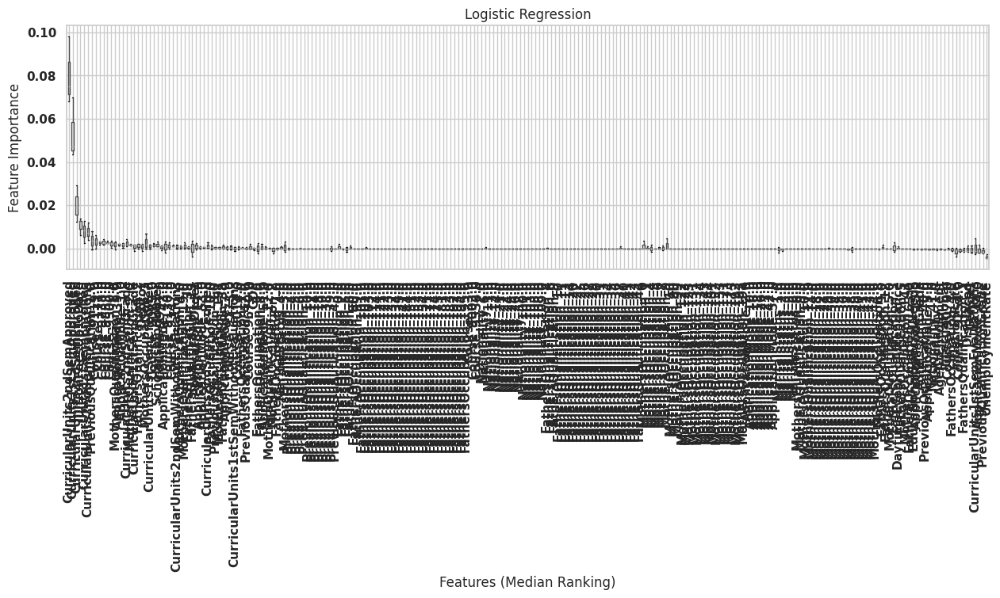

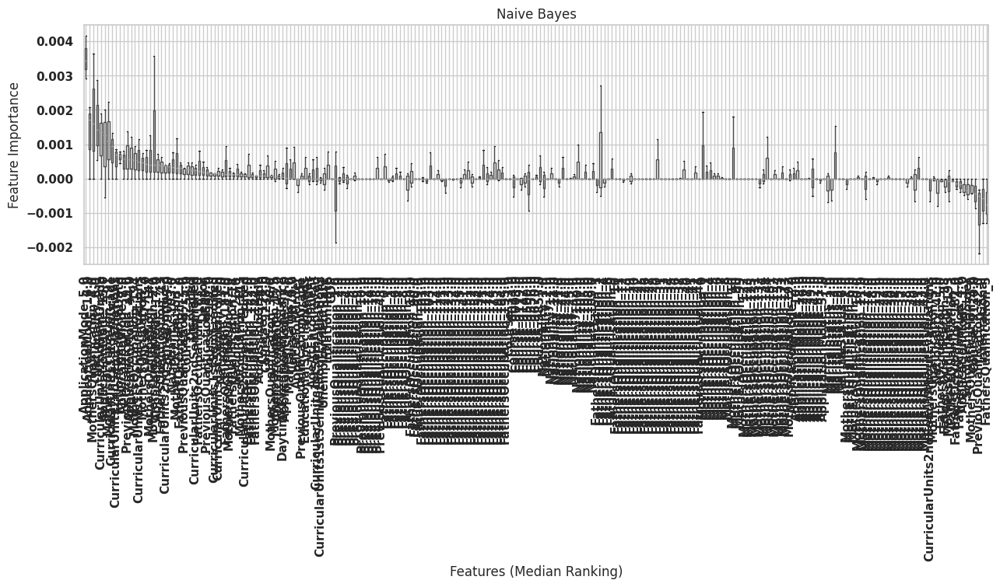

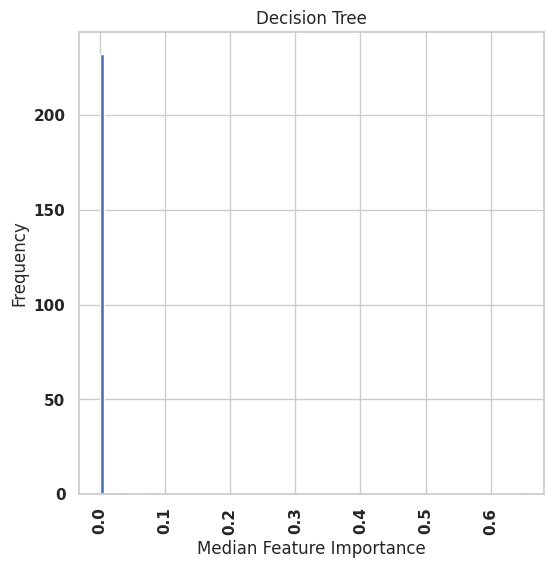

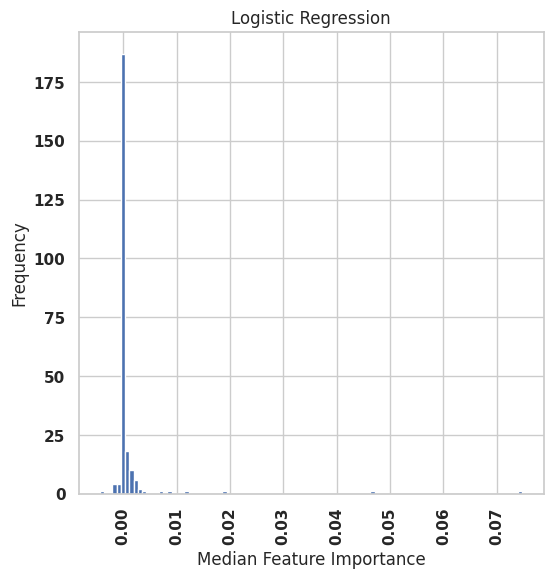

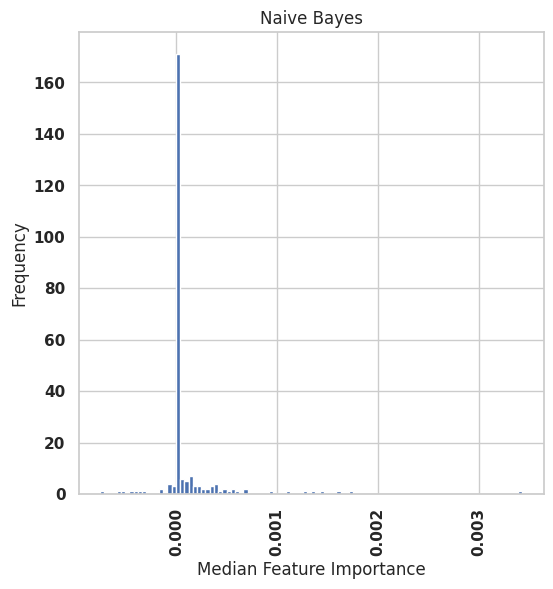

INFO: Generating Composite Feature Importance Plots...


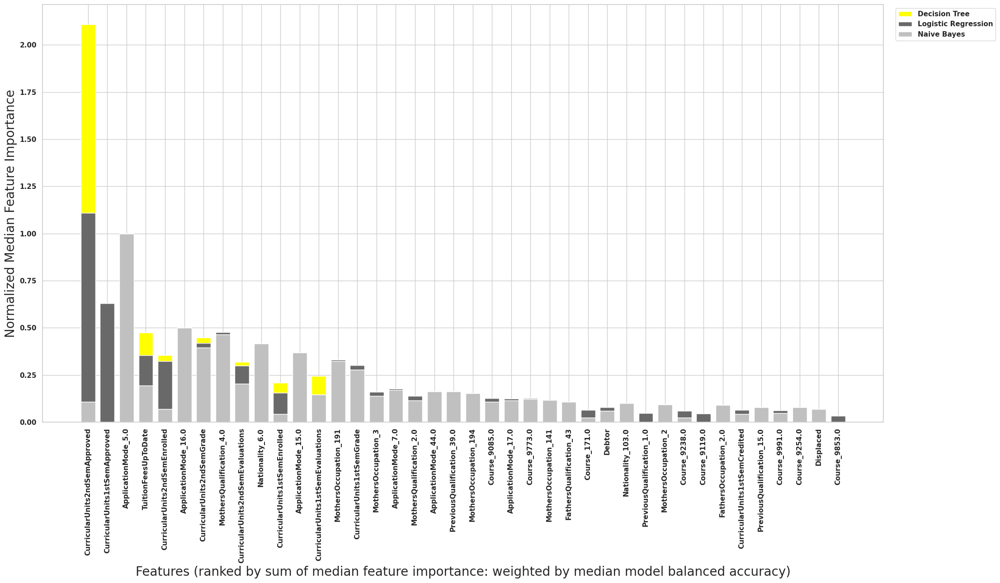

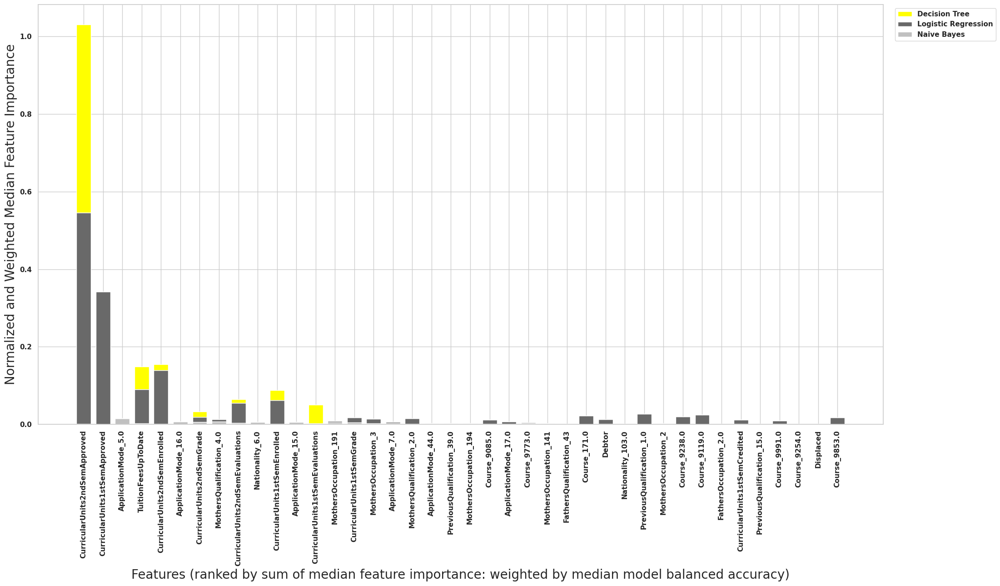

INFO: Collecting ensemble statistics from /content/streamline_output/ColabRun/student_dropout_academic_success/replication/student_dropout_academic_success_rep/ensemble_evaluation
INFO: student_dropout_academic_success_rep statistics phase complete
INFO: Replication complete for student_dropout_academic_success_rep


INFO: Completed Phase 10 - Replication


In [35]:
if RUN_PHASES["p10"]:
    print("INFO: Starting Phase 10 - Replication")
    rep_path = Path(P10_REP_DATA_PATH or CFG["rep_data_path"])
    data_for_rep = Path(P10_DATASET_FOR_REP or CFG["dataset_for_rep"])
    p10_match_label = P10_MATCH_LABEL if P10_MATCH_LABEL is not None else CFG["match_label"]
    if rep_path.exists() and data_for_rep.exists():
        P10Runner(
            rep_data_path=str(rep_path),
            dataset_for_rep=str(data_for_rep),
            output_path=CFG["output_path"],
            experiment_name=CFG["experiment_name"],
            outcome_label=P10_OUTCOME_LABEL,
            instance_label=P10_INSTANCE_LABEL,
            match_label=p10_match_label,
            exclude_plots=P10_EXCLUDE_PLOTS,
            run_cluster=RUN_CLUSTER,
            queue=PHASE_QUEUE,
            reserved_memory=PHASE_RESERVED_MEMORY_GB,
            show_plots=P10_SHOW_PLOTS,
        ).run()
        print("INFO: Completed Phase 10 - Replication")
    else:
        print("INFO: Phase 10 skipped - replication path or dataset_for_rep not found")
else:
    print("INFO: Phase 10 skipped")


## Phase 11: Reporting
After this cell runs, report artifacts are generated:

- standard testing-data report under `reporting/`
- replication report under `reporting_replication/` when Phase 10 was run

The reports summarize actual run settings, data-processing changes, feature engineering/selection, model performance, and replication results where available.


### تنفيذ المرحلة الحادية عشرة P11

- يخفّض مستوى رسائل السجل أثناء إعداد التقارير لتقليل الضوضاء.
- يحول `P11_REPORT_MODES` إلى قائمة أو مجموعة أوضاع.
- إذا كان التقرير القياسي مفعلًا، يستدعي `P11Runner` مع إعدادات التجربة ويطلب PDF والرسوم.
- إذا كان تقرير التكرار مطلوبًا ونتائجه متاحة، ينشئ التقرير الخاص بها أيضًا.
**الفائدة:** إخراج تقرير نهائي يشرح التجربة ونتائجها.

### شرح هذه الخلية: إنشاء التقارير في المرحلة P11
تخفّض مستوى رسائل السجل أثناء إعداد التقرير، ثم تحدد أنواع التقارير المطلوبة.
داخل `try` تشغّل `P11Runner` للتقرير القياسي أو تقرير التكرار حسب الخيارات، وتتعامل مع الأخطاء حتى تظهر للمستخدم.

In [36]:
# Keep phase logs verbose globally, but reduce report-phase noise.
_report_logger = logging.getLogger()
_prev_log_level = _report_logger.level
if RUN_PHASES["p11"] or RUN_PHASES["p11_replication"]:
    _report_logger.setLevel(logging.WARNING)

p11_report_modes = {m.strip().lower() for m in str(P11_REPORT_MODES).split(",") if m.strip()}

try:
    if RUN_PHASES["p11"] and "standard" in p11_report_modes:
        print("INFO: Starting Phase 11 - Reporting (standard)")
        P11Runner(
            output_path=CFG["output_path"],
            experiment_name=CFG["experiment_name"],
            experiment_path=str(EXP_ROOT),
            reporting_dir=P11_REPORTING_DIR,
            report_mode=P11_REPORT_MODE_STANDARD,
            outcome_label=P11_OUTCOME_LABEL or CFG["outcome_label"],
            outcome_type=P11_OUTCOME_TYPE or CFG["outcome_type"],
            instance_label=P11_INSTANCE_LABEL if P11_INSTANCE_LABEL is not None else CFG["instance_label"],
            make_pdf=P11_MAKE_PDF,
            enable_plots=P11_ENABLE_PLOTS,
            reuse_existing_figures=P11_REUSE_EXISTING_FIGURES,
            run_cluster=RUN_CLUSTER,
            queue=PHASE_QUEUE,
            reserved_memory=PHASE_RESERVED_MEMORY_GB,
        ).run()
        print("INFO: Completed Phase 11 - Reporting (standard)")
    else:
        print("INFO: Standard report skipped")

    if RUN_PHASES["p11_replication"] and "replication" in p11_report_modes:
        print("INFO: Starting Phase 11 - Reporting (replication)")
        P11Runner(
            output_path=CFG["output_path"],
            experiment_name=CFG["experiment_name"],
            experiment_path=str(EXP_ROOT),
            reporting_dir=P11_REPORTING_DIR,
            report_mode=P11_REPORT_MODE_REPLICATION,
            outcome_label=P11_OUTCOME_LABEL or CFG["outcome_label"],
            outcome_type=P11_OUTCOME_TYPE or CFG["outcome_type"],
            instance_label=P11_INSTANCE_LABEL if P11_INSTANCE_LABEL is not None else CFG["instance_label"],
            make_pdf=P11_MAKE_PDF,
            enable_plots=P11_ENABLE_PLOTS,
            reuse_existing_figures=P11_REUSE_EXISTING_FIGURES,
            run_cluster=RUN_CLUSTER,
            queue=PHASE_QUEUE,
            reserved_memory=PHASE_RESERVED_MEMORY_GB,
        ).run()
        print("INFO: Completed Phase 11 - Reporting (replication)")
    else:
        print("INFO: Replication report skipped")
finally:
    _report_logger.setLevel(_prev_log_level)

print("INFO: Pipeline run complete")


INFO: Starting Phase 11 - Reporting (standard)
INFO: Completed Phase 11 - Reporting (standard)
INFO: Starting Phase 11 - Reporting (replication)
INFO: Completed Phase 11 - Reporting (replication)
INFO: Pipeline run complete


## Output Summary
This final check prints the experiment folder and expected report paths before the download cells. If a report path says `exists=False`, verify that Phase 11 ran and that earlier phases completed successfully.


### التحقق من مسارات النتائج

- `exp_root`: مجلد التجربة النهائي.
- `std_pdf`: مسار تقرير الأداء القياسي.
- `rep_pdf`: مسار تقرير بيانات التكرار.
- `exists()`: يفحص هل الملف موجود بالفعل.
**الفائدة:** التأكد من نجاح إنشاء التقارير ومعرفة مكانها قبل تنزيلها.

### شرح هذه الخلية: التحقق من وجود ملفات PDF
تحدد مسار مجلد التجربة واسم التقرير القياسي وتقرير التكرار، ثم تطبع المسارات وهل الملفات موجودة.
هذه الخلية لا تنشئ التقرير؛ إنها تتأكد من أن مخرجات P11 موجودة.

In [37]:
exp_root = Path(CFG["output_path"]) / CFG["experiment_name"]
std_pdf = exp_root / "reporting" / f"{CFG['experiment_name']}_STREAMLINE_Report.pdf"
rep_pdf = exp_root / "reporting_replication" / f"{CFG['experiment_name']}_STREAMLINE_Replication_Report.pdf"

print(f"Experiment root: {exp_root}")
print(f"Standard report:   {std_pdf} (exists={std_pdf.exists()})")
print(f"Replication report:{rep_pdf} (exists={rep_pdf.exists()})")

Experiment root: /content/streamline_output/ColabRun
Standard report:   /content/streamline_output/ColabRun/reporting/ColabRun_STREAMLINE_Report.pdf (exists=True)
Replication report:/content/streamline_output/ColabRun/reporting_replication/ColabRun_STREAMLINE_Replication_Report.pdf (exists=True)


### Download and Open PDF Summary Report(s)

Run this cell in Colab to download the generated standard and replication reports when they exist.


### تنزيل تقارير PDF

- يستورد `files` من Google Colab لتنزيل الملفات، و`IFrame/display` لعرضها داخل Notebook عند الحاجة.
- يبني مساري التقرير القياسي والتكرار.
- إذا كان التقرير موجودًا (`exists()`)، ينفذ `files.download` لتنزيله؛ وإذا لم يوجد يطبع رسالة توضيحية.
**الفائدة:** نقل التقرير من بيئة Colab إلى جهازك.

### شرح هذه الخلية: عرض التقرير أو تنزيله
تستخدم أدوات Colab و`IFrame` لعرض PDF داخل Notebook، ثم تتحقق من وجود الملف وتتيح تنزيله للمستخدم.
إذا لم يظهر التقرير، راجع أولًا تنفيذ مرحلة P11 ومسار التقرير.

In [38]:
from google.colab import files
from IPython.display import IFrame, display
from pathlib import Path

# Define paths based on previous CFG and EXP_ROOT
exp_root = Path(CFG['output_path']) / CFG['experiment_name']
std_pdf = exp_root / "reporting" / f"{CFG['experiment_name']}_STREAMLINE_Report.pdf"
rep_pdf = exp_root / "reporting_replication" / f"{CFG['experiment_name']}_STREAMLINE_Replication_Report.pdf"

print(f"Checking for reports in: {exp_root}")

# Download Standard Report
if std_pdf.exists():
    print("Downloading Standard Report...")
    files.download(str(std_pdf))
else:
    print("Standard STREAMLINE report PDF not found.")

# Download Replication Report
if rep_pdf.exists():
    print("Downloading Replication Report...")
    files.download(str(rep_pdf))
else:
    print("Replication STREAMLINE report PDF not found (this is normal if replication mode wasn't run).")

Checking for reports in: /content/streamline_output/ColabRun


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Zip the experiment folder and download.

### ضغط مجلد التجربة وتنزيله

- `shutil.make_archive(..., 'zip', exp_root)` يضغط محتويات مجلد التجربة إلى ZIP.
- إذا كان مجلد التجربة موجودًا، ينشئ الملف ثم ينزله باستخدام `files.download`.
- إذا لم يوجد المجلد، يطبع رسالة خطأ مفهومة.
**الفائدة:** حفظ كل ملفات النتائج والنماذج والرسوم والتقارير في أرشيف واحد.

### شرح هذه الخلية: ضغط نتائج التجربة وتنزيلها
- تحدد مجلد نتائج التجربة.
- `shutil.make_archive`: تضغط المجلد إلى ملف ZIP.
- `files.download`: تبدأ تنزيل الملف المضغوط من Colab.
- بذلك يحصل المستخدم على النتائج والتقارير والملفات الناتجة في حزمة واحدة.

In [39]:
import shutil
from google.colab import files
from pathlib import Path

# Define the folder to zip and the output name
exp_root = Path(CFG['output_path']) / CFG['experiment_name']
zip_filename = f"{CFG['experiment_name']}_results"

if exp_root.exists():
    print(f"Zipping {exp_root}...")
    # Create a zip archive of the experiment directory
    shutil.make_archive(zip_filename, 'zip', exp_root)

    print(f"Downloading {zip_filename}.zip...")
    files.download(f"{zip_filename}.zip")
else:
    print(f"Experiment folder not found at: {exp_root}")

Zipping /content/streamline_output/ColabRun...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# التطوير الإضافي: PyTorch للتصنيف الجدولي والصوري (P12)

> **ملاحظة:** هذه إضافة تطويرية منفصلة عن مراحل STREAMLINE الأصلية P1–P11. لا تغيّر تشغيل STREAMLINE، ولا تدّعي أن النتائج نُفذت حتى تشغّل الخلايا على بياناتك.

## ماذا تضيف؟
- مسار **CSV**: شبكة MLP للبيانات الجدولية.
- مسار **الصور**: شبكة CNN باستخدام `ImageFolder`.
- تقسيم Train/Validation/Test، تثبيت Seed، تدريب، تقييم، Confusion Matrix، وحفظ Checkpoint.
- التنفيذ على Colab مع GPU عند توفره.

**تنظيم ملفات الصور المطلوب:** مجلد `images/` بداخله مجلد لكل فئة، مثل `images/cat/` و`images/dog/`، وتوضع الصور داخل مجلد الفئة.

## P12-A: إعداد PyTorch وقابلية التكرار

In [40]:
# تثبيت مكتبات التقييم (PyTorch غالبًا متوفر في Colab)
!pip -q install scikit-learn matplotlib

import os, random, json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("الجهاز:", DEVICE)
print("PyTorch:", torch.__version__)


الجهاز: cuda
PyTorch: 2.14.1+cu130


**شرح الخلية:** تثبت المكتبات المطلوبة، وتحدد Seed لتقليل اختلاف النتائج عند إعادة التجربة، ثم تختار GPU تلقائيًا إن توفر. هذا يساعد على reproducibility لكنه لا يضمن تطابقًا مطلقًا في كل عمليات GPU.

## P12-B: مسار البيانات الجدولية CSV باستخدام MLP

**قبل التشغيل:** ارفع ملف CSV وحدد اسم عمود الهدف. يجب أن يكون الهدف تصنيفيًا (فئات)، لا قيمة مستمرة. ستتم معالجة القيم المفقودة وترميز الأعمدة الفئوية، ثم تقسيم Train/Validation/Test.

In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay

# Updated path to point to the STREAMLINE multiclass demo dataset
CSV_PATH = "/content/STREAMLINE/data/UCIMulticlassClassification/student_dropout_academic_success.csv"
TARGET = "Class"                 # عإبارة عن عموؤ الهؤف

df = pd.read_csv(CSV_PATH)
print("شكل البىاناإء:", df.shape)
display(df.head())
print("\nالقىم المفقوؤة:\n", df.isna().sum())
print("الصفوف المكررة:", df.duplicated().sum())

df = df.drop_duplicates().dropna(subset=[TARGET]).copy()
X = df.drop(columns=[TARGET])
y_raw = df[TARGET].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = list(label_encoder.classes_)
print("الفئاإء:", class_names)

# آقسىم طبقى: 70% إؤرىب؁ 15% إإأقق؁ 15% اإإبار
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

# fit على الإؤرىب فقط لإبآنب Data Leakage
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

# إأؤىل Sparse إلى Dense عنب الةابة
X_train_p = X_train_p.toarray() if hasattr(X_train_p, "toarray") else X_train_p
X_val_p = X_val_p.toarray() if hasattr(X_val_p, "toarray") else X_val_p
X_test_p = X_test_p.toarray() if hasattr(X_test_p, "toarray") else X_test_p

def to_tensor_dataset(Xa, ya):
    return TensorDataset(
        torch.tensor(np.asarray(Xa), dtype=torch.float32),
        torch.tensor(np.asarray(ya), dtype=torch.long)
    )

train_loader = DataLoader(to_tensor_dataset(X_train_p, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(to_tensor_dataset(X_val_p, y_val), batch_size=256)
test_loader = DataLoader(to_tensor_dataset(X_test_p, y_test), batch_size=256)

print("أبعاإ Tensor:", X_train_p.shape, "عإإ الفئاإء:", len(class_names))

شكل البىاناإء: (3539, 38)


,InstanceID,MaritalStatus,ApplicationMode,Course,DaytimeEveningAttendance,ApplicationOrder,PreviousQualification,Nationality,MothersQualification,FathersQualification,...,CurricularUnits2ndSemCredited,CurricularUnits2ndSemEnrolled,CurricularUnits2ndSemEvaluations,CurricularUnits2ndSemApproved,CurricularUnits2ndSemGrade,CurricularUnits2ndSemWithoutEvaluations,UnemploymentRate,InflationRate,GDP,Class
0,Student_00001,1.0,17.0,171.0,1,5,1.0,1.0,19.0,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,0
1,Student_00002,1.0,15.0,9254.0,1,1,1.0,1.0,1.0,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,2
2,Student_00003,1.0,1.0,9070.0,1,5,1.0,1.0,37.0,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,0
3,Student_00004,1.0,17.0,9773.0,1,2,1.0,1.0,38.0,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,2
4,Student_00005,2.0,39.0,NaN,0,1,1.0,1.0,37.0,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,2



القىم المفقوؤة:
 InstanceID                                  0
MaritalStatus                              32
ApplicationMode                            32
Course                                     37
DaytimeEveningAttendance                    0
ApplicationOrder                            0
PreviousQualification                      38
Nationality                                42
MothersQualification                       33
FathersQualification                        0
MothersOccupation                           0
FathersOccupation                          38
PreviousQualificationGrade                 34
AdmissionGrade                             33
Displaced                                   0
EducationalSpecialNeeds                     0
Debtor                                      0
TuitionFeesUpToDate                        37
Gender                                     38
ScholarshipHolder                           0
International                               0
AgeAtEnrollment 

**شرح الخلية:** نفحص البيانات أولًا، ثم نحذف التكرار ونجهز الهدف. نقسم البيانات مع الحفاظ على نسب الفئات. `fit_transform` للمعالجة يتم على التدريب فقط، بينما Validation وTest يأخذان `transform` فقط. في النهاية نطبع أبعاد الخصائص وعدد الفئات.

### بناء MLP وإجراءات التدريب

In [42]:

import torch
import torch.nn as nn
import numpy as np

from sklearn.metrics import accuracy_score
from torch.utils.data import TensorDataset, DataLoader


class TabularMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model = TabularMLP(X_train_p.shape[1], len(class_names)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 30
best_val_loss = float("inf")
patience, wait = 5, 0
history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

for epoch in range(EPOCHS):
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses, val_true, val_pred = [], [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            val_losses.append(criterion(logits, yb).item())
            val_pred.extend(logits.argmax(1).cpu().numpy())
            val_true.extend(yb.cpu().numpy())

    tr_loss = float(np.mean(train_losses))
    va_loss = float(np.mean(val_losses))
    va_acc = accuracy_score(val_true, val_pred)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["val_accuracy"].append(va_acc)
    print(f"Epoch {epoch+1:02d}: train_loss={tr_loss:.4f} val_loss={va_loss:.4f} val_acc={va_acc:.4f}")

    if va_loss < best_val_loss:
        best_val_loss, wait = va_loss, 0
        torch.save(model.state_dict(), "/content/best_mlp.pth")
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping")
            break

model.load_state_dict(torch.load("/content/best_mlp.pth", map_location=DEVICE))


Epoch 01: train_loss=0.9221 val_loss=0.8626 val_acc=0.7062
Epoch 02: train_loss=0.6461 val_loss=0.7351 val_acc=0.7382
Epoch 03: train_loss=0.5648 val_loss=0.6816 val_acc=0.7420
Epoch 04: train_loss=0.5162 val_loss=0.6800 val_acc=0.7589
Epoch 05: train_loss=0.4558 val_loss=0.6726 val_acc=0.7589
Epoch 06: train_loss=0.3997 val_loss=0.6439 val_acc=0.7552
Epoch 07: train_loss=0.3318 val_loss=0.6437 val_acc=0.7646
Epoch 08: train_loss=0.2657 val_loss=0.7033 val_acc=0.7533
Epoch 09: train_loss=0.1969 val_loss=0.7024 val_acc=0.7552
Epoch 10: train_loss=0.1416 val_loss=0.7331 val_acc=0.7514
Epoch 11: train_loss=0.0995 val_loss=0.7555 val_acc=0.7363
Epoch 12: train_loss=0.0703 val_loss=0.7248 val_acc=0.7439
Early stopping


<All keys matched successfully>

**شرح الخلية:** بنينا MLP بثلاث طبقات خطية مع ReLU وDropout. التدريب يستخدم CrossEntropyLoss وAdam. نراقب Validation Loss ونحفظ أفضل أوزان، ونوقف مبكرًا إذا لم يتحسن الأداء (Early Stopping).

### تقييم MLP على Test وحفظ النتائج

In [43]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(DEVICE))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(yb.numpy())

print("Test Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, xticks_rotation=45)
plt.title("MLP - Test Confusion Matrix")
plt.tight_layout()
plt.show()

torch.save({
    "model_state": model.state_dict(),
    "input_dim": X_train_p.shape[1],
    "class_names": class_names,
    "seed": SEED
}, "/content/mlp_checkpoint.pth")
print("حُفظ النموذج في /content/mlp_checkpoint.pth")


Test Accuracy: 0.7589453860640302
Macro F1: 0.6987785116225483
              precision    recall  f1-score   support

           0       0.83      0.76      0.80       171
           1       0.48      0.45      0.46        95
           2       0.81      0.87      0.84       265

    accuracy                           0.76       531
   macro avg       0.71      0.69      0.70       531
weighted avg       0.76      0.76      0.76       531

حُفظ النموذج في /content/mlp_checkpoint.pth


**شرح الخلية:** التقييم النهائي يتم على Test الذي لم يستخدم في التدريب أو اختيار أفضل Epoch. نعرض Accuracy وMacro-F1 وتقرير التصنيف وConfusion Matrix، ثم نحفظ أوزان النموذج ومعلومات الفئات.

## P12-C: CNN على صور CIFAR-10
تُحمّل الصور تلقائياً؛ لا تحتاج إلى إنشاء مجلد `/content/images`. نحافظ على مجموعة الاختبار الرسمية مستقلة، ونقسم صور التدريب فقط إلى تدريب وتحقق.


In [44]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader

# ======================================
# 1. إعداد المتغيرات
# ======================================

SEED = 42
IMAGE_DIR = "/content/data"
IMG_SIZE = 32
BATCH_SIZE = 32

torch.manual_seed(SEED)

# ======================================
# 2. معالجة الصور
# ======================================

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# ======================================
# 3. تحميل CIFAR-10 تلقائياً
# ======================================

train_data = datasets.CIFAR10(
    root=IMAGE_DIR,
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    root=IMAGE_DIR,
    train=False,
    download=True,
    transform=transform
)

# إبقاء مجموعة الاختبار الرسمية مستقلة لمنع تسرب البيانات
class_names_img = train_data.classes
n = len(train_data)
n_train = int(0.85 * n)
n_val = n - n_train
generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = torch.utils.data.random_split(
    train_data, [n_train, n_val], generator=generator
)
test_ds = test_data

# ======================================
# 5. إنشاء DataLoaders
# ======================================

train_img_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_img_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_img_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ======================================
# 6. اختبار تحميل الصور
# ======================================

images, labels = next(iter(train_img_loader))

print("Tensor الصور:", images.shape)
print("الفئات:", class_names_img)

print("عدد الصور الكلي:", n)
print("صور التدريب:", len(train_ds))
print("صور التحقق:", len(val_ds))
print("صور الاختبار:", len(test_ds))

print("تم تحميل CIFAR-10 بنجاح!")


100%|██████████| 170M/170M [03:13<00:00, 880kB/s]


Tensor الصور: torch.Size([32, 3, 32, 32])
الفئات: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
عدد الصور الكلي: 50000
صور التدريب: 42500
صور التحقق: 7500
صور الاختبار: 10000
تم تحميل CIFAR-10 بنجاح!


In [45]:
# معاينة صور P12 فور التحميل، قبل تدريب CNN
import matplotlib.pyplot as plt
xb, yb = next(iter(train_img_loader))
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for i, ax in enumerate(axes.flat):
    img = (xb[i] * 0.5 + 0.5).clamp(0, 1)  # عكس Normalize للعرض
    ax.imshow(img.permute(1, 2, 0).cpu())
    ax.set_title(class_names_img[int(yb[i])])
    ax.axis('off')
plt.suptitle('P12: CIFAR-10 training samples')
plt.tight_layout(); plt.show()


**شرح الخلية:** `datasets.CIFAR10` ينزّل الصور تلقائياً إلى `/content/data`؛ ويعيد Tensor لكل صورة. التقسيم 42,500 تدريب و7,500 تحقق و10,000 اختبار.


### بناء CNN وتدريبها

In [46]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*(IMG_SIZE//8)*(IMG_SIZE//8), 128),
            nn.ReLU(), nn.Dropout(0.30),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN(len(class_names_img)).to(DEVICE)
cnn_optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
cnn_criterion = nn.CrossEntropyLoss()
CNN_EPOCHS = 15
best_cnn_val = float("inf")
cnn_history = {"train_loss": [], "val_loss": []}

for epoch in range(CNN_EPOCHS):
    cnn.train()
    train_loss_list = []
    for xb, yb in train_img_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        cnn_optimizer.zero_grad()
        logits = cnn(xb)
        loss = cnn_criterion(logits, yb)
        loss.backward()
        cnn_optimizer.step()
        train_loss_list.append(loss.item())

    cnn.eval()
    val_loss_list = []
    with torch.no_grad():
        for xb, yb in val_img_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            val_loss_list.append(cnn_criterion(cnn(xb), yb).item())

    tr = float(np.mean(train_loss_list))
    va = float(np.mean(val_loss_list)) if val_loss_list else float("nan")
    cnn_history["train_loss"].append(tr)
    cnn_history["val_loss"].append(va)
    print(f"Epoch {epoch+1:02d}: train_loss={tr:.4f} val_loss={va:.4f}")

    if va < best_cnn_val:
        best_cnn_val = va
        torch.save(cnn.state_dict(), "/content/best_cnn.pth")

cnn.load_state_dict(torch.load("/content/best_cnn.pth", map_location=DEVICE))


Epoch 01: train_loss=1.5016 val_loss=1.1742
Epoch 02: train_loss=1.1239 val_loss=0.9694
Epoch 03: train_loss=0.9608 val_loss=0.9386
Epoch 04: train_loss=0.8439 val_loss=0.8113
Epoch 05: train_loss=0.7550 val_loss=0.7811
Epoch 06: train_loss=0.6897 val_loss=0.7709
Epoch 07: train_loss=0.6213 val_loss=0.7541
Epoch 08: train_loss=0.5713 val_loss=0.7282
Epoch 09: train_loss=0.5275 val_loss=0.7686
Epoch 10: train_loss=0.4786 val_loss=0.7782
Epoch 11: train_loss=0.4407 val_loss=0.8242
Epoch 12: train_loss=0.4154 val_loss=0.8837
Epoch 13: train_loss=0.3865 val_loss=0.8937
Epoch 14: train_loss=0.3616 val_loss=0.9301
Epoch 15: train_loss=0.3341 val_loss=0.9419


<All keys matched successfully>

**شرح الخلية:** CNN تتكون من Convolution لاستخراج الأنماط، ReLU لإضافة اللاخطية، وMaxPooling لتقليل الأبعاد. بعد ذلك Flatten ثم طبقات Fully Connected لإنتاج درجات الفئات. في كل Batch ننفذ Forward وLoss وBackpropagation وOptimizer Step.

### تقييم CNN وحفظها

In [47]:
cnn.eval()
img_true, img_pred = [], []
with torch.no_grad():
    for xb, yb in test_img_loader:
        logits = cnn(xb.to(DEVICE))
        img_pred.extend(logits.argmax(1).cpu().numpy())
        img_true.extend(yb.numpy())

print("CNN Test Accuracy:", accuracy_score(img_true, img_pred))
print("CNN Macro F1:", f1_score(img_true, img_pred, average="macro"))
print(classification_report(img_true, img_pred, target_names=class_names_img, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    img_true, img_pred, display_labels=class_names_img, xticks_rotation=45
)
plt.title("CNN - Test Confusion Matrix")
plt.tight_layout()
plt.show()

torch.save({
    "model_state": cnn.state_dict(),
    "classes": class_names_img,
    "img_size": IMG_SIZE,
    "seed": SEED
}, "/content/cnn_checkpoint.pth")
print("حُفظ النموذج في /content/cnn_checkpoint.pth")


CNN Test Accuracy: 0.7441
CNN Macro F1: 0.7432753156200131
              precision    recall  f1-score   support

    airplane       0.79      0.76      0.78      1000
  automobile       0.87      0.85      0.86      1000
        bird       0.62      0.70      0.66      1000
         cat       0.55      0.50      0.52      1000
        deer       0.71      0.71      0.71      1000
         dog       0.67      0.63      0.65      1000
        frog       0.81      0.80      0.81      1000
       horse       0.77      0.81      0.79      1000
        ship       0.82      0.87      0.84      1000
       truck       0.83      0.81      0.82      1000

    accuracy                           0.74     10000
   macro avg       0.74      0.74      0.74     10000
weighted avg       0.74      0.74      0.74     10000

حُفظ النموذج في /content/cnn_checkpoint.pth


**شرح الخلية:** نستخدم Test مرة واحدة للتقييم النهائي ونحسب Accuracy وMacro-F1 ونطبع تقريرًا ومصفوفة الالتباس، ثم نحفظ وزن CNN مع أسماء الفئات وحجم الصور.

## كيف تعرض التطوير للدكتور؟

> أضفنا إلى STREAMLINE وحدة مستقلة للتعلم العميق باستخدام PyTorch. للبيانات الجدولية استخدمنا MLP، وللصور استخدمنا CNN. فصلنا البيانات إلى Train وValidation وTest، وضبطنا Seed، وراقبنا Loss أثناء التدريب، واستخدمنا Early Stopping وحفظ أفضل Checkpoint. ثم قيّمنا النموذج على Test باستخدام Accuracy وMacro-F1 وClassification Report وConfusion Matrix. هذه إضافة تجريبية قابلة للتشغيل، ويجب إدخال بيانات مناسبة وتشغيل الخلايا قبل ذكر أي نتائج رقمية.

**تنبيهات علمية:**
- لا تستخدم Test لاختيار المعاملات أو النموذج الأفضل.
- عند قلة الصور أو عدم توازن الفئات، استخدم تقسيمًا طبقيًا وراجع عدد الصور في كل فئة.
- التطبيع والتحويلات تُختار حسب طبيعة البيانات.
- نتائج هذا الجزء ليست نتائج STREAMLINE الأصلية، بل نتائج الوحدة الإضافية P12.


# P13 — تجربة CNN على Dataset CIFAR-10
هذا القسم يضيف تجربة مستقلة لتصنيف الصور باستخدام CIFAR-10 إلى جانب أقسام STREAMLINE وMLP/CNN السابقة.
**شغّل خلايا P13 بالترتيب.** لا يعتمد هذا القسم على ملفات CSV أو ImageFolder في P12.

## 1. استيراد المكتبات وتحديد الجهاز

In [48]:
import random, numpy as np, matplotlib.pyplot as plt, copy, time, os
import torch, torch.nn as nn, torch.optim as optim, torchvision, torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split, Subset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch:", torch.__version__)

Device: cuda | PyTorch: 2.14.1+cu130


## 2. تحميل CIFAR-10 وتقسيم التدريب والتحقق والاختبار
50 ألف صورة تدريب؛ سنخصص 45 ألف للتدريب و5 آلاف للتحقق، و10 آلاف للاختبار النهائي.

In [49]:
DATA_DIR="./data"; BATCH_SIZE=128; NUM_WORKERS=2
to_tensor=transforms.ToTensor()
full_train=torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=to_tensor)
test_dataset=torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=to_tensor)
train_subset,val_subset=random_split(full_train,[45000,5000],generator=torch.Generator().manual_seed(SEED))
train_loader=DataLoader(train_subset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
val_loader=DataLoader(val_subset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
classes=full_train.classes
print(classes, len(train_subset),len(val_subset),len(test_dataset))

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'] 45000 5000 10000


## 3. عرض الصور وأبعاد Tensor
صورة واحدة: `(3,32,32)` أي RGB وارتفاع وعرض. Batch من 128 صورة: `(128,3,32,32)`.

In [50]:
x_batch,y_batch=next(iter(train_loader))
print("Batch:",x_batch.shape,"Labels:",y_batch.shape)
plt.figure(figsize=(12,6))
for i in range(12):
    plt.subplot(3,4,i+1); plt.imshow(x_batch[i].permute(1,2,0)); plt.title(classes[y_batch[i]]); plt.axis("off")
plt.tight_layout(); plt.show()

Batch: torch.Size([128, 3, 32, 32]) Labels: torch.Size([128])


## 4. بناء CNN الأساسية Baseline
طبقات Conv وReLU وMaxPool، ثم Flatten وطبقات Dense لإخراج 10 فئات.

In [51]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.ReLU())
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128*8*8,256),nn.ReLU(),
                                      nn.Dropout(.3),nn.Linear(256,10))
    def forward(self,x): return self.classifier(self.features(x))
baseline=BaselineCNN().to(device)
print(baseline)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


## 5. دوال التدريب والتقييم
في التدريب: `zero_grad → forward → loss → backward → optimizer.step`. التقييم لا يحدث تحديثاً للأوزان.

In [52]:
criterion=nn.CrossEntropyLoss()
def run_epoch(model,loader,optimizer=None):
    training=optimizer is not None
    model.train() if training else model.eval()
    loss_sum=correct=total=0
    for x,y in loader:
        x=x.to(device); y=y.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits=model(x); loss=criterion(logits,y)
            if training: loss.backward(); optimizer.step()
        loss_sum+=loss.item()*y.size(0); correct+=(logits.argmax(1)==y).sum().item(); total+=y.size(0)
    return loss_sum/total,correct/total

def fit(model,train_dl,val_dl,epochs=10,lr=1e-3,patience=4):
    opt=optim.Adam(model.parameters(),lr=lr)
    hist={k:[] for k in ["train_loss","train_acc","val_loss","val_acc"]}
    best=float("inf"); best_state=None; wait=0
    for ep in range(epochs):
        tl,ta=run_epoch(model,train_dl,opt); vl,va=run_epoch(model,val_dl)
        for k,v in zip(hist,[tl,ta,vl,va]): hist[k].append(v)
        print(f"Epoch {ep+1}/{epochs}: train loss={tl:.4f} acc={ta:.4f} | val loss={vl:.4f} acc={va:.4f}")
        if vl<best: best=vl; best_state=copy.deepcopy(model.state_dict()); wait=0
        else:
            wait+=1
            if wait>=patience: print("Early stopping"); break
    if best_state: model.load_state_dict(best_state)
    return hist

## 6. تدريب النموذج الأساسي

In [53]:
start=time.time()
baseline_hist=fit(baseline,train_loader,val_loader,epochs=10,patience=4)
print("Minutes:",round((time.time()-start)/60,2))

Epoch 1/10: train loss=1.5794 acc=0.4242 | val loss=1.2855 acc=0.5442
Epoch 2/10: train loss=1.2116 acc=0.5641 | val loss=1.0600 acc=0.6284
Epoch 3/10: train loss=1.0255 acc=0.6375 | val loss=0.9881 acc=0.6502
Epoch 4/10: train loss=0.8885 acc=0.6862 | val loss=0.8657 acc=0.6986
Epoch 5/10: train loss=0.7848 acc=0.7234 | val loss=0.8333 acc=0.7022
Epoch 6/10: train loss=0.7104 acc=0.7489 | val loss=0.7974 acc=0.7192
Epoch 7/10: train loss=0.6228 acc=0.7812 | val loss=0.7457 acc=0.7404
Epoch 8/10: train loss=0.5571 acc=0.8054 | val loss=0.7470 acc=0.7498
Epoch 9/10: train loss=0.4793 acc=0.8286 | val loss=0.7663 acc=0.7478
Epoch 10/10: train loss=0.4159 acc=0.8531 | val loss=0.7705 acc=0.7496
Minutes: 1.28


## 7. رسم Loss وAccuracy للنموذج الأساسي
تقارب Train وValidation عادة مؤشر جيد؛ تباعدهما أو ارتفاع Validation Loss قد يشير إلى Overfitting.

In [54]:
def plot_hist(h,title):
    ep=range(1,len(h["train_loss"])+1)
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1); plt.plot(ep,h["train_loss"],label="Train"); plt.plot(ep,h["val_loss"],label="Validation")
    plt.title(title+" Loss"); plt.xlabel("Epoch"); plt.legend(); plt.grid(alpha=.3)
    plt.subplot(1,2,2); plt.plot(ep,h["train_acc"],label="Train"); plt.plot(ep,h["val_acc"],label="Validation")
    plt.title(title+" Accuracy"); plt.xlabel("Epoch"); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.show()
plot_hist(baseline_hist,"Baseline CNN")

## 8. Data Augmentation
نستخدم RandomCrop وRandomHorizontalFlip للتدريب فقط. التحقق والاختبار يظلان بصور أصلية.

In [55]:
aug_transform=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),transforms.ToTensor()])
aug_full=torchvision.datasets.CIFAR10(DATA_DIR,train=True,download=False,transform=aug_transform)
train_aug=Subset(aug_full,train_subset.indices)
plain_full=torchvision.datasets.CIFAR10(DATA_DIR,train=True,download=False,transform=transforms.ToTensor())
val_clean=Subset(plain_full,val_subset.indices)
train_aug_loader=DataLoader(train_aug,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS)
val_clean_loader=DataLoader(val_clean,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)

## 9. بناء CNN المحسنة
BatchNorm يساعد في استقرار التدريب، وDropout يقلل الاعتماد المفرط على وحدات معينة. أضفنا Pool ثالثة.

In [56]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,3,padding=1,bias=False),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1,bias=False),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1,bias=False),nn.BatchNorm2d(128),nn.ReLU(),
            nn.Conv2d(128,128,3,padding=1,bias=False),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128*4*4,256),nn.ReLU(),nn.Dropout(.4),nn.Linear(256,10))
    def forward(self,x): return self.classifier(self.features(x))
improved=ImprovedCNN().to(device)
print(improved)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_st

## 10. تدريب CNN المحسنة مع Early Stopping

In [57]:
start=time.time()
improved_hist=fit(improved,train_aug_loader,val_clean_loader,epochs=20,patience=5)
print("Minutes:",round((time.time()-start)/60,2))

Epoch 1/20: train loss=1.5028 acc=0.4485 | val loss=1.2001 acc=0.5572
Epoch 2/20: train loss=1.1443 acc=0.5894 | val loss=0.9779 acc=0.6490
Epoch 3/20: train loss=0.9962 acc=0.6487 | val loss=0.9025 acc=0.6818
Epoch 4/20: train loss=0.9048 acc=0.6832 | val loss=1.0186 acc=0.6418
Epoch 5/20: train loss=0.8331 acc=0.7092 | val loss=0.7787 acc=0.7242
Epoch 6/20: train loss=0.7823 acc=0.7283 | val loss=0.8542 acc=0.7034
Epoch 7/20: train loss=0.7420 acc=0.7444 | val loss=0.7902 acc=0.7218
Epoch 8/20: train loss=0.7104 acc=0.7569 | val loss=1.0460 acc=0.6622
Epoch 9/20: train loss=0.6820 acc=0.7670 | val loss=0.6715 acc=0.7634
Epoch 10/20: train loss=0.6543 acc=0.7749 | val loss=0.6618 acc=0.7772
Epoch 11/20: train loss=0.6182 acc=0.7873 | val loss=0.6434 acc=0.7668
Epoch 12/20: train loss=0.5937 acc=0.7973 | val loss=0.5575 acc=0.8082
Epoch 13/20: train loss=0.5773 acc=0.8045 | val loss=0.6419 acc=0.7826
Epoch 14/20: train loss=0.5515 acc=0.8108 | val loss=0.5792 acc=0.8082
Epoch 15/20: tr

## 11. مقارنة منحنيات النموذجين

In [58]:
plot_hist(improved_hist,"Improved CNN")
plt.figure(figsize=(8,4))
plt.plot(baseline_hist["val_acc"],label="Baseline Validation")
plt.plot(improved_hist["val_acc"],label="Improved Validation")
plt.xlabel("Epoch");plt.ylabel("Accuracy");plt.title("Validation Accuracy Comparison")
plt.legend();plt.grid(alpha=.3);plt.show()

## 12. التقييم النهائي على Test
نستخدم Test بعد انتهاء اختيار النموذج. يعرض هذا الجزء Accuracy وPrecision وRecall وF1 وConfusion Matrix.

In [59]:
def evaluate(model,loader,name):
    model.eval(); yt=[]; yp=[]
    with torch.no_grad():
        for x,y in loader:
            pred=model(x.to(device)).argmax(1).cpu().numpy()
            yp.extend(pred); yt.extend(y.numpy())
    acc=np.mean(np.array(yt)==np.array(yp))
    print(name,"Test Accuracy:",round(float(acc),4))
    print(classification_report(yt,yp,target_names=classes,digits=4))
    cm=confusion_matrix(yt,yp)
    fig,ax=plt.subplots(figsize=(9,8))
    ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,cmap="Blues",xticks_rotation=45,colorbar=False)
    plt.title(name+" Test Confusion Matrix");plt.tight_layout();plt.show()
    return float(acc)
baseline_test_acc=evaluate(baseline,test_loader,"Baseline CNN")
improved_test_acc=evaluate(improved,test_loader,"Improved CNN")

Baseline CNN Test Accuracy: 0.7467
              precision    recall  f1-score   support

    airplane     0.7661    0.8090    0.7870      1000
  automobile     0.8399    0.8550    0.8474      1000
        bird     0.7000    0.6230    0.6593      1000
         cat     0.5772    0.5530    0.5649      1000
        deer     0.7053    0.7060    0.7056      1000
         dog     0.6688    0.6300    0.6488      1000
        frog     0.8443    0.7920    0.8173      1000
       horse     0.7155    0.8450    0.7749      1000
        ship     0.8142    0.8720    0.8421      1000
       truck     0.8275    0.7820    0.8041      1000

    accuracy                         0.7467     10000
   macro avg     0.7459    0.7467    0.7451     10000
weighted avg     0.7459    0.7467    0.7451     10000

Improved CNN Test Accuracy: 0.818
              precision    recall  f1-score   support

    airplane     0.8119    0.8460    0.8286      1000
  automobile     0.9003    0.9390    0.9192      1000
        b

## 13. مقارنة Accuracy النهائية

In [60]:
plt.figure(figsize=(7,4))
plt.bar(["Baseline","Improved"],[baseline_test_acc,improved_test_acc])
plt.ylabel("Test Accuracy");plt.ylim(0,1);plt.title("Final Test Accuracy")
plt.grid(axis="y",alpha=.3);plt.show()
print({"Baseline":baseline_test_acc,"Improved":improved_test_acc})

{'Baseline': 0.7467, 'Improved': 0.818}


## 14. حفظ النموذج المحسن

In [61]:
torch.save(improved.state_dict(),"cifar10_improved_cnn.pth")
print("Saved cifar10_improved_cnn.pth")

Saved cifar10_improved_cnn.pth


## 15. إعادة تحميل النموذج والتنبؤ بصورة
نحمّل الأوزان ونختبر صورة من Test، ونطبع الفئة المتوقعة واحتمالها.

In [62]:
loaded=ImprovedCNN().to(device)
loaded.load_state_dict(torch.load("cifar10_improved_cnn.pth",map_location=device,weights_only=True))
loaded.eval()
idx=random.randrange(len(test_dataset)); img,actual=test_dataset[idx]
with torch.no_grad():
    p=torch.softmax(loaded(img.unsqueeze(0).to(device)),dim=1).cpu().squeeze()
pred=int(p.argmax())
plt.imshow(img.permute(1,2,0));plt.title(f"Actual: {classes[actual]} | Predicted: {classes[pred]}");plt.axis("off");plt.show()
print("Predicted:",classes[pred],"Probability:",round(float(p[pred]),4))

Predicted: truck Probability: 1.0


## 16. شرح مختصر للمناقشة
- **CNN:** تستخرج أنماط الصور عبر Convolution وPooling.
- **Loss:** مقدار خطأ النموذج؛ الأقل أفضل غالباً.
- **Accuracy:** نسبة التصنيفات الصحيحة.
- **Validation:** لاختيار النموذج ومراقبة التعميم.
- **Test:** تقييم نهائي مستقل.
- **Confusion Matrix:** تظهر الفئات التي يحدث بينها الخلط.
- **Augmentation:** تنويع الصور أثناء التدريب لتحسين التعميم.
- **Batch Normalization:** يساعد في استقرار التدريب.
- **Dropout:** يقلل Overfitting.
- **Early Stopping:** يوقف التدريب عند توقف تحسن Validation Loss.

> لا توجد نتائج أو Accuracy ثابتة قبل تشغيل Notebook؛ القيم ستظهر من تجربتك الفعلية وقد تختلف حسب GPU والإعدادات.

## P13-A — معرض الصور ونتائج CNN
شغّل قسم P13 بالترتيب أولاً، بما في ذلك تحميل CIFAR-10 وتدريب النموذج المحسن. يعرض هذا القسم صور الاختبار مع التصنيف الحقيقي والمتوقع؛ لا يتطلب صوراً محلية.


In [63]:
# عرض 20 صورة اختبار مع التوقعات (بعد تدريب improved)
import matplotlib.pyplot as plt
import torch
improved.eval()
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
indices = torch.randperm(len(test_dataset), generator=torch.Generator().manual_seed(42))[:20]
for ax, idx in zip(axes.flat, indices.tolist()):
    img, actual = test_dataset[idx]
    with torch.no_grad():
        logits = improved(img.unsqueeze(0).to(device))
        prob = torch.softmax(logits, dim=1)[0]
        pred = int(prob.argmax())
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f'True: {classes[actual]}\nPred: {classes[pred]} ({float(prob[pred]):.0%})',
                 color=('green' if pred == actual else 'red'), fontsize=9)
    ax.axis('off')
plt.suptitle('CIFAR-10: green=correct, red=incorrect')
plt.tight_layout(); plt.show()


## P13-B — اختبار صورة من جهازك
شغّل هذه الخلية في Google Colab **بعد** تدريب النموذج المحسن أو تحميل أوزانه. يقبل JPG وPNG ويغيّر حجم الصورة إلى 32×32. الصور خارج فئات CIFAR-10 قد تحصل على توقع غير صحيح بثقة مرتفعة.


In [64]:
from google.colab import files
from PIL import Image
import io
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

if 'improved' not in globals():
    raise RuntimeError('شغّل خلايا P13 لتدريب improved أولاً.')
class_names = classes
uploaded = files.upload()
preprocess = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
improved.eval()
for filename, content in uploaded.items():
    try:
        image = Image.open(io.BytesIO(content)).convert('RGB')
    except Exception as exc:
        print(f'تعذر قراءة {filename}: {exc}')
        continue
    x = preprocess(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(improved(x), dim=1)[0].cpu()
    top_probs, top_indices = torch.topk(probs, k=3)
    plt.figure(figsize=(6, 4)); plt.imshow(image); plt.axis('off'); plt.title(filename); plt.show()
    print('أفضل 3 توقعات:')
    for score, index in zip(top_probs.tolist(), top_indices.tolist()):
        print(f'  {class_names[index]}: {score:.1%}')


Saving 1.jpg to 1.jpg
Saving سفينة.jpg to سفينة.jpg
Saving سيارة.jpg to سيارة.jpg
Saving قطة.jpg to قطة.jpg
Saving كلب.jpg to كلب.jpg
أفضل 3 توقعات:
  airplane: 91.9%
  bird: 5.3%
  ship: 1.3%
أفضل 3 توقعات:
  ship: 88.1%
  airplane: 8.8%
  bird: 1.1%
أفضل 3 توقعات:
  automobile: 99.8%
  ship: 0.2%
  airplane: 0.0%
أفضل 3 توقعات:
  cat: 87.4%
  horse: 5.2%
  dog: 2.2%
أفضل 3 توقعات:
  cat: 46.4%
  frog: 18.7%
  bird: 16.2%


### ترتيب التنفيذ
1. لتجربة CNN فقط، شغّل P13 بدءاً من استيراد المكتبات، ثم تحميل CIFAR-10 وعرض الصور، وبعدها تدريب Baseline وImproved وتقييمهما.
2. شغّل P13-A لمعاينة توقعات 20 صورة اختبار.
3. شغّل P13-B لرفع صورة من جهازك وتصنيفها.
4. P1–P11 خاصة بتجارب STREAMLINE على البيانات الجدولية، ولا يلزم إعادة تشغيلها لتجربة الصور.

**تنبيه:** نتائج الدقة الفعلية لا تظهر حتى يتم التدريب في Colab. يفضّل تشغيل GPU من Runtime → Change runtime type.


# P14 — STREAMLINE Vision Pro: نموذج أقوى ومعرض تنبؤات وGrad-CAM

هذا القسم **إضافي مستقل** بعد P13؛ يحتفظ بجميع مراحل المشروع الأصلية. يستخدم ResNet18 بأوزان ImageNet المدربة مسبقًا (عند توفر التنزيل)، وتعلمًا انتقاليًا، وتحسين البيانات، وEarly Stopping، وGrad-CAM، وصورًا صحيحة وخاطئة، ورفع صور جديدة. **لا توجد دقة مضمونة مسبقًا**؛ قارن النتائج بعد التنفيذ. شغّل خلايا P14 بالترتيب، ويُفضّل GPU. لا تستخدم مجموعة الاختبار لضبط المعاملات.

In [65]:
import os, copy, random, time, io, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image

SEED_V=42
random.seed(SEED_V); np.random.seed(SEED_V); torch.manual_seed(SEED_V)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED_V)
device_v=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes_v=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
DATA_V='/content/data' if Path('/content').exists() else './data'
OUT_V=Path('/content/streamline_vision_results' if Path('/content').exists() else './streamline_vision_results')
OUT_V.mkdir(parents=True,exist_ok=True)
print('Device:',device_v,'| Results:',OUT_V)


Device: cuda | Results: /content/streamline_vision_results


## P14.1 — تحميل الصور والتقسيم المستقل دون تسرب بيانات

In [66]:
# تعديل حجم الصور إلى 96x96 لخفض تكلفة التدريب، مع تطبيع ImageNet
SIZE_V=96; BATCH_V=64 if device_v.type=='cuda' else 32
MEAN_V=(0.485,0.456,0.406); STD_V=(0.229,0.224,0.225)
train_tf_v=transforms.Compose([transforms.RandomResizedCrop(SIZE_V,scale=(.75,1.0)),transforms.RandomHorizontalFlip(),transforms.ColorJitter(.12,.12,.12,.04),transforms.ToTensor(),transforms.Normalize(MEAN_V,STD_V)])
eval_tf_v=transforms.Compose([transforms.Resize((SIZE_V,SIZE_V)),transforms.ToTensor(),transforms.Normalize(MEAN_V,STD_V)])
raw_v=datasets.CIFAR10(DATA_V,train=True,download=True,transform=transforms.ToTensor())
aug_v=datasets.CIFAR10(DATA_V,train=True,download=False,transform=train_tf_v)
plain_v=datasets.CIFAR10(DATA_V,train=True,download=False,transform=eval_tf_v)
test_v=datasets.CIFAR10(DATA_V,train=False,download=True,transform=eval_tf_v)
rng_v=np.random.default_rng(SEED_V); perm_v=rng_v.permutation(len(raw_v))
train_ids_v=perm_v[:45000].tolist(); val_ids_v=perm_v[45000:].tolist()
train_v=Subset(aug_v,train_ids_v); val_v=Subset(plain_v,val_ids_v)
train_dl_v=DataLoader(train_v,batch_size=BATCH_V,shuffle=True,num_workers=2,pin_memory=device_v.type=='cuda')
val_dl_v=DataLoader(val_v,batch_size=BATCH_V,shuffle=False,num_workers=2)
test_dl_v=DataLoader(test_v,batch_size=BATCH_V,shuffle=False,num_workers=2)
fig,axes=plt.subplots(3,4,figsize=(12,8))
for ax,idx in zip(axes.flat,rng_v.choice(len(raw_v),12,replace=False)):
    im,label=raw_v[int(idx)];ax.imshow(im.permute(1,2,0));ax.set_title(classes_v[label]);ax.axis('off')
plt.suptitle('Original CIFAR-10 images');plt.tight_layout();plt.savefig(OUT_V/'sample_images.png',dpi=160);plt.show()
print('Train:',len(train_v),'Validation:',len(val_v),'Test:',len(test_v))


Train: 45000 Validation: 5000 Test: 10000


## P14.2 — ResNet18 وتعلم انتقالي مع ضبط تدريجي

In [67]:
# يحتاج الاتصال بالإنترنت مرة واحدة لتحميل أوزان ImageNet.
# عند فشل التنزيل نوقف التنفيذ بدل تدريب نموذج عشوائي وتسميته pretrained.
try:
    weights_v=models.ResNet18_Weights.DEFAULT
    vision_v=models.resnet18(weights=weights_v)
except Exception as exc:
    raise RuntimeError('تعذر تنزيل أوزان ResNet18 المسبقة؛ تأكد من اتصال Colab بالإنترنت ثم أعد تشغيل الخلية.') from exc
for param in vision_v.parameters(): param.requires_grad=False
vision_v.fc=nn.Sequential(nn.Dropout(.3),nn.Linear(vision_v.fc.in_features,10))
vision_v=vision_v.to(device_v)
print('Pretrained ResNet18 ready')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/streamline_output/ColabRun/reporting/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


Pretrained ResNet18 ready


In [68]:
# تدريب الرأس أولاً، ثم fine-tuning للطبقة الأخيرة من ResNet.
# يمكن زيادة EPOCHS_V عند توفر GPU ووقت كاف.
EPOCHS_HEAD_V=3; EPOCHS_FINE_V=8; PATIENCE_V=3
loss_fn_v=nn.CrossEntropyLoss(label_smoothing=.05)
history_v={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
best_val_v=float('inf');best_state_v=None;bad_v=0

def epoch_v(loader,optimizer=None):
    training=optimizer is not None
    vision_v.train(training)
    # احتفظ بإحصاءات BatchNorm المجمدة خلال تدريب الرأس
    if training:
        for module in vision_v.modules():
            if isinstance(module,nn.BatchNorm2d): module.eval()
    total=correct=0;sum_loss=0.
    for x,y in loader:
        x=x.to(device_v,non_blocking=True);y=y.to(device_v,non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=vision_v(x);loss=loss_fn_v(logits,y)
            if training:loss.backward();optimizer.step()
        sum_loss+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();total+=len(y)
    return sum_loss/total,correct/total

for stage,epochs in [('head',EPOCHS_HEAD_V),('fine',EPOCHS_FINE_V)]:
    if stage=='fine':
        for p in vision_v.layer4.parameters():p.requires_grad=True
        # استئناف أفضل نموذج من مرحلة الرأس
        if best_state_v is not None:vision_v.load_state_dict(best_state_v)
        best_val_v=float('inf');bad_v=0
    optimizer_v=torch.optim.AdamW([p for p in vision_v.parameters() if p.requires_grad],lr=8e-4 if stage=='head' else 1e-4,weight_decay=1e-4)
    scheduler_v=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_v,T_max=epochs)
    for ep in range(epochs):
        tr_l,tr_a=epoch_v(train_dl_v,optimizer_v)
        va_l,va_a=epoch_v(val_dl_v)
        for k,v in zip(history_v,[tr_l,va_l,tr_a,va_a]):history_v[k].append(v)
        print(f'{stage} epoch {ep+1}/{epochs} | train {tr_a:.2%} | val {va_a:.2%} | val loss {va_l:.4f}')
        if va_l<best_val_v-1e-4:
            best_val_v=va_l;best_state_v=copy.deepcopy(vision_v.state_dict());bad_v=0
        else:
            bad_v+=1
        scheduler_v.step()
        if bad_v>=PATIENCE_V:
            print('Early stopping');break
vision_v.load_state_dict(best_state_v);vision_v.eval()
torch.save({'state_dict':vision_v.state_dict(),'classes':classes_v,'size':SIZE_V},OUT_V/'resnet18_cifar10_best.pth')
print('Saved best checkpoint')


head epoch 1/3 | train 71.13% | val 81.38% | val loss 0.7993
head epoch 2/3 | train 77.24% | val 81.88% | val loss 0.8021
head epoch 3/3 | train 78.12% | val 82.74% | val loss 0.7749
fine epoch 1/8 | train 84.60% | val 88.52% | val loss 0.6054
fine epoch 2/8 | train 89.49% | val 89.68% | val loss 0.5597
fine epoch 3/8 | train 91.47% | val 91.28% | val loss 0.5145
fine epoch 4/8 | train 93.44% | val 91.08% | val loss 0.5162
fine epoch 5/8 | train 94.77% | val 92.16% | val loss 0.4964
fine epoch 6/8 | train 95.94% | val 92.44% | val loss 0.4850
fine epoch 7/8 | train 96.69% | val 92.74% | val loss 0.4805
fine epoch 8/8 | train 97.26% | val 93.02% | val loss 0.4747
Saved best checkpoint


## P14.3 — منحنيات التدريب والتقييم النهائي (مرة واحدة)

In [69]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(history_v['train_loss'],label='Train');axs[0].plot(history_v['val_loss'],label='Validation');axs[0].set_title('Loss');axs[0].legend()
axs[1].plot(history_v['train_acc'],label='Train');axs[1].plot(history_v['val_acc'],label='Validation');axs[1].set_title('Accuracy');axs[1].legend()
plt.tight_layout();plt.savefig(OUT_V/'training_curves.png',dpi=170);plt.show()
true_v=[];pred_v=[];confidence_v=[]
with torch.no_grad():
    for x,y in test_dl_v:
        probs=torch.softmax(vision_v(x.to(device_v)),dim=1).cpu()
        conf,pr=probs.max(dim=1)
        true_v.extend(y.tolist());pred_v.extend(pr.tolist());confidence_v.extend(conf.tolist())
accuracy_v=float(np.mean(np.array(true_v)==np.array(pred_v)))
print('Independent test accuracy:',f'{accuracy_v:.2%}')
print(classification_report(true_v,pred_v,target_names=classes_v,digits=4))
fig,ax=plt.subplots(figsize=(10,9));ConfusionMatrixDisplay(confusion_matrix(true_v,pred_v),display_labels=classes_v).plot(ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
plt.tight_layout();plt.savefig(OUT_V/'confusion_matrix.png',dpi=170);plt.show()
(OUT_V/'metrics.json').write_text(json.dumps({'test_accuracy':accuracy_v,'n_test':len(true_v)},indent=2))


Independent test accuracy: 92.43%
              precision    recall  f1-score   support

    airplane     0.9337    0.9430    0.9383      1000
  automobile     0.9550    0.9550    0.9550      1000
        bird     0.9372    0.9110    0.9239      1000
         cat     0.8588    0.8270    0.8426      1000
        deer     0.8825    0.9390    0.9099      1000
         dog     0.8713    0.8600    0.8656      1000
        frog     0.9530    0.9540    0.9535      1000
       horse     0.9533    0.9390    0.9461      1000
        ship     0.9515    0.9620    0.9567      1000
       truck     0.9464    0.9530    0.9497      1000

    accuracy                         0.9243     10000
   macro avg     0.9243    0.9243    0.9241     10000
weighted avg     0.9243    0.9243    0.9241     10000



48

## P14.4 — معرض الصور الصحيحة والخاطئة مع نسب الثقة

In [70]:
test_raw_tensor_v=datasets.CIFAR10(DATA_V,train=False,download=False,transform=transforms.ToTensor())
correct_ids_v=np.flatnonzero(np.array(true_v)==np.array(pred_v))
wrong_ids_v=np.flatnonzero(np.array(true_v)!=np.array(pred_v))
selected_v=list(rng_v.choice(correct_ids_v,min(8,len(correct_ids_v)),replace=False))+list(rng_v.choice(wrong_ids_v,min(8,len(wrong_ids_v)),replace=False))
fig,axes=plt.subplots(4,4,figsize=(15,15))
for ax,idx in zip(axes.flat,selected_v):
    img,_=test_raw_tensor_v[int(idx)]
    ok=true_v[idx]==pred_v[idx]
    ax.imshow(img.permute(1,2,0));ax.set_title(f'True: {classes_v[true_v[idx]]}\nPred: {classes_v[pred_v[idx]]} ({confidence_v[idx]:.1%})',color='green' if ok else 'red',fontsize=10);ax.axis('off')
for ax in axes.flat[len(selected_v):]:ax.axis('off')
plt.suptitle('Correct (green) and incorrect (red) predictions');plt.tight_layout();plt.savefig(OUT_V/'prediction_gallery.png',dpi=170);plt.show()


## P14.5 — Grad-CAM: إبراز المنطقة المؤثرة في التنبؤ

In [71]:
import torch.nn.functional as F

def gradcam_v(pil_image):
    activations=[];gradients=[]
    def save_act(module,inputs,output):
        activations.append(output.detach())
        output.register_hook(lambda grad: gradients.append(grad.detach()))
    h1=vision_v.layer4.register_forward_hook(save_act)
    try:
        x=eval_tf_v(pil_image).unsqueeze(0).to(device_v)
        vision_v.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits=vision_v(x);target=int(logits.argmax(1).item());logits[0,target].backward()
        weights=gradients[0].mean(dim=(2,3),keepdim=True)
        cam=F.relu((weights*activations[0]).sum(dim=1,keepdim=True))
        cam=F.interpolate(cam,size=(pil_image.height,pil_image.width),mode='bilinear',align_corners=False)[0,0].cpu().numpy()
        cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
        return target,cam
    finally:
        h1.remove();vision_v.zero_grad(set_to_none=True)

raw_test_v=datasets.CIFAR10(DATA_V,train=False,download=False)
fig,axs=plt.subplots(2,4,figsize=(14,7))
for j,idx in enumerate(rng_v.choice(len(raw_test_v),4,replace=False)):
    pil_img,truth=raw_test_v[int(idx)]
    prediction,heat=gradcam_v(pil_img)
    axs[0,j].imshow(pil_img);axs[0,j].set_title(f'True: {classes_v[truth]}');axs[0,j].axis('off')
    axs[1,j].imshow(pil_img);axs[1,j].imshow(heat,cmap='jet',alpha=.45);axs[1,j].set_title(f'Grad-CAM: {classes_v[prediction]}');axs[1,j].axis('off')
plt.tight_layout();plt.savefig(OUT_V/'gradcam_examples.png',dpi=170);plt.show()


## P14.6 — رفع صور من جهازك وعرض الصورة + أفضل 3 توقعات + Grad-CAM

> يعمل في Google Colab. الصور خارج توزيع CIFAR-10 قد تُصنف خطأً، حتى عند ارتفاع الثقة. النموذج يصنف الصورة كاملة ضمن عشر فئات ولا يحدد مواقع الأجسام.

In [72]:
from google.colab import files
uploaded_v=files.upload()
for filename,content in uploaded_v.items():
    try:
        pil=Image.open(io.BytesIO(content)).convert('RGB')
        with torch.no_grad():
            probabilities=torch.softmax(vision_v(eval_tf_v(pil).unsqueeze(0).to(device_v)),dim=1)[0].cpu()
        values,indices=probabilities.topk(3)
        pred,cam=gradcam_v(pil)
        fig,axs=plt.subplots(1,3,figsize=(15,4))
        axs[0].imshow(pil);axs[0].set_title('Uploaded image');axs[0].axis('off')
        axs[1].barh([classes_v[int(i)] for i in indices.flip(0)],[float(v)*100 for v in values.flip(0)]);axs[1].set_xlim(0,100);axs[1].set_xlabel('Model probability (%)');axs[1].set_title('Top 3 predictions')
        axs[2].imshow(pil);axs[2].imshow(cam,cmap='jet',alpha=.45);axs[2].set_title('Grad-CAM: '+classes_v[pred]);axs[2].axis('off')
        plt.tight_layout();plt.savefig(OUT_V/('upload_'+Path(filename).stem+'.png'),dpi=170);plt.show()
    except Exception as exc:print('Unable to process',filename,':',exc)


Saving 1.jpg to 1 (1).jpg
Saving سفينة.jpg to سفينة (1).jpg
Saving سيارة.jpg to سيارة (1).jpg
Saving قطة.jpg to قطة (1).jpg
Saving كلب.jpg to كلب (1).jpg


## P14.7 — تنزيل النتائج كاملة في ZIP

التقرير HTML المرفوع سابقًا هو **لقطة ثابتة** من Notebook؛ لتظهر النتائج الجديدة فيه، نفّذ P14 ثم احفظ نسخة Notebook بمخرجاتها وأعد تصديرها إلى HTML.

In [73]:
import shutil
zip_path_v=shutil.make_archive(str(OUT_V),'zip',root_dir=OUT_V)
print('Saved:',zip_path_v)
from google.colab import files
files.download(zip_path_v)


Saved: /content/streamline_vision_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>